# Week 5: Statistical and Time-Series Analysis of Electricity Consumption in Morocco

**AnalystLab Africa Experience Lab, Data Science Track (Track 2)**
**Author:** Molemi Molokoane · **Data:** `powerconsumption.csv` and `powerconsumption_datadictionary.csv`, supplied by AnalystLab Africa. 52,416 readings taken every 10 minutes from 1 January to 30 December 2017, for three electricity consumption zones in Morocco, with weather measurements

**Business problem.** An energy management organisation wants to know how electricity demand changes over the day, the week and the year, whether weather conditions are associated with those changes, and how the three zones differ, so that it can plan capacity, maintenance and demand management.

**Research question.** *How does electricity load in the three zones vary by hour, day of week and month, how strongly is it associated with temperature, humidity and wind speed once the shared daily and seasonal cycles are accounted for, and which differences between the zones are statistically supported?*

| Brief question | Where it is answered |
|---|---|
| 1. Patterns across the three zones | Sections 4, 5, 7 |
| 2. Hours and days with the highest and lowest load | 5.1, 5.2 |
| 3. Variation across months | 5.3, 5.5 |
| 4. Association with temperature, humidity and wind | 6 |
| 5. Highest and lowest zone | 7 |
| 6. How historical patterns support planning | 10 |

**Notebook sections**
1. Data dictionary review and interpretation rules
2. Data inspection (Task 1)
3. Data preparation and aggregation
4. Statistical summary (Task 2)
5. Time-series analysis (Task 3)
6. Environmental statistical analysis (Task 4)
7. Comparative zone analysis (Task 5)
8. Validation
9. Limitations
10. Findings, recommendations and the brief's questions answered

The reusable code (loading, cleaning rules, aggregation, effective sample size, block bootstrap, change-point model) is in `power_prep.py` and is unit-tested in `tests/`. Chart styling is in `charts.py`. Every Plotly chart is also saved as interactive HTML in `Visualizations/interactive/`.

In [1]:
import subprocess
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import statsmodels
import statsmodels.formula.api as smf
from plotly.subplots import make_subplots
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.tsa.seasonal import MSTL, STL
from statsmodels.tsa.stattools import adfuller, kpss

import charts as ch
import power_prep as pp

warnings.filterwarnings("ignore", category=statsmodels.tools.sm_exceptions.InterpolationWarning)
warnings.filterwarnings("ignore", message=".*currently returns a plain tuple")  # adfuller/kpss result-object notice
warnings.filterwarnings("ignore", message="The kopts argument is ignored")       # kaleido server notice
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

OUT = pp.PROJECT_DIR / "Outputs"
CLEAN = pp.PROJECT_DIR / "Data" / "Cleaned"
OUT.mkdir(exist_ok=True)
CLEAN.mkdir(exist_ok=True)
ZONES = pp.ZONES
ZN = ch.zone_name
SEED = 2017

KEY = []  # key figures re-computed independently by validation/independent_check.py


def key(name, value, description):
    KEY.append({"figure": name, "value": float(value), "description": description})
    return value


import plotly, scipy
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| statsmodels", statsmodels.__version__,
      "| plotly", plotly.__version__)

assert pp.sha256(pp.RAW_PATH) == pp.RAW_SHA256, "Raw file differs from the supplied file"
print("Raw file SHA-256 matches the supplied file.")

Python 3.14.4 | pandas 3.1.1 | numpy 2.5.5 | scipy 1.18.1 | statsmodels 0.15.0 | plotly 7.1.0
Raw file SHA-256 matches the supplied file.


## 1. Data dictionary review and interpretation rules

The brief warns that two parts of the dictionary need care: the meaning of the two diffuse-flow fields, and the unit of the consumption readings. This section checks every field against what the data actually shows **before** any analysis, and sets the interpretation rules used throughout.

In [2]:
dd = pd.read_csv(pp.DICT_PATH, encoding="utf-8-sig")
dd

,Field,Description
0,Datetime,The date and time of the recording
1,Temperature,The Temperature in Celsius
2,Humidity,The concentration of water vapor in the air
3,WindSpeed,The speed of the wind in kilometers per hour
4,GeneralDiffuseFlows,The measurement of how much emissions gases di...
5,DiffuseFlows,The measurement of how much emissions gases di...
6,PowerConsumption_Zone1,The power consumption in Kilowatt-Hours in Pow...
7,PowerConsumption_Zone2,The power consumption in Kilowatt-Hours in Pow...
8,PowerConsumption_Zone3,The power consumption in Kilowatt-Hours in Pow...


### 1.1 What does one consumption reading mean?

The dictionary describes the zone values as "power consumption in Kilowatt-Hours". If that were literally true, each value would be the energy used **in that 10-minute interval**, and the total for a period would be the **sum** of the readings. The alternative is that each value is the **average load (power, in kW)** during the interval. Then a period's energy is the mean load multiplied by its length in hours. The two readings of the same file differ by a factor of six in any energy total, so the choice matters. The table below shows what each interpretation implies.

In [3]:
raw = pp.load_raw()
zone_means = raw[[f"PowerConsumption_{z}" for z in ZONES]].mean()
total_mean = zone_means.sum()
hours = 364 * 24

unit_check = pd.DataFrame({
    "Reading means": ["Average load in kW (adopted)",
                      "kWh consumed in each 10-minute interval (dictionary wording)"],
    "Average total load of the three zones (MW)": [total_mean / 1000, total_mean * 6 / 1000],
    "Implied energy over the 364 days (GWh)": [total_mean * hours / 1e6,
                                               total_mean * 6 * hours / 1e6],
})
unit_check

,Reading means,Average total load of the three zones (MW),Implied energy over the 364 days (GWh)
0,Average load in kW (adopted),71.223,622.203
1,kWh consumed in each 10-minute interval (dicti...,427.337,"3,733.219"


**Interpretation adopted: each reading is the average load in kW over its 10-minute interval.** Three reasons:

1. **Plausibility.** The file matches the public *Power consumption of Tetouan city* dataset (Salam & El Hibaoui, 2018, UCI Machine Learning Repository), where the three zones are distribution networks in Tetouan, northern Morocco (about 380,000 residents at the 2014 census). Read as average kW, the three zones together draw about 71 MW and use about 622 GWh a year, roughly 1.6 MWh per resident including businesses. Read as kWh per 10 minutes, the same city would use 3.7 TWh, close to 10 MWh per resident, many times Morocco's national average of about 1 MWh per person. Only the kW reading is physically plausible.
2. **Continuity.** Consecutive readings change smoothly (Section 2). That is what a sampled or averaged *rate* looks like. It says nothing about interval energy.
3. **It is the cautious choice.** Every pattern, ranking, correlation and percentage in this notebook depends only on relative values, so it is the same under either reading. Only absolute energy totals depend on the unit.

**Rules used from here on:**
- Readings are reported as **load in kW** (or MW), and averaged, never summed, when aggregated to hours, days or months.
- Energy appears only as **derived energy = mean kW × hours ÷ 1,000 (MWh)**, and is always labelled as derived.

Mean at night (22:00-04:59): GDF 0.06, DF 0.12
Maximum: GDF 1163, DF 936
Hour of the highest mean: GDF 12:00, DF 16:00
In daylight (GDF > 50), DF exceeds GDF in 15.4% of readings


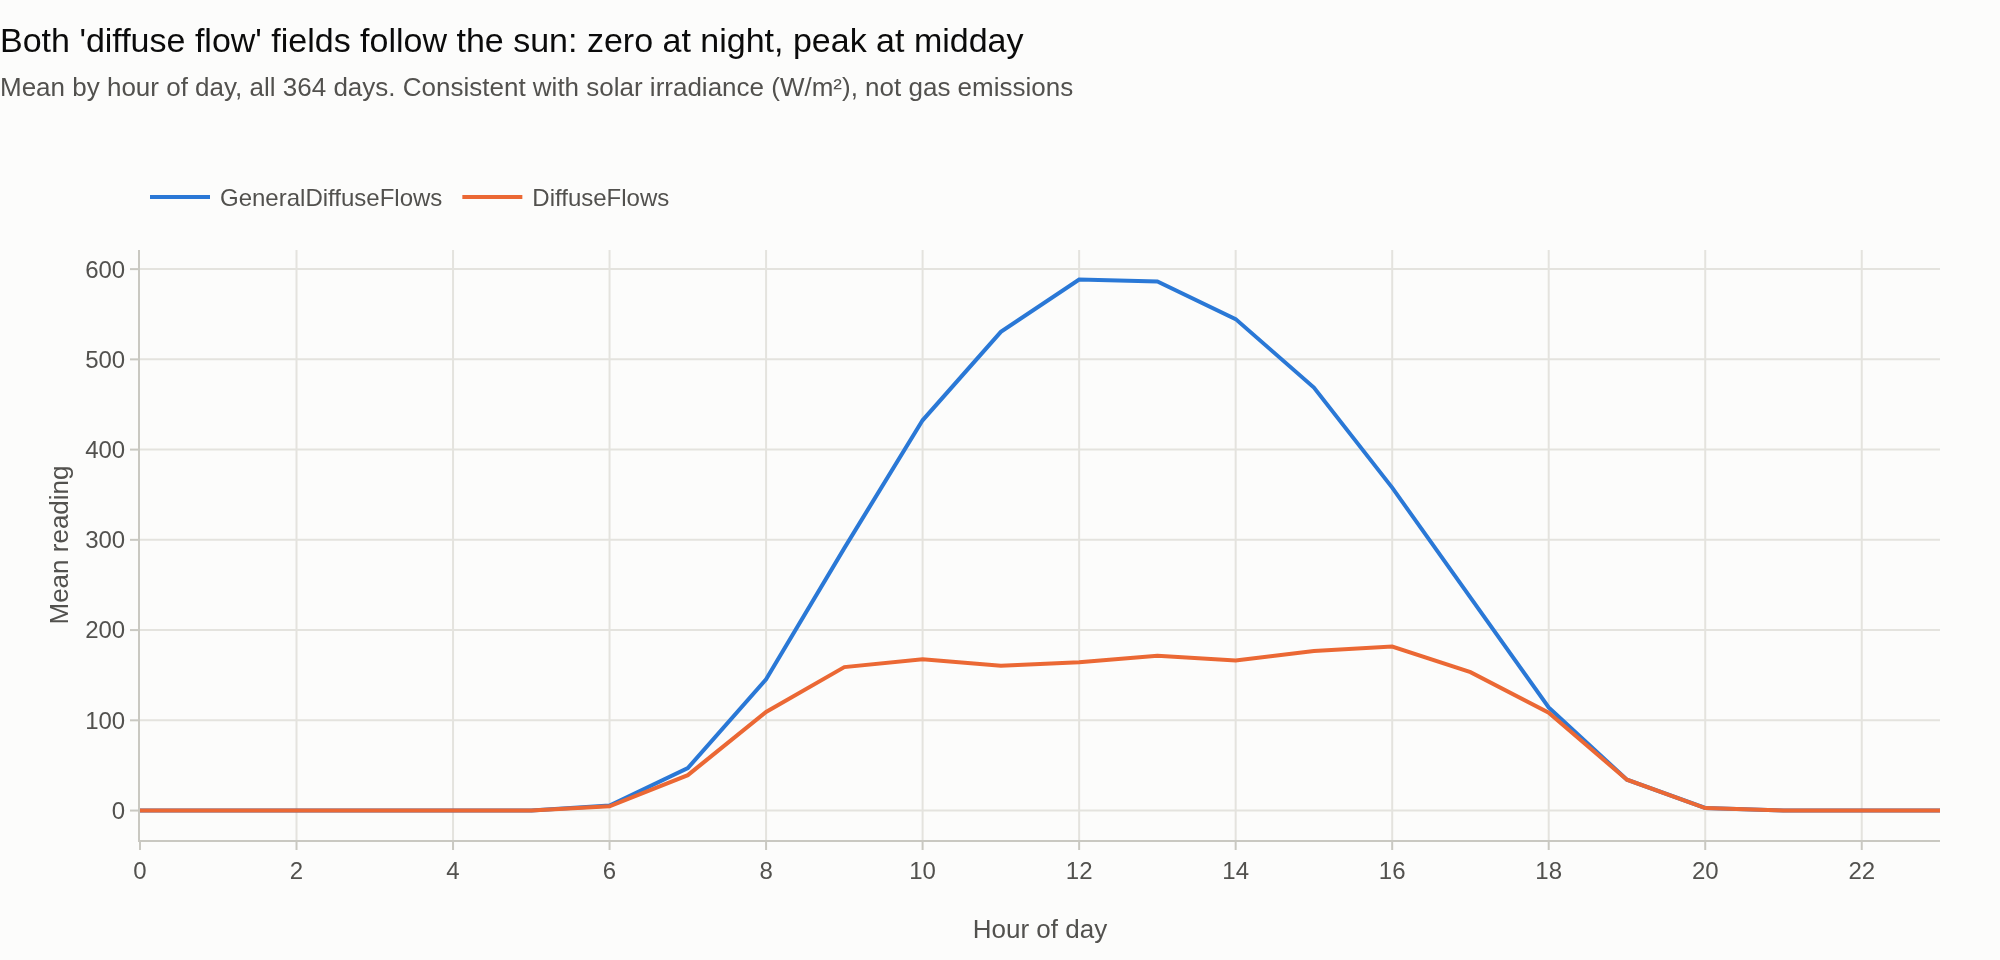

In [4]:
by_hour = raw.assign(Hour=pp.parse_datetime(raw["Datetime"]).dt.hour).groupby("Hour")[pp.IRRADIANCE]
irr = pd.DataFrame({"GDF mean": by_hour.mean()["GeneralDiffuseFlows"],
                    "DF mean": by_hour.mean()["DiffuseFlows"]})
night = irr.loc[[0, 1, 2, 3, 4, 22, 23]].mean()
print(f"Mean at night (22:00-04:59): GDF {night['GDF mean']:.2f}, DF {night['DF mean']:.2f}")
print(f"Maximum: GDF {raw.GeneralDiffuseFlows.max():.0f}, DF {raw.DiffuseFlows.max():.0f}")
daylight = raw[raw.GeneralDiffuseFlows > 50]
print(f"Hour of the highest mean: GDF {irr['GDF mean'].idxmax()}:00, DF {irr['DF mean'].idxmax()}:00")
print(f"In daylight (GDF > 50), DF exceeds GDF in {(daylight.DiffuseFlows > daylight.GeneralDiffuseFlows).mean():.1%} of readings")

fig = go.Figure()
fig.add_scatter(x=irr.index, y=irr["GDF mean"], name="GeneralDiffuseFlows", line_color=ch.ACCENT)
fig.add_scatter(x=irr.index, y=irr["DF mean"], name="DiffuseFlows", line_color=ch.SECOND)
fig.update_layout(title=ch.title("Both 'diffuse flow' fields follow the sun: zero at night, peak at midday",
                                 "Mean by hour of day, all 364 days. Consistent with solar irradiance (W/m²), not gas emissions"),
                  xaxis_title="Hour of day", yaxis_title="Mean reading", hovermode="x unified")
fig.update_xaxes(dtick=2)
ch.save(fig, "01_diffuse_flows_by_hour", height=480);

WindSpeed
below 0.5     61.1%
0.5 to 4.5     0.3%
above 4.5     38.6%


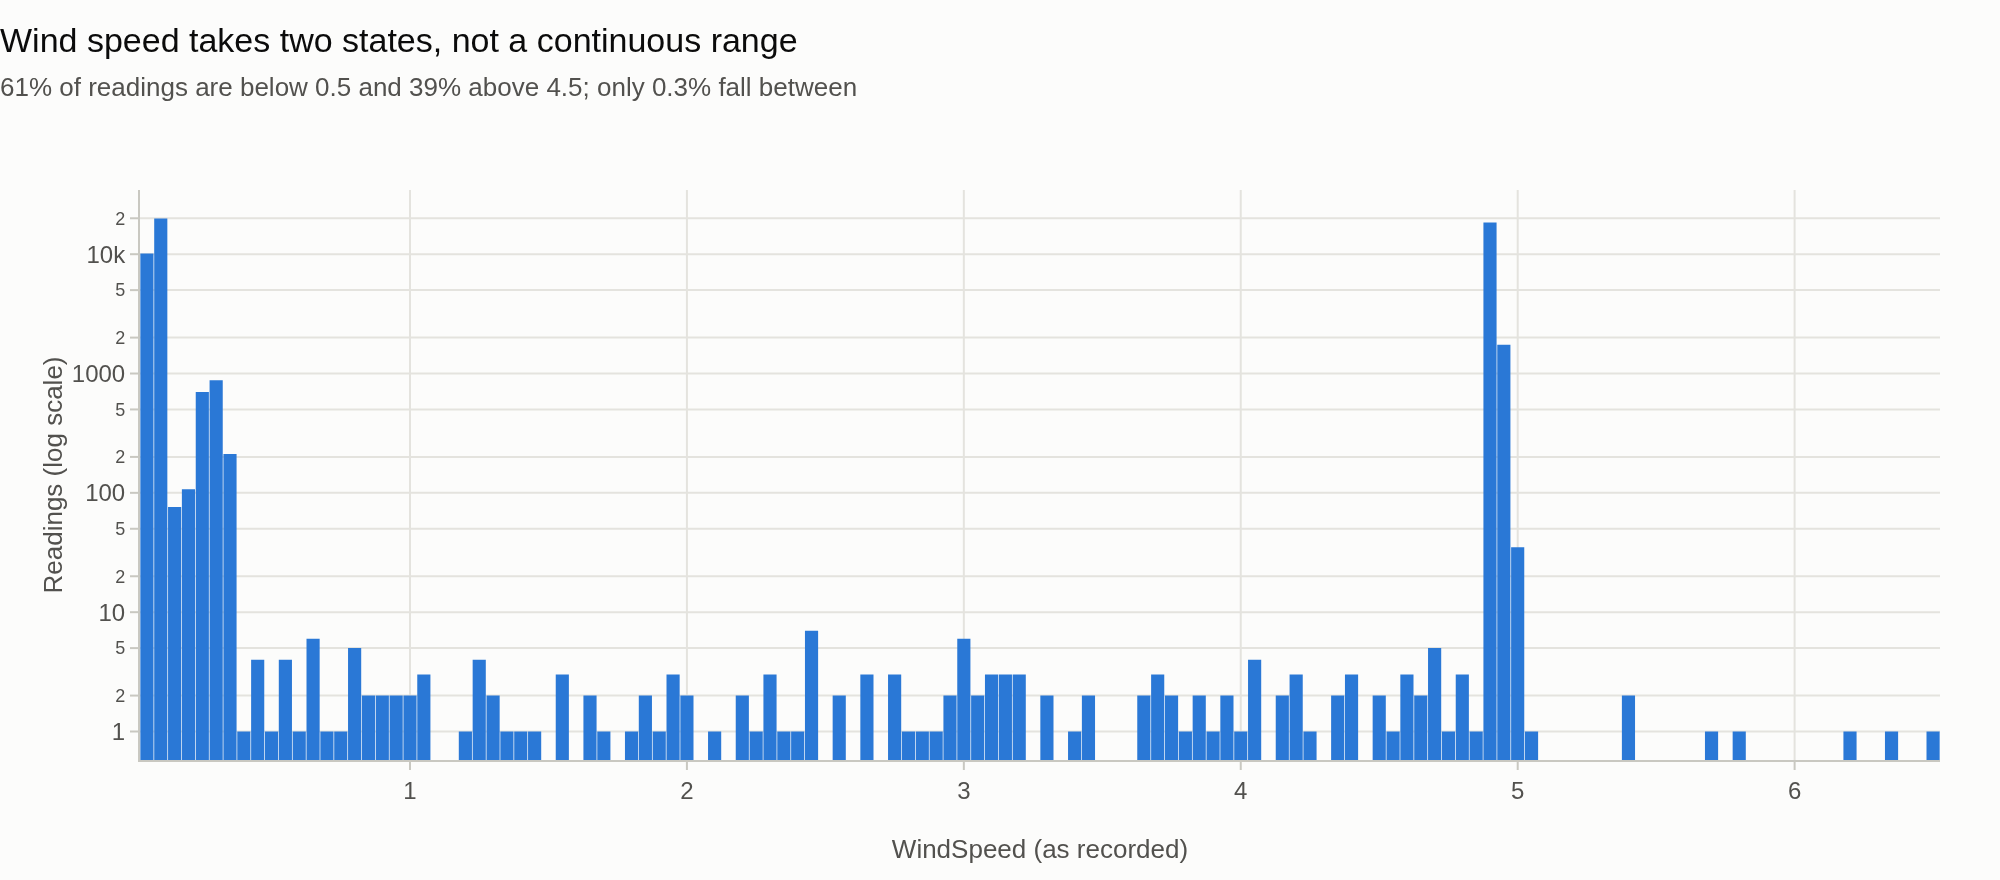

In [5]:
w = raw["WindSpeed"]
bands = pd.cut(w, [0, 0.5, 4.5, 10], labels=["below 0.5", "0.5 to 4.5", "above 4.5"]).value_counts().sort_index()
print((bands / len(w)).map("{:.1%}".format).to_string())
fig = go.Figure(go.Histogram(x=w, nbinsx=130, marker_color=ch.ACCENT))
fig.update_layout(title=ch.title("Wind speed takes two states, not a continuous range",
                                 f"{bands.iloc[0]/len(w):.0%} of readings are below 0.5 and {bands.iloc[2]/len(w):.0%} above 4.5; only {bands.iloc[1]/len(w):.1%} fall between"),
                  xaxis_title="WindSpeed (as recorded)", yaxis_title="Readings", bargap=0.05)
fig.update_yaxes(type="log", title_text="Readings (log scale)")
ch.save(fig, "02_wind_speed_distribution", height=440);

**Diffuse flows.** The dictionary's "emission gases diffusing into the atmosphere" does not fit the data. Both fields are essentially zero every night, rise after sunrise and peak in daylight, and their maximum of 1,163 is close to clear-sky solar irradiance at ground level in W/m². They are solar-radiation readings. `GeneralDiffuseFlows` behaves like global irradiance, peaking at noon. `DiffuseFlows` does **not** behave exactly like textbook diffuse irradiance: it peaks at 16:00 and exceeds the "general" value in about 15% of daylight readings, which diffuse irradiance cannot physically do. Their exact definition cannot be established from the file. They are therefore not interpreted physically. `GeneralDiffuseFlows` is used only as a daylight control in Section 6.5, and neither field is part of the brief's three environmental variables.

**Wind speed.** 99.7% of readings are either about 0.08 or about 4.9. A real wind-speed series measured in km/h would be continuous. This looks like a sensor or logging state (for example, a station switching between two modes), so the unit is treated as unreliable. Wind is analysed both as recorded and as a **two-state variable** (high if > 2).

**Humidity** behaves as relative humidity in % (11 to 95). **Temperature** is plausible for northern Morocco (3 to 40 °C).

The table below records the review and is saved as `Outputs/data_dictionary_review.csv`.

In [6]:
dict_review = pd.DataFrame([
    ("Datetime", "Date and time of the recording", "Start of each 10-minute interval, local time zone not stated", "Parsed with an explicit month/day/year format"),
    ("Temperature", "Temperature in Celsius", "Plausible (3 to 40 °C)", "Used as recorded"),
    ("Humidity", "Concentration of water vapour", "Values 11 to 95 behave as relative humidity (%)", "Treated as relative humidity, %"),
    ("WindSpeed", "Speed of the wind in km/h", "Two states (about 0.08 and about 4.9); a range this narrow is not plausible as km/h", "Analysed as a two-state variable (High > 2) as well as numerically; unit treated as uncertain"),
    ("GeneralDiffuseFlows", "Emission gases diffusing into the broader atmosphere", "Zero at night, peaks at noon, up to 1,163 (close to clear-sky solar irradiance in W/m²)", "Treated as solar irradiance (likely W/m²); used only as a daylight control in 6.5"),
    ("DiffuseFlows", "Emission gases diffusing into the local atmosphere", "Zero at night and solar-shaped, but peaks at 16:00 and exceeds GDF in 15% of daylight readings, which diffuse irradiance cannot do", "Treated as a solar-radiation reading of uncertain definition; not used in conclusions"),
    ("PowerConsumption_Zone1-3", "Power consumption in kWh", "Magnitudes match average load in kW, not energy per 10 minutes", "Treated as average load (kW); energy only derived as mean kW × hours"),
], columns=["Field", "Dictionary says", "What the data shows", "Treatment in this analysis"])
dict_review.to_csv(OUT / "data_dictionary_review.csv", index=False)
dict_review

,Field,Dictionary says,What the data shows,Treatment in this analysis
0,Datetime,Date and time of the recording,"Start of each 10-minute interval, local time z...",Parsed with an explicit month/day/year format
1,Temperature,Temperature in Celsius,Plausible (3 to 40 °C),Used as recorded
2,Humidity,Concentration of water vapour,Values 11 to 95 behave as relative humidity (%),"Treated as relative humidity, %"
3,WindSpeed,Speed of the wind in km/h,Two states (about 0.08 and about 4.9); a range...,Analysed as a two-state variable (High > 2) as...
4,GeneralDiffuseFlows,Emission gases diffusing into the broader atmo...,"Zero at night, peaks at noon, up to 1,163 (clo...",Treated as solar irradiance (likely W/m²); use...
5,DiffuseFlows,Emission gases diffusing into the local atmosp...,"Zero at night and solar-shaped, but peaks at 1...",Treated as a solar-radiation reading of uncert...
6,PowerConsumption_Zone1-3,Power consumption in kWh,"Magnitudes match average load in kW, not energ...",Treated as average load (kW); energy only deri...


## 2. Data inspection (Task 1)

Structure, data types, missing values, duplicates, timestamp regularity and unusual values. Nothing is changed in this section.

In [7]:
print("Shape:", raw.shape)
raw.info()
raw.head()

Shape: (52416, 9)
<class 'pandas.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Datetime                52416 non-null  str    
 1   Temperature             52416 non-null  float64
 2   Humidity                52416 non-null  float64
 3   WindSpeed               52416 non-null  float64
 4   GeneralDiffuseFlows     52416 non-null  float64
 5   DiffuseFlows            52416 non-null  float64
 6   PowerConsumption_Zone1  52416 non-null  float64
 7   PowerConsumption_Zone2  52416 non-null  float64
 8   PowerConsumption_Zone3  52416 non-null  float64
dtypes: float64(8), str(1)
memory usage: 3.6 MB


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.800,0.083,0.051,0.119,"34,055.696","16,128.875","20,240.964"
1,1/1/2017 0:10,6.414,74.500,0.083,0.070,0.085,"29,814.684","19,375.076","20,131.084"
2,1/1/2017 0:20,6.313,74.500,0.080,0.062,0.100,"29,128.101","19,006.687","19,668.434"
3,1/1/2017 0:30,6.121,75.000,0.083,0.091,0.096,"28,228.861","18,361.094","18,899.277"
4,1/1/2017 0:40,5.921,75.700,0.081,0.048,0.085,"27,335.696","17,872.340","18,442.410"


In [8]:
missing = raw.isna().sum()
dup_rows = int(raw.duplicated().sum())
ts = pp.parse_datetime(raw["Datetime"])
intervals = pp.interval_summary(ts)
print("Missing values per column:", missing.to_dict())
print("Fully duplicated rows:", dup_rows)
pd.Series(intervals)

Missing values per column: {'Datetime': 0, 'Temperature': 0, 'Humidity': 0, 'WindSpeed': 0, 'GeneralDiffuseFlows': 0, 'DiffuseFlows': 0, 'PowerConsumption_Zone1': 0, 'PowerConsumption_Zone2': 0, 'PowerConsumption_Zone3': 0}
Fully duplicated rows: 0


first                   2017-01-01 00:00:00
last                    2017-12-30 23:50:00
n_timestamps                          52416
expected_timestamps                   52416
missing_timestamps                        0
duplicate_timestamps                      0
n_gap_10min                           52415
n_gap_other                               0
is_monotonic                           True
dtype: object

In [9]:
named = raw.rename(columns=pp.ZONE_COLUMNS)
quality = pd.DataFrame({
    "min": named.drop(columns="Datetime").min(),
    "max": named.drop(columns="Datetime").max(),
    "zeros": (named.drop(columns="Datetime") == 0).sum(),
    "out_of_plausible_range": pd.Series(pp.out_of_range_counts(named)),
    "longest_constant_run": named.drop(columns="Datetime").apply(pp.longest_constant_run),
})
quality

,min,max,zeros,out_of_plausible_range,longest_constant_run
Temperature,3.247,40.010,0,0,4
Humidity,11.340,94.800,0,0,9
WindSpeed,0.050,6.483,0,0,7
GeneralDiffuseFlows,0.004,"1,163.000",0,0,5
DiffuseFlows,0.011,936.000,0,0,5
Zone1,"13,895.696","52,204.395",0,0,3
Zone2,"8,560.081","37,408.861",0,0,3
Zone3,"5,935.174","47,598.326",0,0,3


In [10]:
df = pp.prepare(raw)
s10 = df.set_index("Datetime")
spikes = pd.DataFrame({
    "flagged_readings": [int(df[f"{z}_spike"].sum()) for z in ZONES],
    "share": [df[f"{z}_spike"].mean() for z in ZONES],
    "largest_10min_change_kW": [s10[z].diff().abs().max() for z in ZONES],
    "when": [s10[z].diff().abs().idxmax() for z in ZONES],
}, index=ZONES)
spikes

,flagged_readings,share,largest_10min_change_kW,when
Zone1,214,0.004,"19,344.672",2017-04-20 12:10:00
Zone2,140,0.003,"7,813.440",2017-12-11 11:00:00
Zone3,179,0.003,"7,133.724",2017-07-24 19:40:00


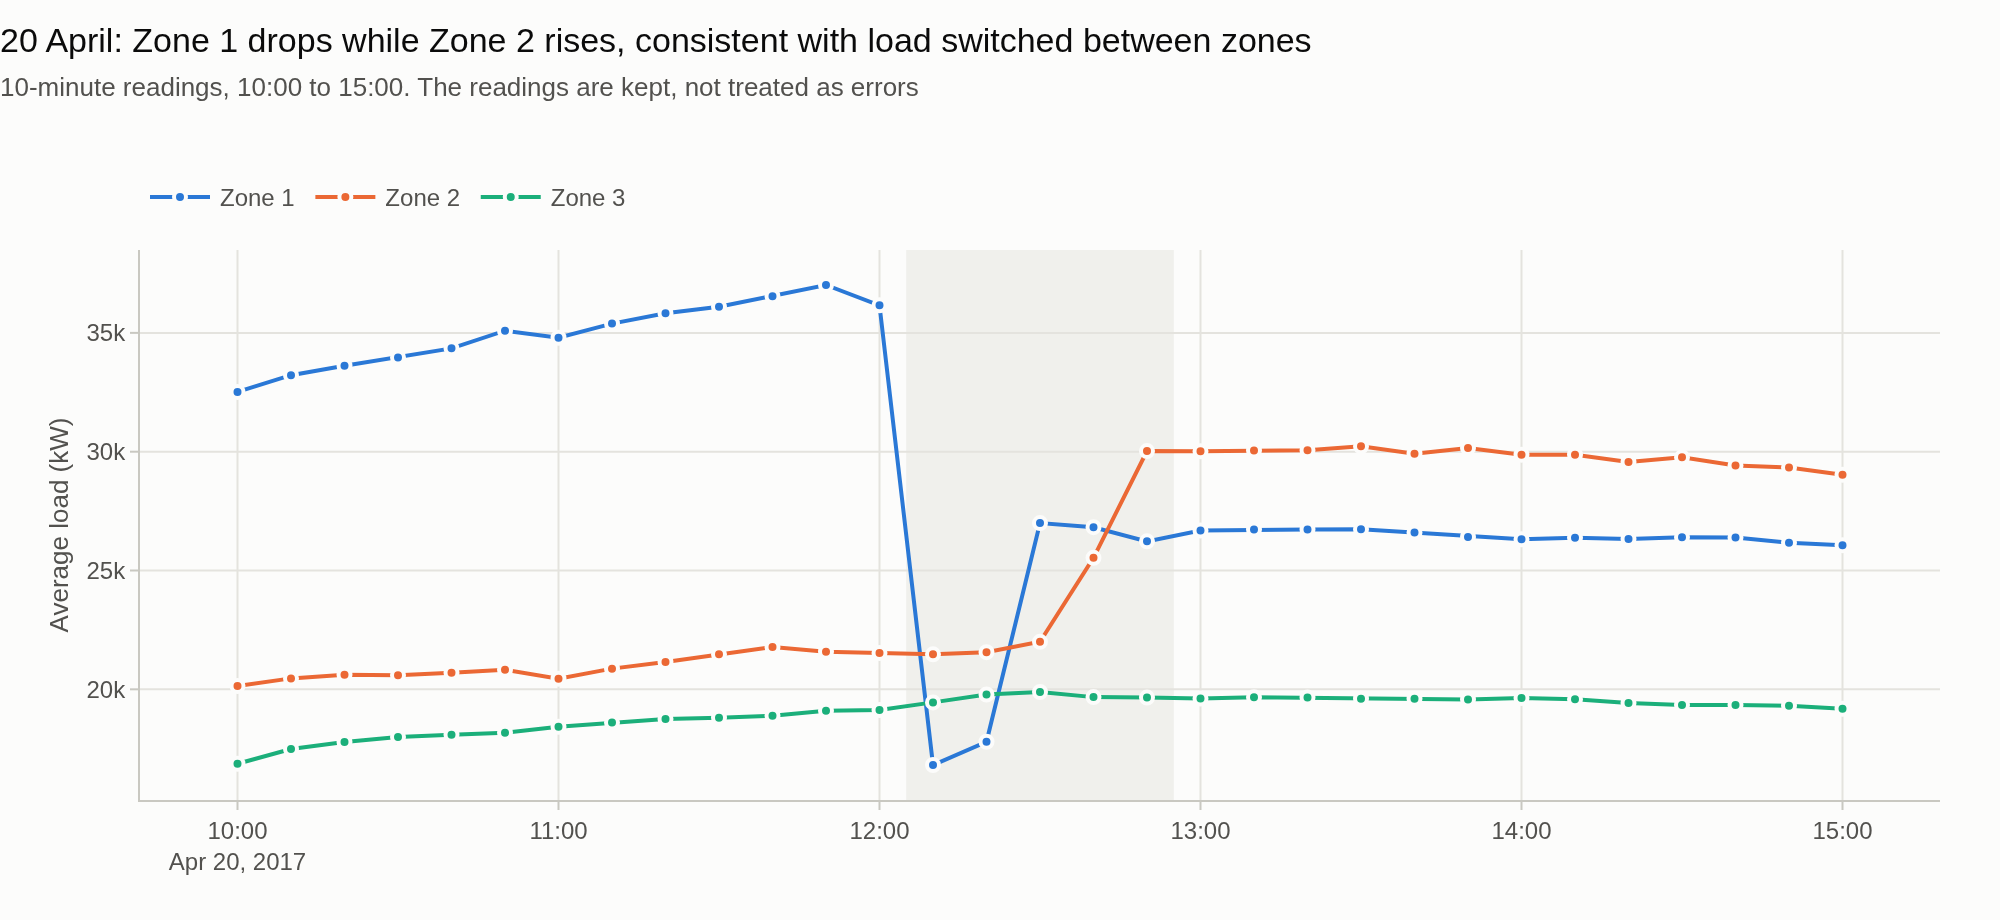

Mean after (13:00-15:00) minus before (10:00-12:00), kW:
Zone1   -8,513.000
Zone2    8,857.000
Zone3    1,188.000


In [11]:
win = s10.loc["2017-04-20 10:00":"2017-04-20 15:00", ZONES]
fig = go.Figure()
for z in ZONES:
    fig.add_scatter(x=win.index, y=win[z], name=ZN(z), mode="lines+markers",
                    line_color=ch.ZONE_COLORS[z], marker=dict(size=6))
fig.add_vrect(x0="2017-04-20 12:05", x1="2017-04-20 12:55", fillcolor=ch.GRID, opacity=0.5, line_width=0, layer="below")
fig.update_layout(title=ch.title("20 April: Zone 1 drops while Zone 2 rises, consistent with load switched between zones",
                                 "10-minute readings, 10:00 to 15:00. The readings are kept, not treated as errors"),
                  xaxis_title=None, hovermode="x unified")
ch.kw_axis(fig)
ch.save(fig, "03_load_transfer_20_april", height=460);
change = win.loc["2017-04-20 13:00":"2017-04-20 15:00"].mean() - win.loc["2017-04-20 10:00":"2017-04-20 12:00"].mean()
print("Mean after (13:00-15:00) minus before (10:00-12:00), kW:")
print(change.round(0).to_string())

In [12]:
dq = pd.DataFrame([
    ("Rows", len(raw), "52,416 readings = 364 days × 144"),
    ("Columns", raw.shape[1], "As listed in the dictionary"),
    ("Missing values", int(missing.sum()), "None in any column"),
    ("Fully duplicated rows", dup_rows, ""),
    ("Duplicate timestamps", intervals["duplicate_timestamps"], ""),
    ("Missing 10-minute timestamps", intervals["missing_timestamps"], "Between first and last reading"),
    ("Irregular intervals", intervals["n_gap_other"], "Every step is exactly 10 minutes"),
    ("Period", f"{intervals['first']:%d %b %Y %H:%M} to {intervals['last']:%d %b %Y %H:%M}", "31 December is not in the file"),
    ("Out-of-range readings", int(quality["out_of_plausible_range"].sum()), "Against the plausible ranges in power_prep.py"),
    ("Spike readings flagged (all zones)", int(spikes["flagged_readings"].sum()), "Kept; tested in Section 8"),
    ("Dictionary issues", 4, "Load unit, two irradiance fields, wind unit (Section 1)"),
], columns=["Check", "Result", "Note"])
dq.to_csv(OUT / "data_quality_summary.csv", index=False)
key("n_rows", len(raw), "Rows in the raw file")
dq

,Check,Result,Note
0,Rows,52416,"52,416 readings = 364 days × 144"
1,Columns,9,As listed in the dictionary
2,Missing values,0,None in any column
3,Fully duplicated rows,0,
4,Duplicate timestamps,0,
5,Missing 10-minute timestamps,0,Between first and last reading
6,Irregular intervals,0,Every step is exactly 10 minutes
7,Period,01 Jan 2017 00:00 to 30 Dec 2017 23:50,31 December is not in the file
8,Out-of-range readings,0,Against the plausible ranges in power_prep.py
9,Spike readings flagged (all zones),533,Kept; tested in Section 8


**The file is complete and regular.** There are no missing values, duplicate rows or duplicate timestamps. Every step is exactly 10 minutes, and no reading is out of range. The year runs from 1 January to 30 December 2017 (364 days); **31 December is not in the file**, so "annual" figures here cover 364 days.

**Unusual values.** No value is impossible. The neighbour-median rule flags 0.3% to 0.4% of readings per zone as abrupt departures. The largest single change is a 19.3 MW drop in Zone 1 at 12:10 on 20 April. The chart shows what happened: Zone 1 fell and stayed about 8.5 MW lower, while Zone 2 rose by about 8.9 MW within 40 minutes. That is the signature of **load being switched from one zone's network to another's**, not a measurement error. The flagged readings are therefore **kept** and marked (`Zone*_spike`), and Section 8 shows the results do not change when they are removed. The longest run of identical consecutive load values is 3 readings, so there are no stuck sensors.

## 3. Data preparation and aggregation

`pp.prepare()` parses the timestamps, gives the zone columns short names (`Zone1` to `Zone3`), and adds the time features required by the brief (Year, Month, Day, Hour, day of week, Date), plus a weekend flag, a Ramadan flag, a public-holiday label, the two-state wind variable and the spike flags. **No reading is removed or modified.** `pp.aggregate()` then averages the readings to hourly and daily series.

In [13]:
hourly = pp.aggregate(df, "h")
daily = pp.aggregate(df, "D")
assert (hourly["n_readings"] == 6).all() and (daily["n_readings"] == 144).all()
print(f"10-minute: {len(df):,} rows | hourly: {len(hourly):,} rows | daily: {len(daily)} rows")
print("Every hour has 6 readings and every day has 144, so no aggregate is based on partial data.")

df.drop(columns=[]).to_csv(CLEAN / "power_clean_10min.csv", index=False)
hourly.to_csv(OUT / "hourly_consumption.csv", index=False)
daily.to_csv(OUT / "daily_consumption.csv", index=False)
df[["Datetime", "Year", "Month", "Day", "Hour", "DayName", "Date", "IsRamadan", "Holiday", "Zone1", "Zone2", "Zone3", "Total"]].head()

10-minute: 52,416 rows | hourly: 8,736 rows | daily: 364 rows
Every hour has 6 readings and every day has 144, so no aggregate is based on partial data.


,Datetime,Year,Month,Day,Hour,DayName,Date,IsRamadan,Holiday,Zone1,Zone2,Zone3,Total
0,2017-01-01 00:00:00,2017,1,1,0,Sunday,2017-01-01,False,New Year's Day,"34,055.696","16,128.875","20,240.964","70,425.535"
1,2017-01-01 00:10:00,2017,1,1,0,Sunday,2017-01-01,False,New Year's Day,"29,814.684","19,375.076","20,131.084","69,320.844"
2,2017-01-01 00:20:00,2017,1,1,0,Sunday,2017-01-01,False,New Year's Day,"29,128.101","19,006.687","19,668.434","67,803.222"
3,2017-01-01 00:30:00,2017,1,1,0,Sunday,2017-01-01,False,New Year's Day,"28,228.861","18,361.094","18,899.277","65,489.232"
4,2017-01-01 00:40:00,2017,1,1,0,Sunday,2017-01-01,False,New Year's Day,"27,335.696","17,872.340","18,442.410","63,650.446"


**Aggregation choice.** The analysis uses three resolutions, each for a reason:

- **Hourly means (8,736 hours)** are the main series for the time-series work. An hour keeps the full daily cycle, which is the dominant pattern, and removes the 10-minute switching noise. It also matches how load is usually scheduled and traded. With a period of 24, it suits an MSTL decomposition with daily (24 h) and weekly (168 h) seasonality.
- **Daily means (364 days)** are used for questions about days: day-of-week and month comparisons, the temperature change-point model, and paired zone tests. Daily values remove the daily cycle, which would otherwise dominate any correlation with weather.
- **The 10-minute readings** are kept for the descriptive statistics (Task 2), because they describe the actual operating range, including short peaks that hourly averaging smooths away.

Because the readings are average loads, **the mean is the correct aggregate**: the hourly mean is the average load in that hour. Every hour has all 6 readings and every day all 144, so no aggregate is based on partial data.

**Files written:** `Data/Cleaned/power_clean_10min.csv` (all readings with time features and flags; not committed because of its size, and rebuilt by this notebook), `Outputs/hourly_consumption.csv` and `Outputs/daily_consumption.csv`.

## 4. Statistical summary (Task 2)

Descriptive statistics of the 10-minute readings for each zone and for the three-zone total. Variance and standard deviation use the sample formula (ddof = 1). The coefficient of variation (CV = SD / mean) compares variability across zones of different size. The load factor (mean / maximum) is the share of peak capacity used on average, a standard utility measure.

In [14]:
desc10 = pp.describe_zones(df, ZONES + ["Total"])
desc_h = pp.describe_zones(hourly, ZONES + ["Total"])
desc_d = pp.describe_zones(daily, ZONES + ["Total"])
desc10.to_csv(OUT / "descriptive_stats_10min.csv")
desc_h.to_csv(OUT / "descriptive_stats_hourly.csv")
desc_d.to_csv(OUT / "descriptive_stats_daily.csv")
for z in ZONES + ["Total"]:
    for stat in ["mean", "median", "std", "min", "max", "q1", "q3"]:
        key(f"{z}_{stat}", desc10.loc[z, stat], f"{z} {stat} of 10-minute readings (kW)")
show = desc10.T.copy()
show.loc[["n", "mean", "median", "min", "max", "range", "std", "q1", "q3", "iqr", "p5", "p95", "sem"]] = \
    show.loc[["n", "mean", "median", "min", "max", "range", "std", "q1", "q3", "iqr", "p5", "p95", "sem"]].round(0)
show

,Zone1,Zone2,Zone3,Total
n,"52,416.000","52,416.000","52,416.000","52,416.000"
mean,"32,345.000","21,043.000","17,835.000","71,223.000"
median,"32,266.000","20,823.000","16,415.000","69,789.000"
min,"13,896.000","8,560.000","5,935.000","36,785.000"
max,"52,204.000","37,409.000","47,598.000","134,208.000"
range,"38,309.000","28,849.000","41,663.000","97,423.000"
std,"7,131.000","5,201.000","6,622.000","17,143.000"
variance,"50,844,922.482","27,055,247.428","43,853,070.602","293,887,213.528"
q1,"26,311.000","16,981.000","13,129.000","56,499.000"
q3,"37,309.000","24,714.000","21,624.000","83,749.000"


In [15]:
compare = pd.DataFrame({
    "10-min SD": desc10["std"], "hourly SD": desc_h["std"], "daily SD": desc_d["std"],
    "10-min CV": desc10["cv"], "daily CV": desc_d["cv"],
    "share of variance between days": desc_d["variance"] / desc10["variance"],
}).loc[ZONES]
energy = pd.Series({z: pp.energy_mwh(desc10.loc[z, "mean"], 364 * 24) for z in ZONES + ["Total"]},
                   name="Derived energy over 364 days (MWh)")
display(compare)
display(energy.round(0).to_frame())

,10-min SD,hourly SD,daily SD,10-min CV,daily CV,share of variance between days
Zone1,"7,130.563","7,068.920","2,669.368",0.220,0.083,0.140
Zone2,"5,201.466","5,165.178","2,708.561",0.247,0.129,0.271
Zone3,"6,622.165","6,591.014","4,904.521",0.371,0.275,0.549


,Derived energy over 364 days (MWh)
Zone1,"282,566.000"
Zone2,"183,827.000"
Zone3,"155,810.000"
Total,"622,203.000"


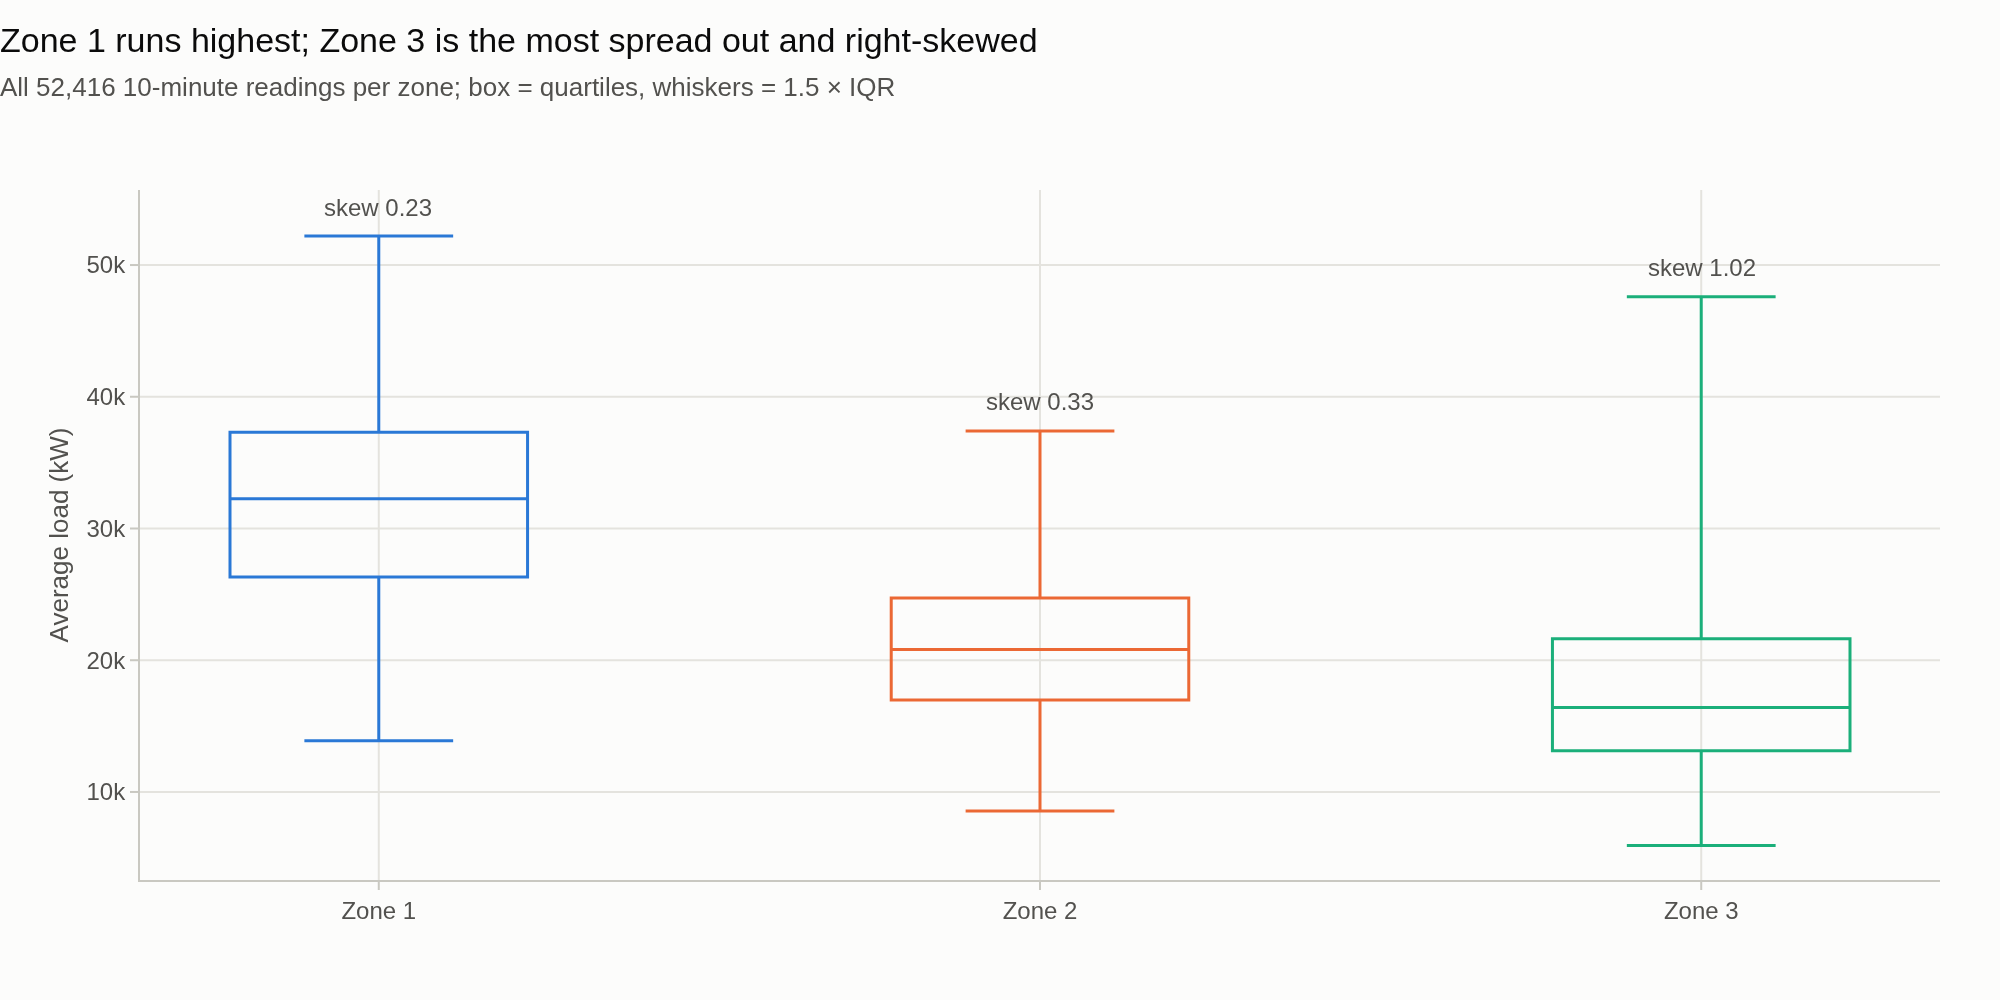

In [16]:
fig = go.Figure()
for z in ZONES:
    fig.add_trace(go.Box(y=df[z], name=ZN(z), marker_color=ch.ZONE_COLORS[z], boxpoints=False,
                         line_width=1.5, fillcolor="rgba(0,0,0,0)", width=0.45))
    fig.add_annotation(x=ZN(z), y=desc10.loc[z, "max"], text=f"skew {desc10.loc[z, 'skewness']:.2f}",
                       showarrow=False, yshift=14, font=dict(color=ch.TEXT_2, size=12))
fig.update_layout(title=ch.title("Zone 1 runs highest; Zone 3 is the most spread out and right-skewed",
                                 "All 52,416 10-minute readings per zone; box = quartiles, whiskers = 1.5 × IQR"),
                  showlegend=False)
ch.kw_axis(fig)
ch.save(fig, "04_load_distribution_by_zone", height=500);

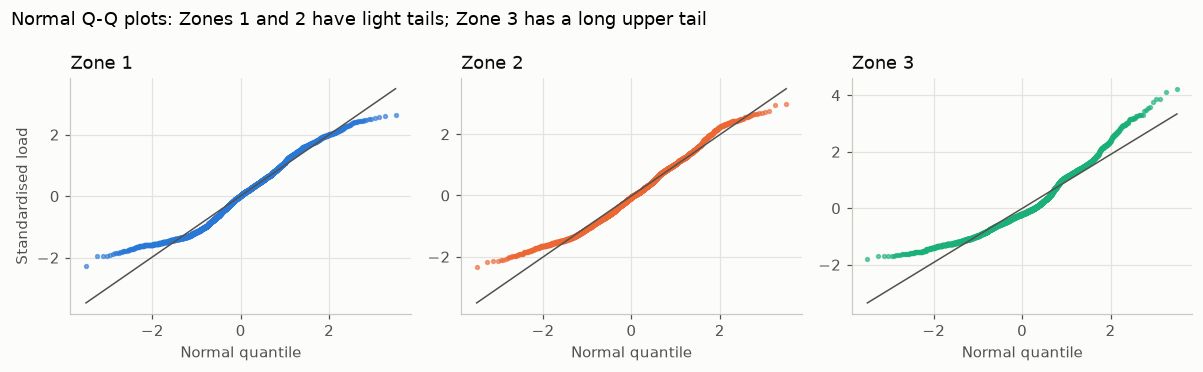

,statistic,pvalue
Zone1,"4,029.455",0.000
Zone2,"1,599.231",0.000
Zone3,"7,560.065",0.000


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
rng = np.random.default_rng(SEED)
for ax, z in zip(axes, ZONES):
    x = df[z].to_numpy()
    sample = rng.choice((x - x.mean()) / x.std(), 3000, replace=False)
    stats.probplot(sample, dist="norm", plot=ax)
    ax.get_lines()[0].set(markersize=2.5, color=ch.ZONE_COLORS[z], alpha=0.6)
    ax.get_lines()[1].set(color=ch.TEXT_2, linewidth=1)
    ax.set_title(ZN(z))
    ax.set_xlabel("Normal quantile")
    ax.set_ylabel("Standardised load" if z == "Zone1" else "")
fig.suptitle("Normal Q-Q plots: Zones 1 and 2 have light tails; Zone 3 has a long upper tail", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
ch.save_mpl(fig, "05_qq_plots")
plt.show()
normal = pd.DataFrame({z: stats.normaltest(df[z])._asdict() for z in ZONES}).T
normal

**What the statistics show**

| | Zone 1 | Zone 2 | Zone 3 |
|---|---|---|---|
| Mean load | **32.3 MW** | 21.0 MW | 17.8 MW |
| Median | 32.3 MW | 20.8 MW | 16.4 MW |
| Standard deviation | **7.1 MW** | 5.2 MW | 6.6 MW |
| Coefficient of variation | 0.22 | 0.25 | **0.37** |
| IQR | **11.0 MW** | 7.7 MW | 8.5 MW |
| Range | 13.9 to 52.2 MW | 8.6 to 37.4 MW | 5.9 to 47.6 MW |
| Skewness | 0.23 | 0.33 | **1.02** |
| Load factor (mean / max) | 0.62 | 0.56 | **0.38** |
| Share of variance between days | 14% | 27% | **55%** |
| Derived energy, 364 days | 283 GWh | 184 GWh | 156 GWh |

- **Zone 1 is the largest zone** by every level measure, and it has the largest absolute spread (SD 7.1 MW, IQR 11.0 MW), simply because it is the biggest.
- **Zone 3 is the most variable relative to its size.** Its CV (0.37) is about 1.5 times Zone 2's and 1.7 times Zone 1's. Its distribution is clearly right-skewed (mean above median by 1.4 MW, skewness 1.0) with a long upper tail: its maximum of 47.6 MW is 2.7 times its mean. Its load factor of 0.38 means its network must be sized for a peak almost three times its average use, compared with 1.6 times for Zone 1.
- **Where the variation comes from.** For Zone 1, 86% of the variance is *within* days (the daily cycle). For Zone 3, more than half (55%) is *between* days, which is the seasonal swing that Section 5 examines.
- Zones 1 and 2 have negative excess kurtosis (flatter than normal, short tails), because the daily cycle spreads readings evenly between a night trough and an evening peak. With 52,416 readings the normality test rejects for every zone, as it would for any real data. The Q-Q plots show *how* they depart, and that matters more. These departures, together with the strong serial correlation, are why rank-based and dependence-adjusted methods are used below.

## 5. Time-series analysis (Task 3)

The daily series shows the shape of the year before it is broken into hourly, weekly and monthly patterns.

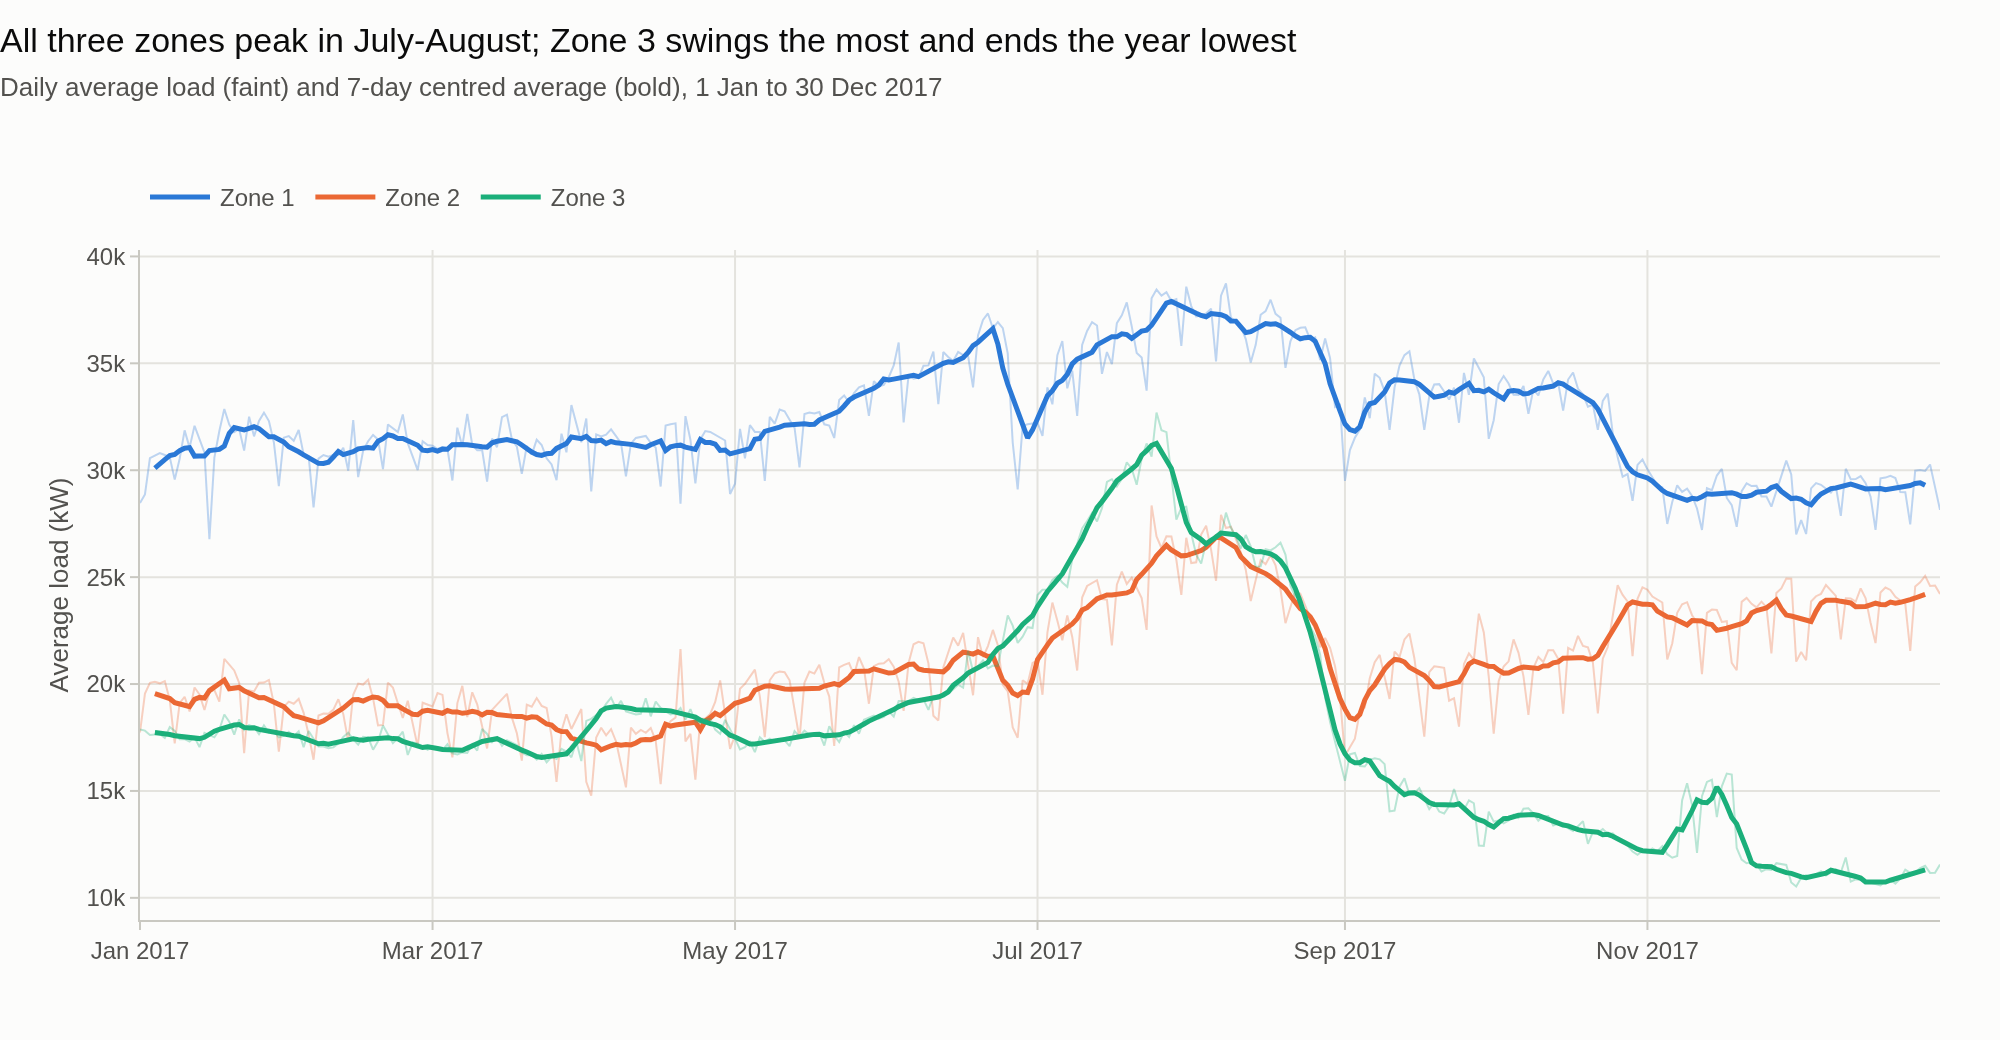

In [18]:
d_idx = daily.set_index("Datetime")
roll = d_idx[ZONES].rolling(7, center=True).mean()
fig = go.Figure()
for z in ZONES:
    fig.add_scatter(x=d_idx.index, y=d_idx[z], name=f"{ZN(z)} daily", line=dict(color=ch.ZONE_COLORS[z], width=1),
                    opacity=0.3, showlegend=False, hoverinfo="skip")
    fig.add_scatter(x=roll.index, y=roll[z], name=ZN(z), line=dict(color=ch.ZONE_COLORS[z], width=2.5))
fig.update_layout(title=ch.title("All three zones peak in July-August; Zone 3 swings the most and ends the year lowest",
                                 "Daily average load (faint) and 7-day centred average (bold), 1 Jan to 30 Dec 2017"),
                  hovermode="x unified")
ch.kw_axis(fig)
ch.save(fig, "06_daily_load_trend", height=520);

### 5.1 Hourly pattern

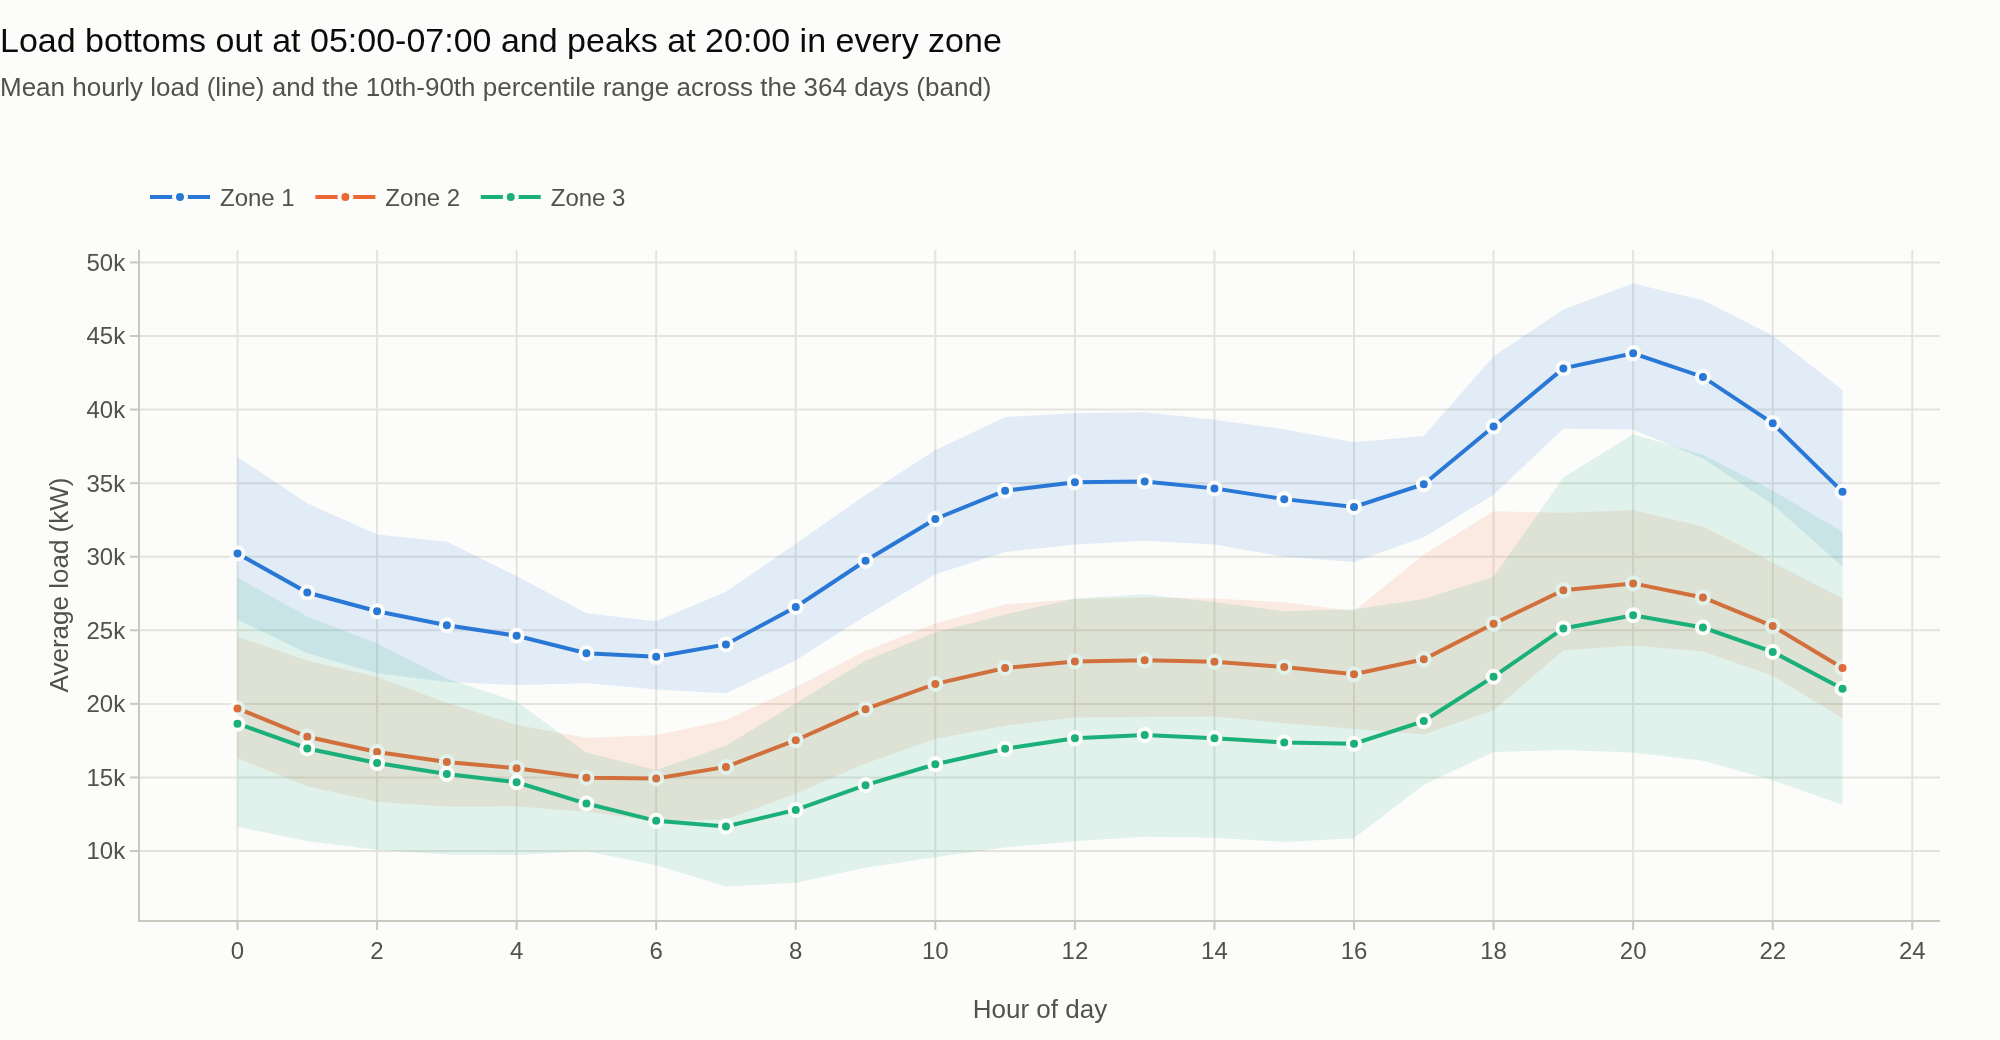

,peak_hour,peak_kW,trough_hour,trough_kW,peak_over_trough,peak_over_mean
Zone1,20,"43,822.591",6,"23,203.597",1.889,1.355
Zone2,20,"28,186.910",6,"14,934.699",1.887,1.340
Zone3,20,"26,027.609",7,"11,667.864",2.231,1.459


In [19]:
hp = hourly.groupby("Hour")[ZONES + ["Total"]].agg(["mean", lambda s: s.quantile(0.1), lambda s: s.quantile(0.9)])
hp.columns = [f"{c}_{s}".replace("<lambda_0>", "p10").replace("<lambda_1>", "p90") for c, s in hp.columns]
hourly_profile = hourly.groupby("Hour")[ZONES + ["Total"]].mean()
hourly_profile.to_csv(OUT / "hourly_profile.csv")
peak = pd.DataFrame({
    "peak_hour": hourly_profile[ZONES].idxmax(), "peak_kW": hourly_profile[ZONES].max(),
    "trough_hour": hourly_profile[ZONES].idxmin(), "trough_kW": hourly_profile[ZONES].min(),
})
peak["peak_over_trough"] = peak["peak_kW"] / peak["trough_kW"]
peak["peak_over_mean"] = peak["peak_kW"] / desc10.loc[ZONES, "mean"]
for z in ZONES:
    key(f"{z}_peak_hour", peak.loc[z, "peak_hour"], f"{z} hour of day with the highest mean load")
    key(f"{z}_trough_hour", peak.loc[z, "trough_hour"], f"{z} hour of day with the lowest mean load")
    key(f"{z}_peak_hour_mean", peak.loc[z, "peak_kW"], f"{z} mean load in its peak hour (kW)")

fig = go.Figure()
for z in ZONES:
    c = ch.ZONE_COLORS[z]
    fig.add_scatter(x=hp.index, y=hp[f"{z}_p90"], line=dict(width=0), showlegend=False, hoverinfo="skip")
    fig.add_scatter(x=hp.index, y=hp[f"{z}_p10"], line=dict(width=0), fill="tonexty",
                    fillcolor=f"rgba{tuple(int(c[i:i+2], 16) for i in (1, 3, 5)) + (0.12,)}", showlegend=False, hoverinfo="skip")
    fig.add_scatter(x=hp.index, y=hp[f"{z}_mean"], name=ZN(z), line_color=c, mode="lines+markers", marker_size=6)
fig.update_layout(title=ch.title("Load bottoms out at 05:00-07:00 and peaks at 20:00 in every zone",
                                 "Mean hourly load (line) and the 10th-90th percentile range across the 364 days (band)"),
                  xaxis_title="Hour of day", hovermode="x unified")
fig.update_xaxes(dtick=2)
ch.kw_axis(fig)
ch.save(fig, "07_hourly_profile_by_zone", height=520);
peak

### 5.2 Daily and weekly pattern

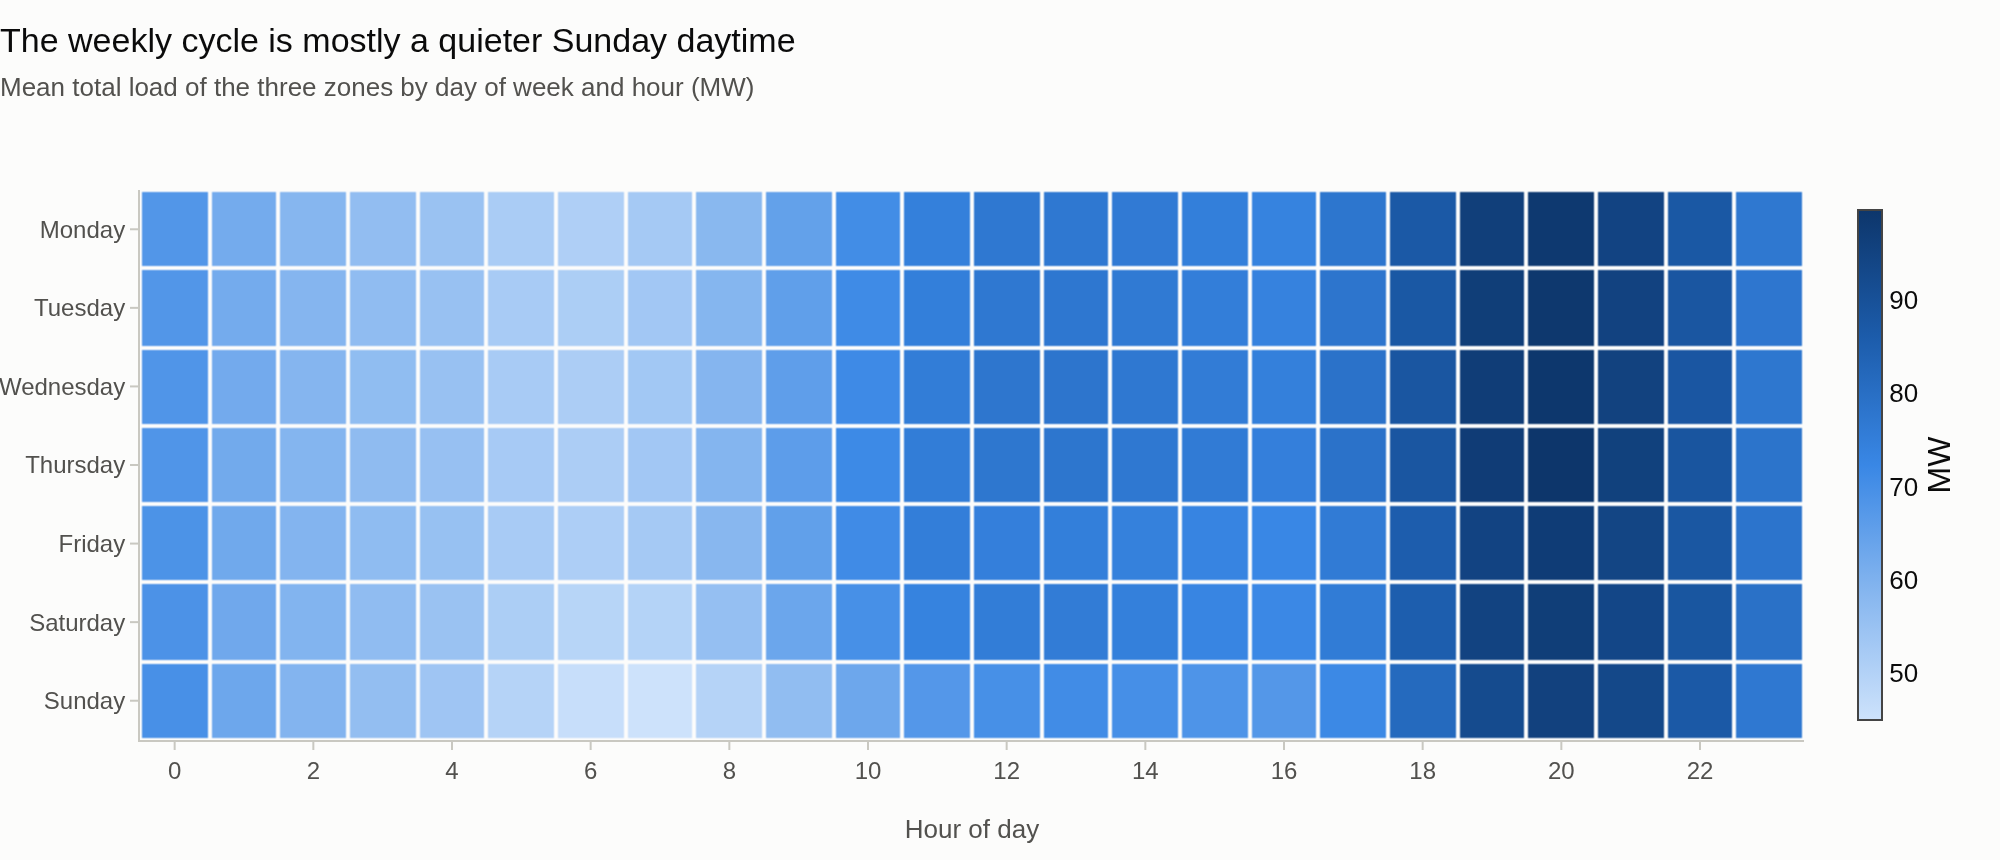

In [20]:
heat = hourly.pivot_table(index="DayName", columns="Hour", values="Total", aggfunc="mean", observed=True)
fig = go.Figure(go.Heatmap(z=heat.values / 1000, x=heat.columns, y=heat.index.astype(str), colorscale=ch.SEQUENTIAL,
                           colorbar=dict(title=dict(text="MW", side="right"), thickness=12),
                           hovertemplate="%{y} %{x}:00<br>%{z:.1f} MW<extra></extra>", xgap=2, ygap=2))
fig.update_layout(title=ch.title("The weekly cycle is mostly a quieter Sunday daytime",
                                 "Mean total load of the three zones by day of week and hour (MW)"),
                  xaxis_title="Hour of day", yaxis_autorange="reversed")
fig.update_xaxes(dtick=2, showgrid=False)
fig.update_yaxes(showgrid=False)
ch.save(fig, "08_weekday_hour_heatmap", height=430);

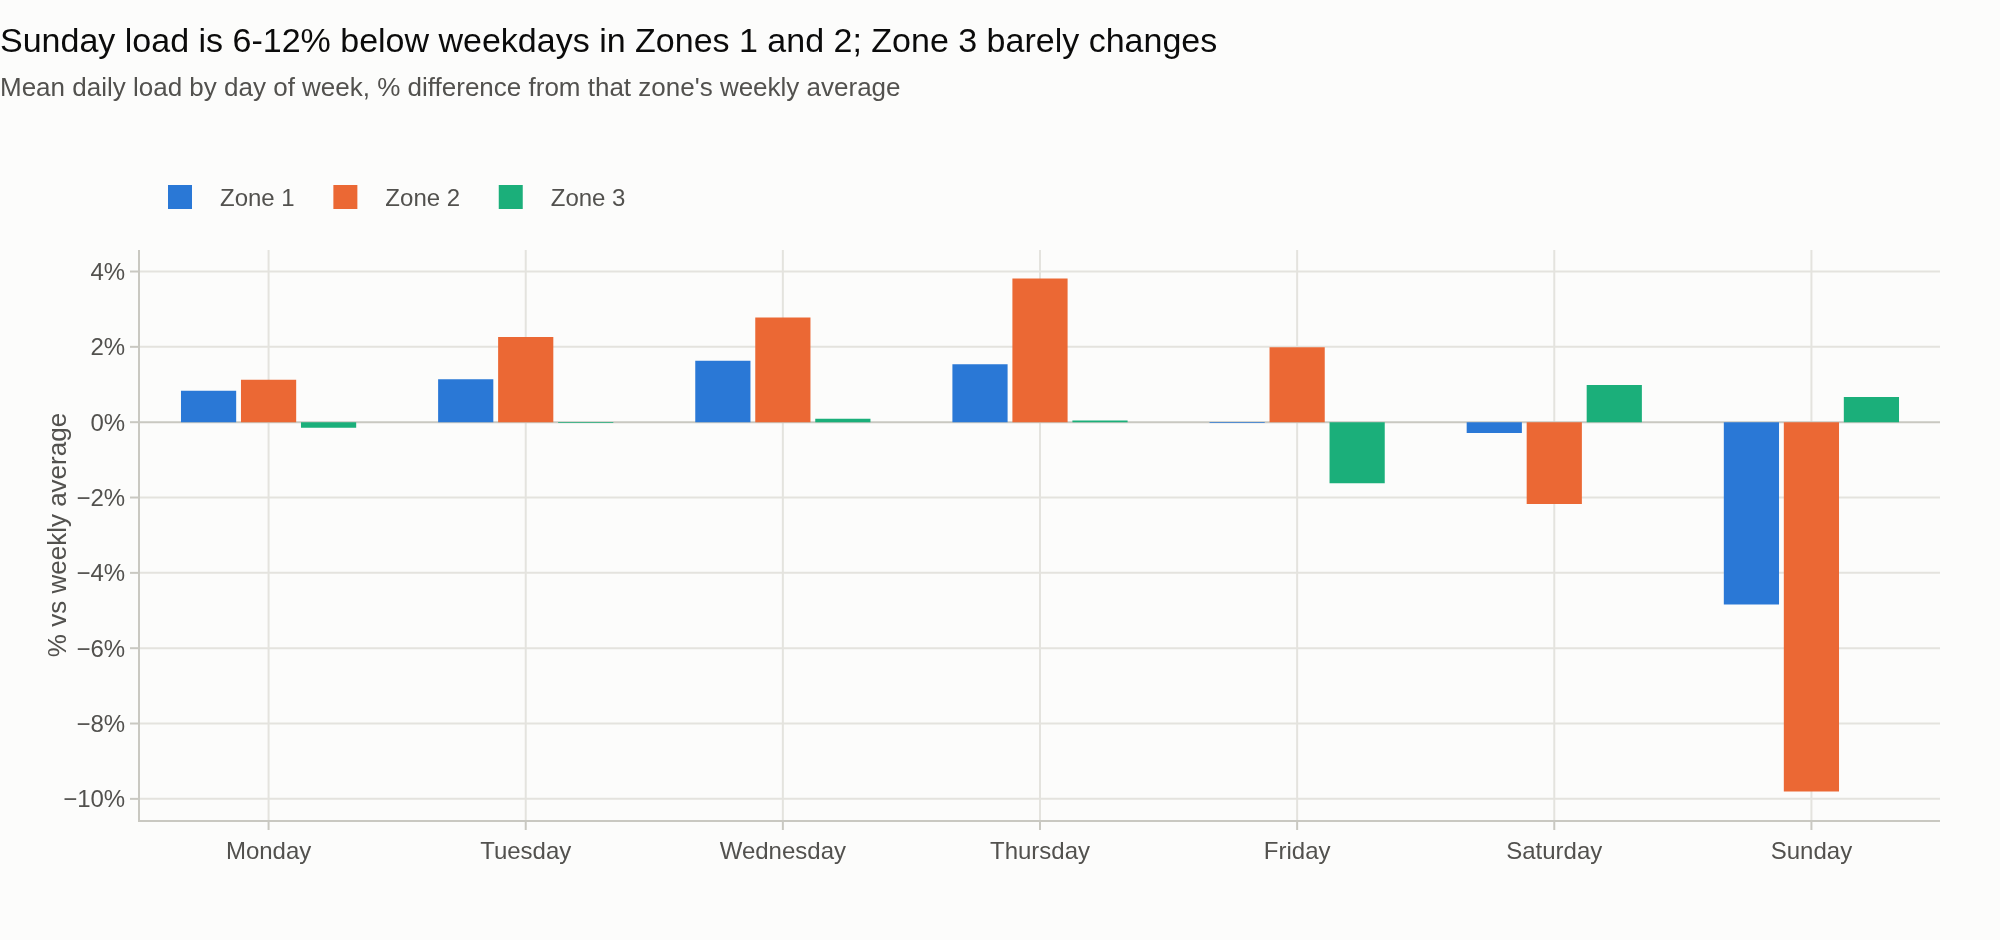

,complete_weeks,friedman_chi2,p,kendalls_W,sunday_vs_weekday_pct,sunday_wilcoxon_p,saturday_vs_weekday_pct,saturday_wilcoxon_p
zone,,,,,,,,
Zone1,52,127.335,0.000,0.408,-5.775,0.000,-1.314,0.003
Zone2,52,163.121,0.000,0.523,-11.962,0.000,-4.533,0.000
Zone3,52,35.440,0.000,0.114,0.990,0.166,1.333,0.003


In [21]:
wk = daily.groupby("DayName", observed=True)[ZONES + ["Total"]].mean()
wk_index = wk / wk.mean()
wk.to_csv(OUT / "weekday_profile.csv")
key("Total_sunday_mean", wk.loc["Sunday", "Total"], "Mean total load on Sundays (kW)")
key("Total_weekday_mean", daily.loc[daily.DayOfWeek < 5, "Total"].mean(), "Mean total load Monday-Friday (kW)")

fig = go.Figure()
for z in ZONES:
    fig.add_bar(x=wk_index.index.astype(str), y=(wk_index[z] - 1) * 100, name=ZN(z), marker_color=ch.ZONE_COLORS[z])
fig.update_layout(title=ch.title("Sunday load is 6-12% below weekdays in Zones 1 and 2; Zone 3 barely changes",
                                 "Mean daily load by day of week, % difference from that zone's weekly average"),
                  barmode="group", bargap=0.3, bargroupgap=0.08, yaxis_title="% vs weekly average")
fig.update_yaxes(zeroline=True, zerolinecolor=ch.AXIS, ticksuffix="%")
ch.save(fig, "09_day_of_week_by_zone", height=470);

rows = []
week_no = (daily["Date"] - daily["Date"].min()).dt.days // 7
for z in ZONES:
    w = daily.assign(week=week_no).pivot_table(index="week", columns="DayOfWeek", values=z).dropna()
    fr = stats.friedmanchisquare(*[w[c] for c in w.columns])
    others = w[[0, 1, 2, 3, 4]].mean(axis=1)
    wil = stats.wilcoxon(w[6], others)
    sat = stats.wilcoxon(w[5], others)
    rows.append({"zone": z, "complete_weeks": len(w), "friedman_chi2": fr.statistic, "p": fr.pvalue,
                 "kendalls_W": pp.kendalls_w(fr.statistic, len(w), 7),
                 "sunday_vs_weekday_pct": (w[6] / others - 1).mean() * 100, "sunday_wilcoxon_p": wil.pvalue,
                 "saturday_vs_weekday_pct": (w[5] / others - 1).mean() * 100, "saturday_wilcoxon_p": sat.pvalue})
weekday_tests = pd.DataFrame(rows).set_index("zone")
weekday_tests[["sunday_wilcoxon_p", "saturday_wilcoxon_p"]] = np.reshape(
    pp.holm(weekday_tests[["sunday_wilcoxon_p", "saturday_wilcoxon_p"]].to_numpy().ravel()), (3, 2))
weekday_tests.to_csv(OUT / "weekday_tests.csv")
weekday_tests

**Daily and weekly pattern.** The week is a smaller effect than the day, and it is mostly **Sunday**. Comparing each day with the Monday-Friday mean of the same week (52 weeks as blocks, Friedman test):

- **Zone 2 has the clearest weekly cycle** (Kendall's W = 0.52): Sunday is 12% below its weekday level and Saturday 4.5% below. It behaves like a zone with substantial commercial or office load.
- **Zone 1** has a moderate cycle (W = 0.41): Sunday is 6% lower, Saturday 1% lower.
- **Zone 3 has almost no weekly cycle** (W = 0.11). Sunday is not significantly different from weekdays (+1%, Holm p = 0.17), and Saturday is slightly *higher* (+1.3%). That fits a mainly residential zone, where people at home at the weekend offset closed businesses.

The heatmap shows the Sunday dip is a *daytime* effect (roughly 08:00 to 17:00). The 20:00 evening peak is almost the same every day of the week, so weekly planning matters less for peak capacity than for daytime and maintenance scheduling.

### 5.3 Monthly pattern

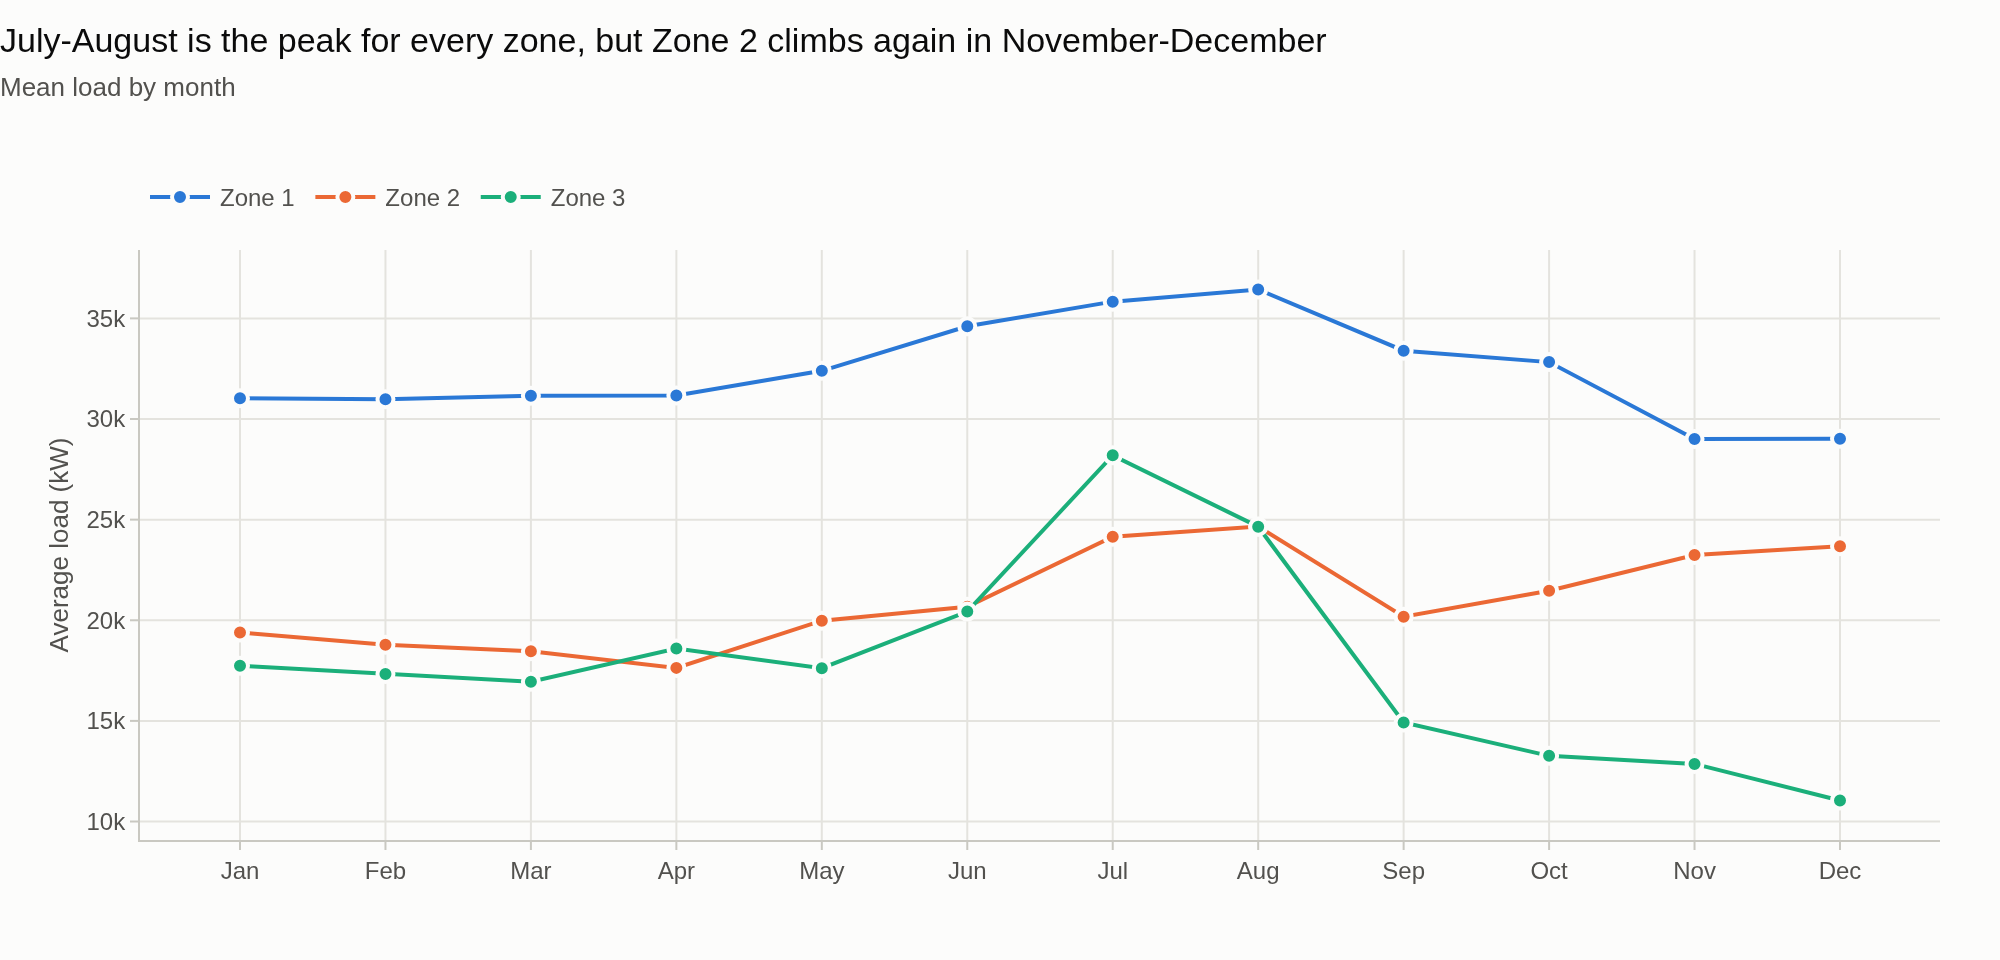

,kruskal_H,p,epsilon_squared,highest_month,lowest_month,highest_over_lowest
zone,,,,,,
Zone1,271.680,0.000,0.748,Aug,Nov,1.256
Zone2,264.374,0.000,0.728,Aug,Apr,1.398
Zone3,341.566,0.000,0.941,Jul,Dec,2.553


In [22]:
monthly = daily.groupby("MonthName", observed=True)[ZONES + ["Total"] + pp.ENV].mean()
monthly.to_csv(OUT / "monthly_profile.csv")
for z in ZONES + ["Total"]:
    for m in ["Jan", "Jul", "Aug", "Dec"]:
        key(f"{z}_{m}_mean", monthly.loc[m, z], f"{z} mean load in {m} (kW)")

fig = go.Figure()
for z in ZONES:
    fig.add_scatter(x=monthly.index.astype(str), y=monthly[z], name=ZN(z), mode="lines+markers", line_color=ch.ZONE_COLORS[z])
fig.update_layout(title=ch.title("July-August is the peak for every zone, but Zone 2 climbs again in November-December",
                                 "Mean load by month"), hovermode="x unified")
ch.kw_axis(fig)
ch.save(fig, "10_monthly_load_by_zone", height=480);

mt = []
for z in ZONES:
    kw = stats.kruskal(*[g[z].to_numpy() for _, g in daily.groupby("Month")])
    mt.append({"zone": z, "kruskal_H": kw.statistic, "p": kw.pvalue, "epsilon_squared": pp.epsilon_squared(kw.statistic, len(daily)),
               "highest_month": monthly[z].idxmax(), "lowest_month": monthly[z].idxmin(),
               "highest_over_lowest": monthly[z].max() / monthly[z].min()})
monthly_tests = pd.DataFrame(mt).set_index("zone")
monthly_tests.to_csv(OUT / "monthly_tests.csv")
monthly_tests

**Monthly pattern.** Month explains most of the day-to-day differences in load (Kruskal-Wallis on daily means: ε² = 0.75 for Zone 1, 0.73 for Zone 2 and 0.94 for Zone 3). The p-values are tiny, but neighbouring days are correlated, so the effect sizes, not the p-values, carry the conclusion.

- **Every zone peaks in summer:** August for Zones 1 and 2, July for Zone 3.
- **The size of the swing differs hugely.** Zone 3's highest month is **2.6 times** its lowest (July 28.2 MW against December 11.0 MW). For Zone 1 it is 1.26 times, and for Zone 2 1.40 times.
- **The low months differ.** Zone 1 is lowest in November and December, Zone 2 in April, and Zone 3 in December. Zone 2 rises again in November and December to above its annual average, while Zone 3 falls to its lowest level of the year. Section 7.4 shows this is a change in base level, not a weather effect.

With one year of data, these monthly differences are a description of **2017**. One year cannot show whether the same months will look the same in other years.

### 5.4 Recurring calendar patterns: Ramadan and public holidays

Mean total load 01:00-03:59 (MW): {'3 weeks before (6-26 May)': 57.1, 'Ramadan (27 May-25 Jun)': 82.6, '3 weeks after (28 Jun-18 Jul)': 73.1}


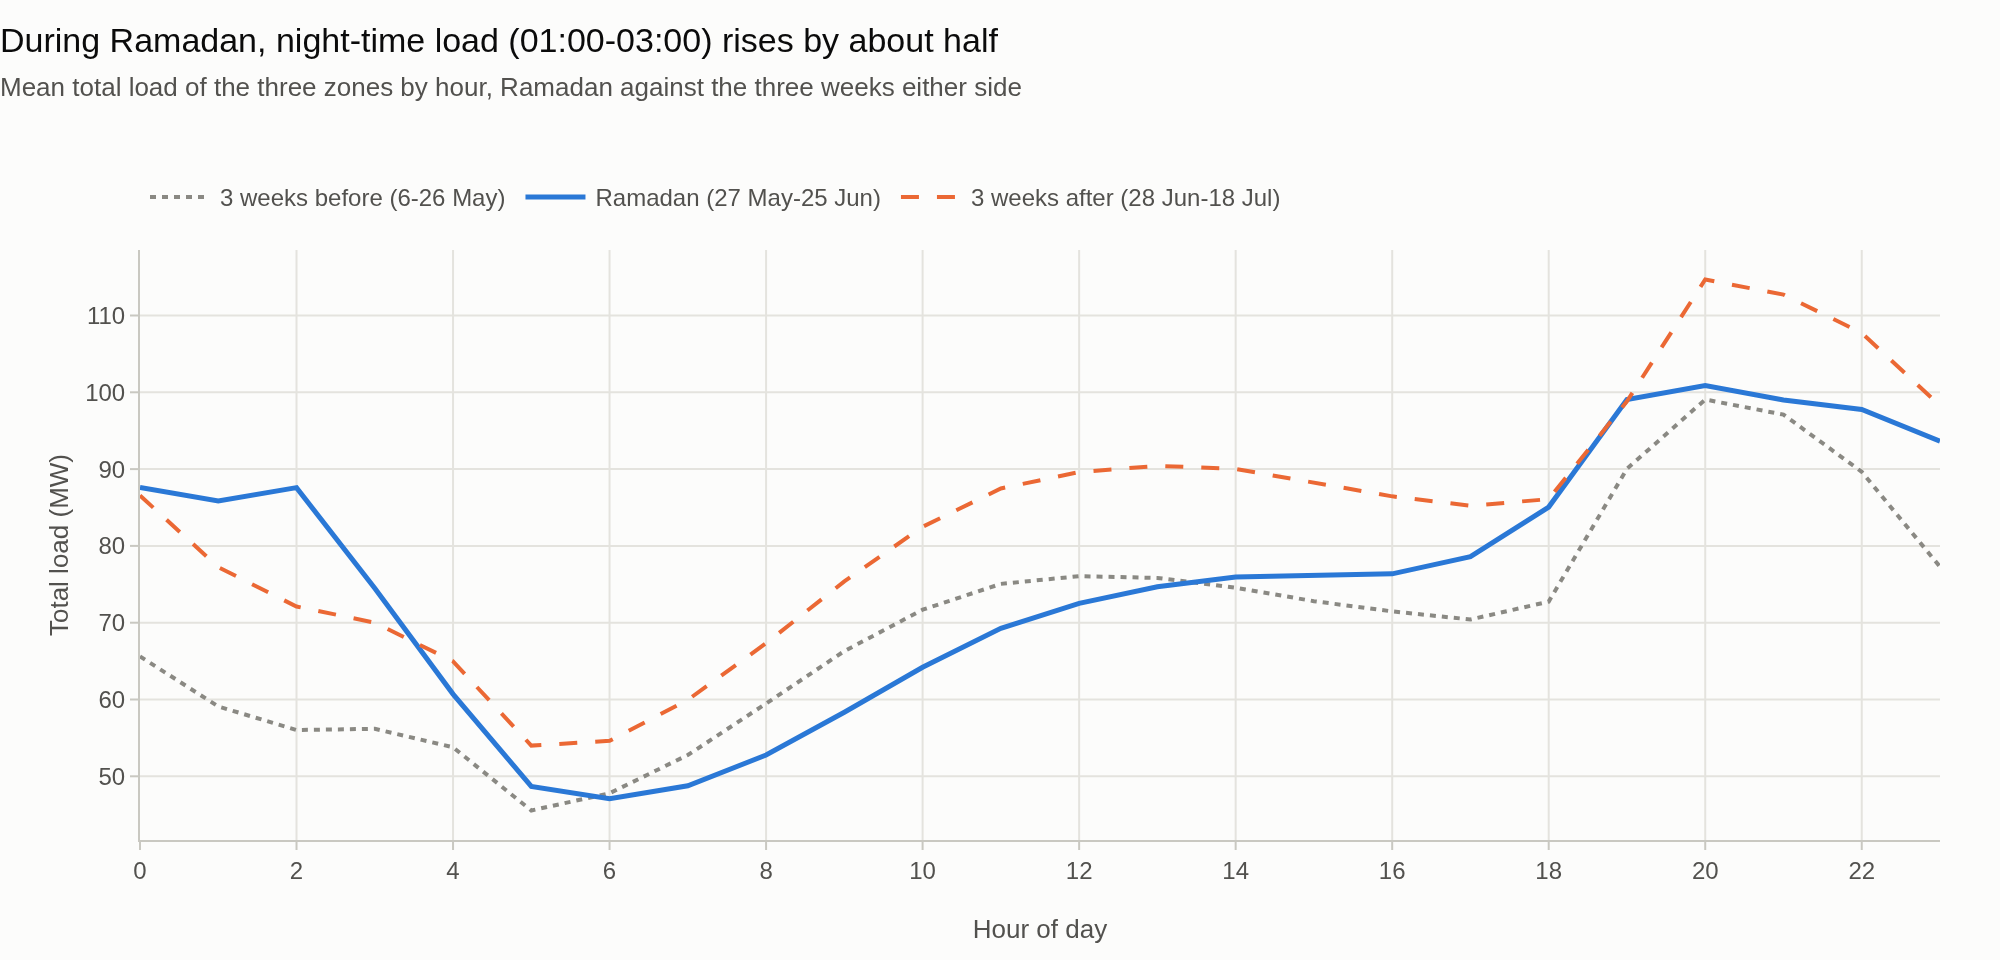

np.float64(1.4472964183706616)

In [23]:
def window_profile(a, b):
    w = hourly[(hourly.Date >= a) & (hourly.Date <= b)]
    return w.groupby("Hour")["Total"].mean()

ram = pd.DataFrame({
    "3 weeks before (6-26 May)": window_profile("2017-05-06", "2017-05-26"),
    "Ramadan (27 May-25 Jun)": window_profile(*pp.RAMADAN),
    "3 weeks after (28 Jun-18 Jul)": window_profile("2017-06-28", "2017-07-18"),
})
ram.to_csv(OUT / "ramadan_profile.csv")
night = ram.loc[1:3].mean()
print("Mean total load 01:00-03:59 (MW):", (night / 1000).round(1).to_dict())

fig = go.Figure()
styles = [(ch.NEUTRAL, "dot"), (ch.ACCENT, "solid"), (ch.SECOND, "dash")]
for (col, (c, dash)) in zip(ram.columns, styles):
    fig.add_scatter(x=ram.index, y=ram[col] / 1000, name=col, line=dict(color=c, dash=dash, width=2.5 if dash == "solid" else 2))
fig.update_layout(title=ch.title("During Ramadan, night-time load (01:00-03:00) rises by about half",
                                 "Mean total load of the three zones by hour, Ramadan against the three weeks either side"),
                  xaxis_title="Hour of day", yaxis_title="Total load (MW)", hovermode="x unified")
fig.update_xaxes(dtick=2)
ch.save(fig, "11_ramadan_hourly_profile", height=480);
key("ramadan_night_ratio", night.iloc[1] / night.iloc[0], "Ramadan 01:00-03:59 total load / the 3 weeks before")

**Ramadan is the clearest recurring pattern outside the daily and weekly cycles.** During Ramadan 1438 (27 May to 25 June 2017), mean total load between 01:00 and 03:59 was **82.6 MW, 45% above the 57.1 MW of the three weeks before**. This is the pre-dawn meal (suhoor). The morning ramp started later and stayed lower until mid-afternoon, and the evening peak stayed high later into the night (22:00 load 97 MW against 90 MW before). The data confirms the dates independently: night-time load steps up on the night of 27 May and drops back on 27 June (checked during preparation).

Two consequences:
- Ramadan moves through the Gregorian calendar by about 11 days a year, so **a model that uses month alone will put the Ramadan pattern in the wrong place in other years**. It needs its own calendar flag, as used in Section 6.5.
- In 2017, Ramadan overlapped the start of the hot season, so part of June's increase in load is a calendar effect, not a weather effect.

### 5.5 Time-series decomposition

**Method.** The hourly series has two seasonal cycles: a 24-hour cycle and a 168-hour (weekly) cycle. Statsmodels' **MSTL** (Multiple Seasonal-Trend decomposition using LOESS) separates them, giving *observed = trend + daily seasonal + weekly seasonal + residual*. An additive model fits because the daily swing is similar in size across the year for Zones 1 and 2. For Zone 3 the swing grows in summer, so its seasonal components change over time; MSTL allows that.

**What "trend" means here.** With a single year there is no repeat of the annual cycle, so the annual seasonal pattern **cannot be separated from a long-run trend**. The "trend" component is therefore the slow seasonal level of 2017: summer up, winter down. It is **not** evidence of growth or decline in demand. Strength of each component follows Wang, Smith & Hyndman (2006): 1 − Var(residual) / Var(component + residual), from 0 (none) to 1 (dominant).

In [24]:
h_idx = hourly.set_index("Datetime")
h_idx.index.freq = "h"
mstl = {}
for z in ZONES:
    mstl[z] = MSTL(h_idx[z], periods=(24, 168)).fit()

strength = []
for z in ZONES:
    r = mstl[z]
    s24, s168 = r.seasonal.iloc[:, 0], r.seasonal.iloc[:, 1]
    strength.append({"zone": z,
                     "trend_strength": pp.trend_strength(r.trend, r.resid),
                     "daily_seasonal_strength": pp.seasonal_strength(s24, r.resid),
                     "weekly_seasonal_strength": pp.seasonal_strength(s168, r.resid),
                     "trend_range_kW": r.trend.max() - r.trend.min(),
                     "daily_cycle_range_kW": s24.groupby(s24.index.hour).mean().pipe(lambda s: s.max() - s.min()),
                     "weekly_cycle_range_kW": (s168 + 0).groupby([s168.index.day_of_week]).mean().pipe(lambda s: s.max() - s.min()),
                     "residual_sd_kW": r.resid.std(),
                     "share_of_variance_trend": r.trend.var() / h_idx[z].var(),
                     "share_of_variance_daily": s24.var() / h_idx[z].var(),
                     "share_of_variance_weekly": s168.var() / h_idx[z].var(),
                     "share_of_variance_residual": r.resid.var() / h_idx[z].var()})
decomp = pd.DataFrame(strength).set_index("zone")
decomp.to_csv(OUT / "decomposition_strength.csv")
decomp.T

zone,Zone1,Zone2,Zone3
trend_strength,0.876,0.911,0.985
daily_seasonal_strength,0.980,0.969,0.981
weekly_seasonal_strength,0.518,0.683,0.246
trend_range_kW,"9,327.264","9,760.543","20,383.930"
daily_cycle_range_kW,"20,624.436","13,240.018","14,372.401"
weekly_cycle_range_kW,"2,104.111","2,805.881",488.722
residual_sd_kW,935.534,773.091,608.549
share_of_variance_trend,0.120,0.223,0.541
share_of_variance_daily,0.837,0.695,0.441
share_of_variance_weekly,0.018,0.047,0.002


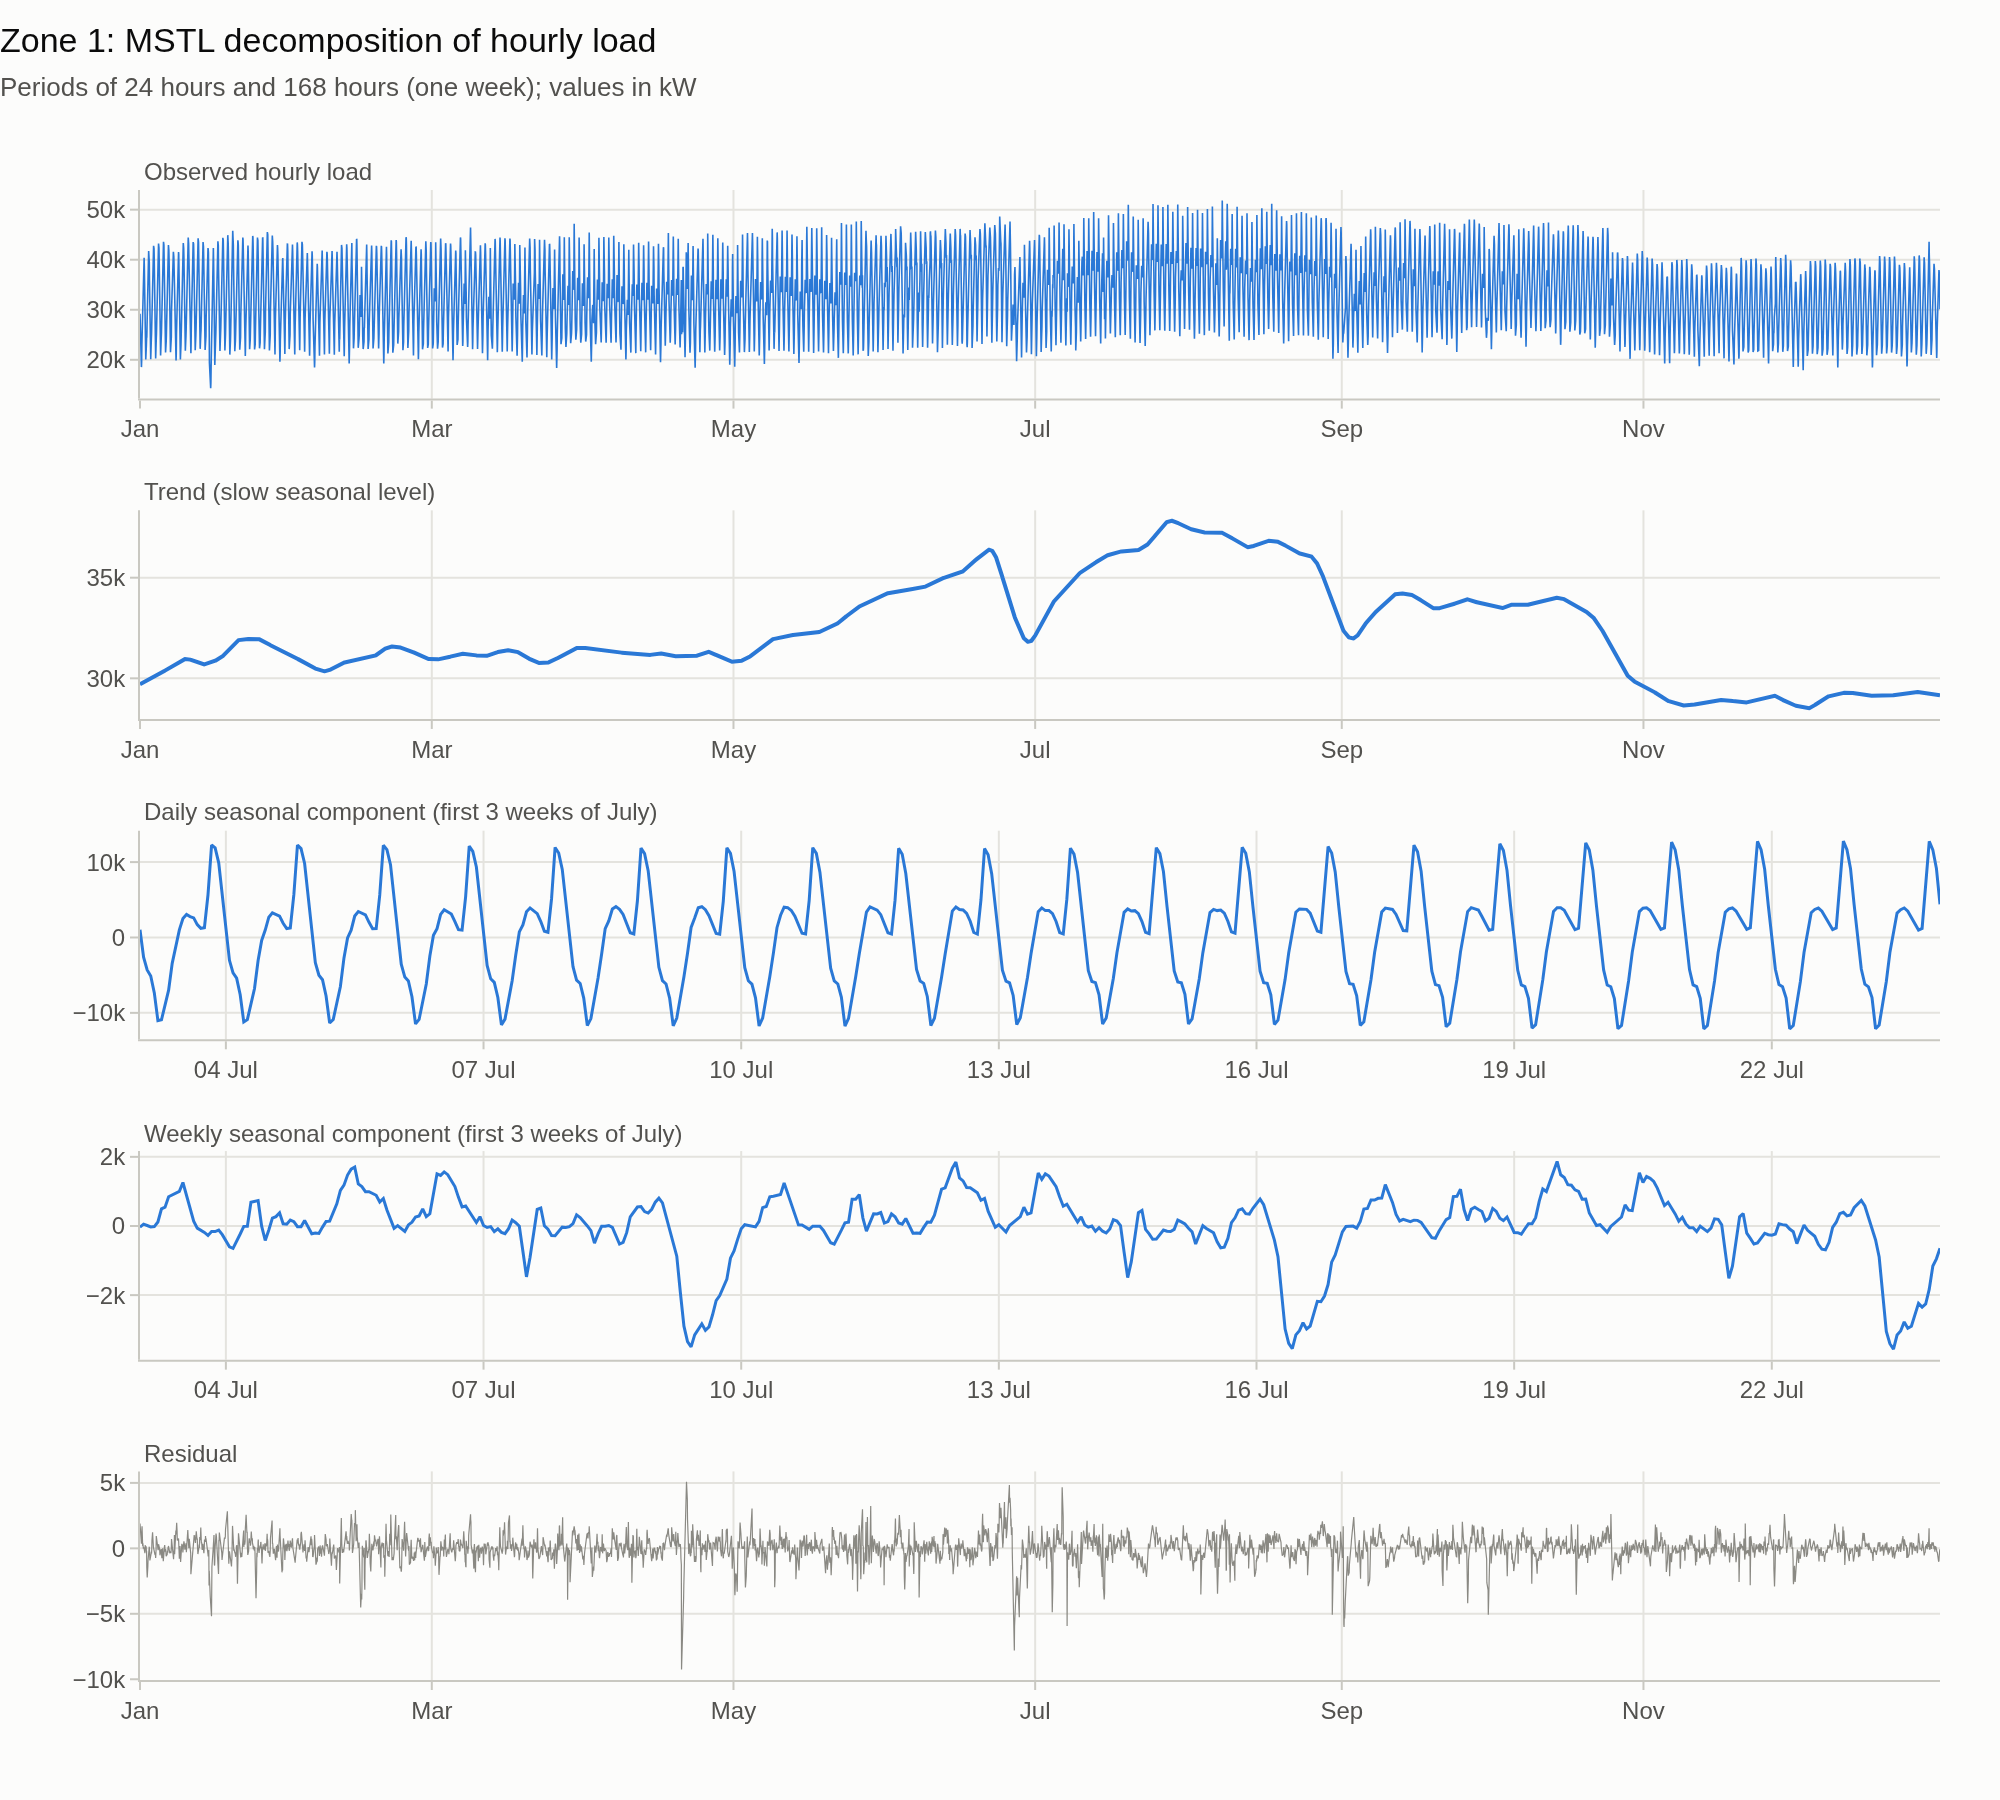

Zone 2 and Zone 3 decompositions are saved as 12_mstl_decomposition_zone2/3.png and in Visualizations/interactive/.


In [25]:
for i, z in enumerate(ZONES, start=1):
    r = mstl[z]
    c = ch.ZONE_COLORS[z]
    fig = make_subplots(rows=5, cols=1, shared_xaxes=False, vertical_spacing=0.075,
                        subplot_titles=["Observed hourly load", "Trend (slow seasonal level)",
                                        "Daily seasonal component (first 3 weeks of July)",
                                        "Weekly seasonal component (first 3 weeks of July)", "Residual"])
    fig.add_scatter(x=r.observed.index, y=r.observed, line=dict(color=c, width=0.8), row=1, col=1)
    fig.add_scatter(x=r.trend.index, y=r.trend, line=dict(color=c, width=2), row=2, col=1)
    jul = slice("2017-07-03", "2017-07-23")
    fig.add_scatter(x=r.seasonal.loc[jul].index, y=r.seasonal.iloc[:, 0].loc[jul], line=dict(color=c, width=1.5), row=3, col=1)
    fig.add_scatter(x=r.seasonal.loc[jul].index, y=r.seasonal.iloc[:, 1].loc[jul], line=dict(color=c, width=1.5), row=4, col=1)
    fig.add_scatter(x=r.resid.index, y=r.resid, line=dict(color=ch.NEUTRAL, width=0.6), row=5, col=1)
    for row in range(1, 6):
        fig.update_yaxes(tickformat="~s", row=row, col=1)
        fig.update_xaxes(tickformat="%d %b" if row in (3, 4) else "%b", row=row, col=1)
    fig.update_annotations(font=dict(size=12, color=ch.TEXT_2), x=0, xanchor="left")
    fig.update_layout(showlegend=False, title=ch.title(f"{ZN(z)}: MSTL decomposition of hourly load",
                                                       "Periods of 24 hours and 168 hours (one week); values in kW"),
                      margin=dict(t=110))
    ch.save(fig, f"12_mstl_decomposition_zone{i}", height=900, show=(i == 1));
print("Zone 2 and Zone 3 decompositions are saved as 12_mstl_decomposition_zone2/3.png and in Visualizations/interactive/.")

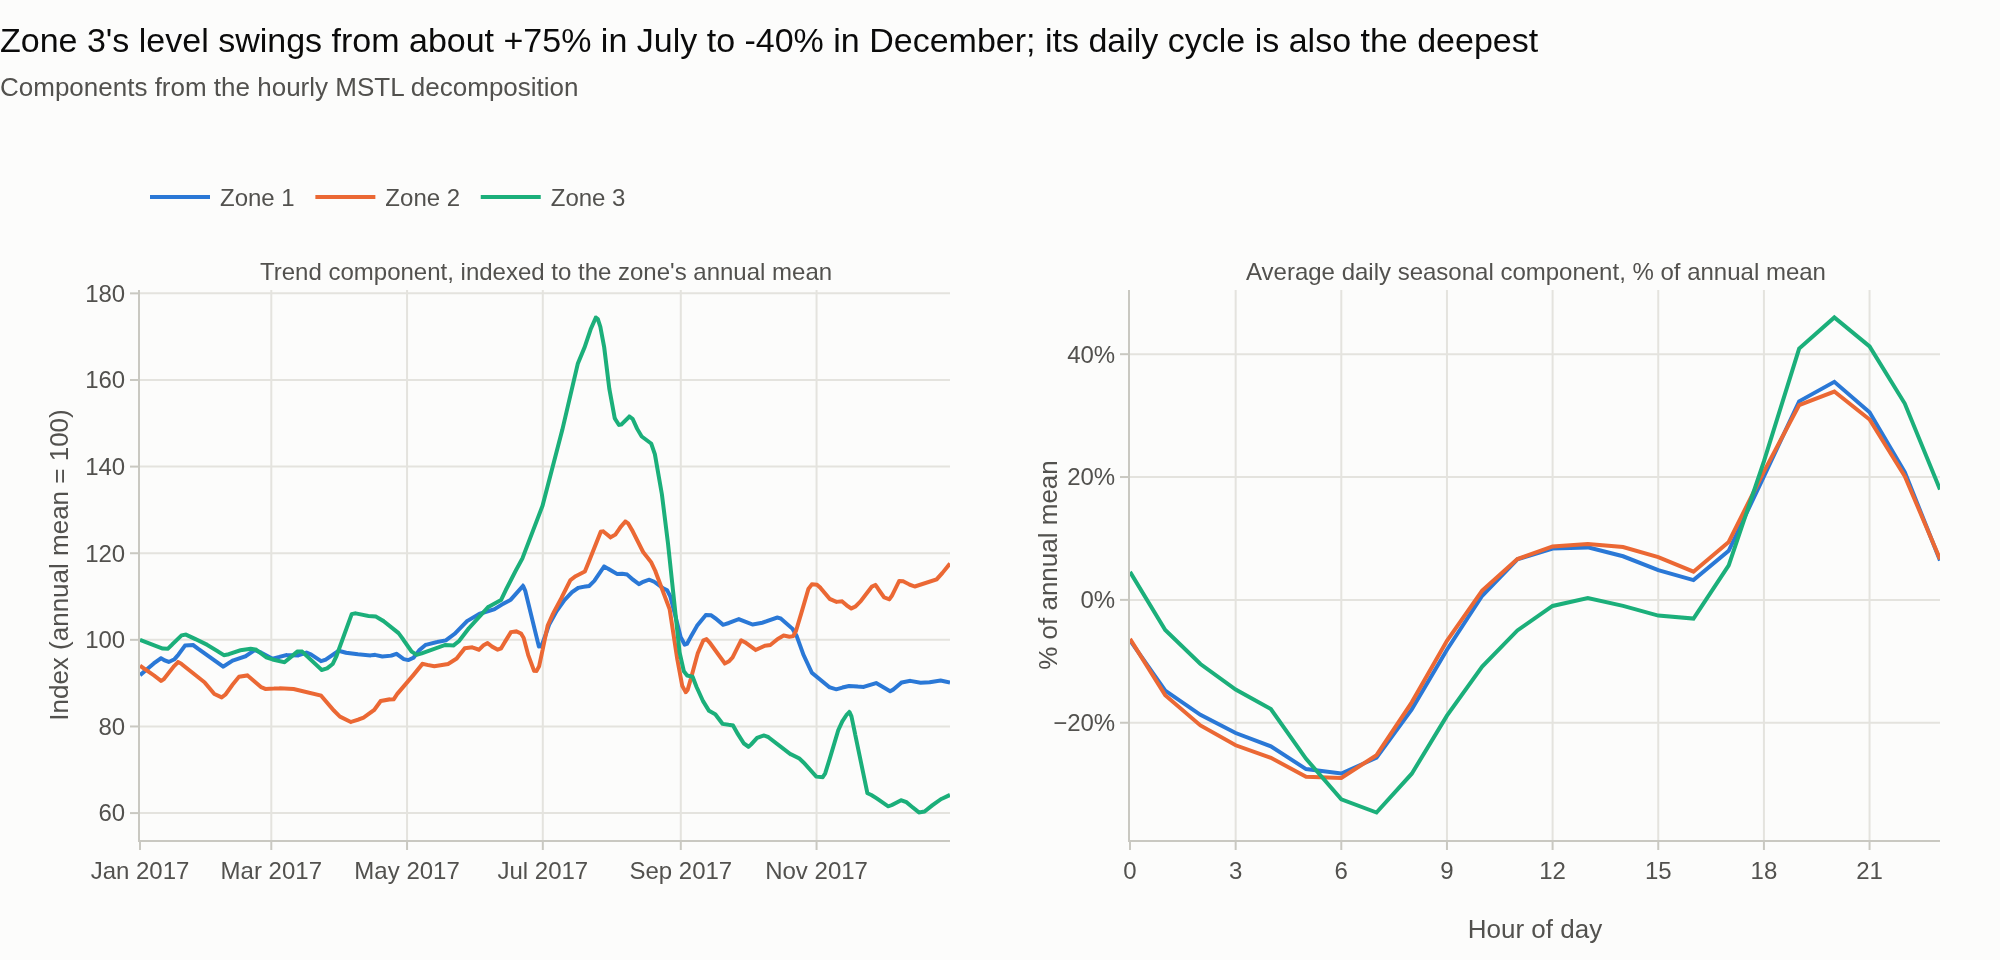

In [26]:
fig = make_subplots(rows=1, cols=2, subplot_titles=["Trend component, indexed to the zone's annual mean",
                                                    "Average daily seasonal component, % of annual mean"],
                    horizontal_spacing=0.1)
for z in ZONES:
    r = mstl[z]
    mean = h_idx[z].mean()
    fig.add_scatter(x=r.trend.index, y=r.trend / mean * 100, name=ZN(z), line_color=ch.ZONE_COLORS[z], row=1, col=1)
    s24 = r.seasonal.iloc[:, 0]
    prof = s24.groupby(s24.index.hour).mean() / mean * 100
    fig.add_scatter(x=prof.index, y=prof, name=ZN(z), line_color=ch.ZONE_COLORS[z], showlegend=False, row=1, col=2)
fig.update_yaxes(title_text="Index (annual mean = 100)", row=1, col=1)
fig.update_yaxes(title_text="% of annual mean", ticksuffix="%", row=1, col=2)
fig.update_xaxes(title_text="Hour of day", dtick=3, row=1, col=2)
fig.update_annotations(font=dict(size=12, color=ch.TEXT_2))
fig.update_layout(title=ch.title("Zone 3's level swings from about +75% in July to -40% in December; its daily cycle is also the deepest",
                                 "Components from the hourly MSTL decomposition"))
ch.save(fig, "13_trend_and_daily_cycle_compared", height=480);

**Interpretation of the decomposition**

| | Zone 1 | Zone 2 | Zone 3 |
|---|---|---|---|
| Daily seasonal strength | 0.98 | 0.97 | 0.98 |
| Weekly seasonal strength | 0.52 | 0.68 | 0.25 |
| Trend (slow level) strength | 0.88 | 0.91 | 0.99 |
| Share of variance: daily cycle | **84%** | **70%** | 44% |
| Share of variance: slow level | 12% | 22% | **54%** |
| Share of variance: weekly cycle | 2% | 5% | 0.2% |
| Share of variance: residual | 2% | 2% | 1% |

- **Trend component:** a summer hump in all three zones, with a sharp dip in late June. That dip is Eid al-Fitr, followed by the early-July holiday period. Zone 3's level moves furthest: its trend has a range of 20.4 MW, more than its annual mean, against 9.3 MW for Zone 1 and 9.8 MW for Zone 2. Zone 1's level drops sharply at the end of October and stays low.
- **Daily seasonal component:** the strongest and most regular pattern in every zone (strength ≥ 0.97). Its shape is a trough at 05:00 to 07:00, a midday plateau, a dip around 16:00, and a sharp evening peak at 20:00. Zone 3's is the deepest relative to its size.
- **Weekly seasonal component:** small. It mostly shows the Sunday daytime dip, and is clearest in Zone 2. In Zone 3 it is negligible (0.2% of variance).
- **Residual:** only 1% to 2% of the variance remains, so these three components describe the series almost completely. The largest residuals fall on holidays and on the network events seen in Section 2.

**What this means for planning:** the time of day explains most of the variation in load in Zones 1 and 2, and the season explains most of it in Zone 3. Capacity planning for Zone 3 is therefore mainly a summer problem, while for Zones 1 and 2 it is mainly an evening-peak problem.

In [27]:
stl_d = {z: STL(d_idx[z], period=7, robust=True).fit() for z in ZONES}
st_rows = []
for z in ZONES:
    x = d_idx[z].to_numpy()
    adf = adfuller(x, autolag="AIC")
    kp = kpss(x, regression="c", nlags="auto")
    res = stl_d[z].resid
    adf_r = adfuller(res, autolag="AIC")
    kp_r = kpss(res, regression="c", nlags="auto")
    st_rows.append({"zone": z, "ADF_p_daily_level": adf[1], "KPSS_p_daily_level": kp[1],
                    "ADF_p_STL_residual": adf_r[1], "KPSS_p_STL_residual": kp_r[1],
                    "lag1_autocorr_daily": pd.Series(x).autocorr(1),
                    "lag1_autocorr_residual": res.autocorr(1)})
stationarity = pd.DataFrame(st_rows).set_index("zone")
stationarity.to_csv(OUT / "stationarity_tests.csv")
stationarity

,ADF_p_daily_level,KPSS_p_daily_level,ADF_p_STL_residual,KPSS_p_STL_residual,lag1_autocorr_daily,lag1_autocorr_residual
zone,,,,,,
Zone1,0.504,0.023,0.000,0.100,0.881,0.372
Zone2,0.521,0.010,0.000,0.100,0.870,0.397
Zone3,0.534,0.010,0.000,0.100,0.992,0.585


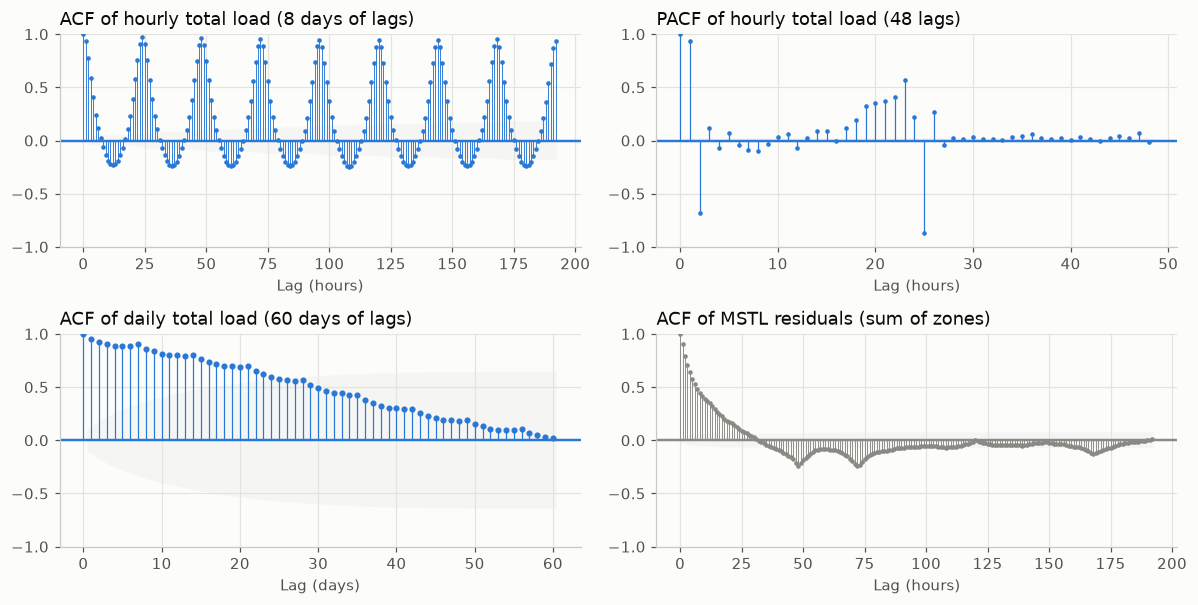

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5.6))
plot_acf(h_idx["Total"], lags=24 * 8, ax=axes[0, 0], markersize=2, color=ch.ACCENT, vlines_kwargs={"colors": ch.ACCENT, "linewidth": 0.6})
axes[0, 0].set_title("ACF of hourly total load (8 days of lags)")
axes[0, 0].set_xlabel("Lag (hours)")
plot_pacf(h_idx["Total"], lags=48, ax=axes[0, 1], method="ywm", markersize=2, color=ch.ACCENT, vlines_kwargs={"colors": ch.ACCENT, "linewidth": 0.8})
axes[0, 1].set_title("PACF of hourly total load (48 lags)")
axes[0, 1].set_xlabel("Lag (hours)")
plot_acf(d_idx["Total"], lags=60, ax=axes[1, 0], markersize=3, color=ch.ACCENT, vlines_kwargs={"colors": ch.ACCENT, "linewidth": 0.8})
axes[1, 0].set_title("ACF of daily total load (60 days of lags)")
axes[1, 0].set_xlabel("Lag (days)")
tot_resid = sum(mstl[z].resid for z in ZONES)
plot_acf(tot_resid, lags=24 * 8, ax=axes[1, 1], markersize=2, color=ch.NEUTRAL, vlines_kwargs={"colors": ch.NEUTRAL, "linewidth": 0.6})
axes[1, 1].set_title("ACF of MSTL residuals (sum of zones)")
axes[1, 1].set_xlabel("Lag (hours)")
for ax in axes.ravel():
    for coll in ax.collections:
        coll.set_facecolor(ch.GRID)
fig.tight_layout()
ch.save_mpl(fig, "14_acf_pacf")
plt.show()

**Autocorrelation and stationarity**

- The ACF of hourly load repeats every 24 hours, with a slightly higher spike every 168 hours (one week). This confirms the two seasonal periods used in the MSTL. The PACF has large spikes at lags 1 and 2 and again at lags 23 to 25, so an hour's load is best predicted by the previous two hours and by the same time yesterday. That is useful for the Machine Learning track's lag features.
- The ACF of **daily** load decays very slowly. The daily level is **non-stationary**: for every zone the ADF test does not reject a unit root (p ≈ 0.5) and the KPSS test rejects stationarity (p ≤ 0.02). After removing the STL trend and weekly component, the residual is stationary (ADF p < 0.001; KPSS p ≥ 0.10).
- Even the MSTL residuals stay autocorrelated (lag-1 autocorrelation of the daily residual 0.37 to 0.59). This is why ordinary p-values for correlations and group tests would overstate the evidence, and why Section 6 uses effective sample sizes and Section 7 uses block bootstrap intervals.

In [29]:
anom = []
for z in ZONES:
    r = stl_d[z].resid
    scale = 1.4826 * (r - r.median()).abs().median()
    zs = (r - r.median()) / scale
    for t in zs[zs.abs() > 4].index:
        anom.append({"date": t.date(), "zone": z, "robust_z": zs[t], "residual_kW": r[t],
                     "weekday": t.day_name(), "holiday": pp.HOLIDAYS_2017.get(t.strftime("%Y-%m-%d"), ""),
                     "ramadan": pp.RAMADAN[0] <= t <= pp.RAMADAN[1]})
anomalies = pd.DataFrame(anom).sort_values(["date", "zone"])
anomalies.to_csv(OUT / "daily_anomalies.csv", index=False)
hol_days = set(pd.to_datetime(list(pp.HOLIDAYS_2017)).date)
anom_days = set(anomalies["date"])
n_hol_flag = len(anom_days & hol_days)
print(f"{len(anom_days)} of 364 days have |robust z| > 4 in at least one zone.")
print(f"Holidays flagged: {n_hol_flag} of {len(hol_days)} ({n_hol_flag/len(hol_days):.0%}); "
      f"other days flagged: {len(anom_days) - n_hol_flag} of {364 - len(hol_days)} "
      f"({(len(anom_days) - n_hol_flag)/(364 - len(hol_days)):.0%}).")
top = anomalies.assign(abs_z=anomalies.robust_z.abs()).sort_values("abs_z", ascending=False)
top.groupby("date", sort=False).agg(zones=("zone", ", ".join), largest_z=("robust_z", lambda v: v.iloc[0]),
                                    weekday=("weekday", "first"), holiday=("holiday", "first"),
                                    ramadan=("ramadan", "first")).head(15)

91 of 364 days have |robust z| > 4 in at least one zone.
Holidays flagged: 12 of 15 (80%); other days flagged: 79 of 349 (23%).


,zones,largest_z,weekday,holiday,ramadan
date,,,,,
2017-06-27,"Zone1, Zone2, Zone3",-24.595,Tuesday,Eid al-Fitr (2nd day),False
2017-09-01,"Zone1, Zone3, Zone2",-20.450,Friday,Eid al-Adha,False
2017-07-25,Zone3,19.615,Tuesday,,False
2017-11-18,"Zone3, Zone2",18.062,Saturday,Independence Day,False
2017-11-17,Zone3,17.738,Friday,,False
2017-11-09,Zone3,17.230,Thursday,,False
2017-06-26,"Zone1, Zone2",-15.719,Monday,Eid al-Fitr,False
2017-11-08,Zone3,14.887,Wednesday,,False
2017-08-31,"Zone3, Zone1, Zone2",-14.700,Thursday,,False


**Unusual days.** The table lists the 15 most extreme days, where the daily STL residual is more than 4 robust standard deviations from normal. **Public holidays are far more likely to be unusual than other days: 12 of the 15 holidays (80%) are flagged, against 23% of ordinary days.** The largest drops are all religious holidays. On the second day of Eid al-Fitr (27 June), Zone 1 was 6.2 MW below its expected level (z = −25), and Eid al-Adha (1 September) is the next largest drop in all three zones. The largest *positive* anomalies are in Zone 3: 25 July, 8 to 9 November and 17 to 18 November. These look more like network events (load temporarily moved into Zone 3) than like behaviour, given the shifts shown in Section 7.4. Holidays therefore need their own treatment in any forecast, and in maintenance planning they are low-demand windows.

## 6. Environmental statistical analysis (Task 4)

The question is whether temperature, humidity and wind speed are **associated** with load. Three things make a naive answer misleading here, and each is handled explicitly:

1. **Serial correlation.** Neighbouring readings are almost identical, so 52,416 readings do not carry 52,416 independent pieces of evidence. Ordinary p-values would all be close to zero. Each correlation's p-value and confidence interval are therefore based on an **effective sample size** (Bartlett / Pyper & Peterman), which shrinks n according to how autocorrelated both series are.
2. **Shared cycles.** Temperature, humidity and load all follow the time of day and the season, so a correlation can come from the clock and the calendar rather than from the weather. Sections 6.4 and 6.5 control for them.
3. **Non-linearity.** Load may respond to temperature only above a comfort threshold, which a single straight-line correlation would understate.

### 6.1 Choice of correlation method

In [30]:
choice = []
for z in ZONES:
    for v in pp.ENV:
        p = stats.pearsonr(hourly[v], hourly[z]).statistic
        s = stats.spearmanr(hourly[v], hourly[z]).statistic
        choice.append({"zone": z, "variable": v, "pearson": p, "spearman": s, "difference": p - s})
pd.DataFrame(choice).pivot(index="variable", columns="zone", values=["pearson", "spearman"]).round(3)

pearson               spearman              
zone          Zone1  Zone2  Zone3    Zone1  Zone2  Zone3
variable                                                
Humidity     -0.291 -0.298 -0.235   -0.302 -0.311 -0.213
Temperature   0.444  0.385  0.492    0.435  0.380  0.438
WindSpeed     0.170  0.148  0.281    0.115  0.094  0.084

**Spearman's rank correlation is the primary method.** Pearson measures *linear* association and is sensitive to the shape of the distribution. Here:

- **Wind speed is two-state**, not continuous. Pearson then mainly measures the difference in mean load between two groups of readings, weighted by the very unequal group sizes. For wind against Zone 3 it gives 0.28, against a Spearman ρ of 0.08.
- **Temperature acts on load non-linearly**: load is flat below about 17 to 22 °C and rises above it (Section 6.4). Spearman captures any monotonic association, so it does not require a straight line.
- **Zone 3 is strongly skewed** (skewness 1.0), and a few extreme summer evenings would pull a Pearson coefficient.

Pearson coefficients are still reported alongside, in `Outputs/correlations.csv`, for comparison. The two agree closely for temperature and humidity, where the assumptions are reasonable, and diverge only for wind. That pattern is itself evidence for the choice.

In [31]:
rows = []
levels = {"10-minute": df, "hourly": hourly, "daily": daily}
for lvl, data in levels.items():
    for z in ZONES:
        for v in pp.ENV:
            for method in ["spearman", "pearson"]:
                r = pp.corr_test(data[v], data[z], method)
                rows.append({"level": lvl, "zone": z, "variable": v, **r})
corr = pd.DataFrame(rows)
prim = (corr.level == "hourly") & (corr.method == "spearman")
corr.loc[prim, "p_adjusted_holm"] = pp.holm(corr.loc[prim, "p_adjusted"])
corr["strength"] = corr["r"].map(pp.strength_label)
corr.to_csv(OUT / "correlations.csv", index=False)
for _, r in corr[prim].iterrows():
    key(f"spearman_hourly_{r.variable}_{r.zone}", r.r, f"Spearman rho, hourly {r.variable} vs {r.zone}")
for _, r in corr[(corr.level == "daily") & (corr.method == "pearson")].iterrows():
    key(f"pearson_daily_{r.variable}_{r.zone}", r.r, f"Pearson r, daily {r.variable} vs {r.zone}")
corr[prim][["zone", "variable", "r", "ci_low", "ci_high", "n", "n_eff", "p_naive", "p_adjusted", "p_adjusted_holm", "strength"]]

,zone,variable,r,ci_low,ci_high,n,n_eff,p_naive,p_adjusted,p_adjusted_holm,strength
18,Zone1,Temperature,0.435,0.203,0.621,8736,64.973,0.000,0.000,0.003,moderate positive
20,Zone1,Humidity,-0.302,-0.492,-0.084,8736,80.937,0.000,0.006,0.044,moderate negative
22,Zone1,WindSpeed,0.115,-0.005,0.231,8736,270.819,0.000,0.059,0.186,weak positive
24,Zone2,Temperature,0.380,0.096,0.607,8736,47.683,0.000,0.008,0.047,moderate positive
26,Zone2,Humidity,-0.311,-0.491,-0.105,8736,89.254,0.000,0.003,0.024,moderate negative
28,Zone2,WindSpeed,0.094,-0.059,0.243,8736,166.682,0.000,0.229,0.458,negligible
30,Zone3,Temperature,0.438,-0.013,0.741,8736,21.105,0.000,0.046,0.186,moderate positive
32,Zone3,Humidity,-0.213,-0.393,-0.017,8736,102.073,0.000,0.031,0.157,weak negative
34,Zone3,WindSpeed,0.084,-0.163,0.321,8736,65.422,0.000,0.506,0.506,negligible


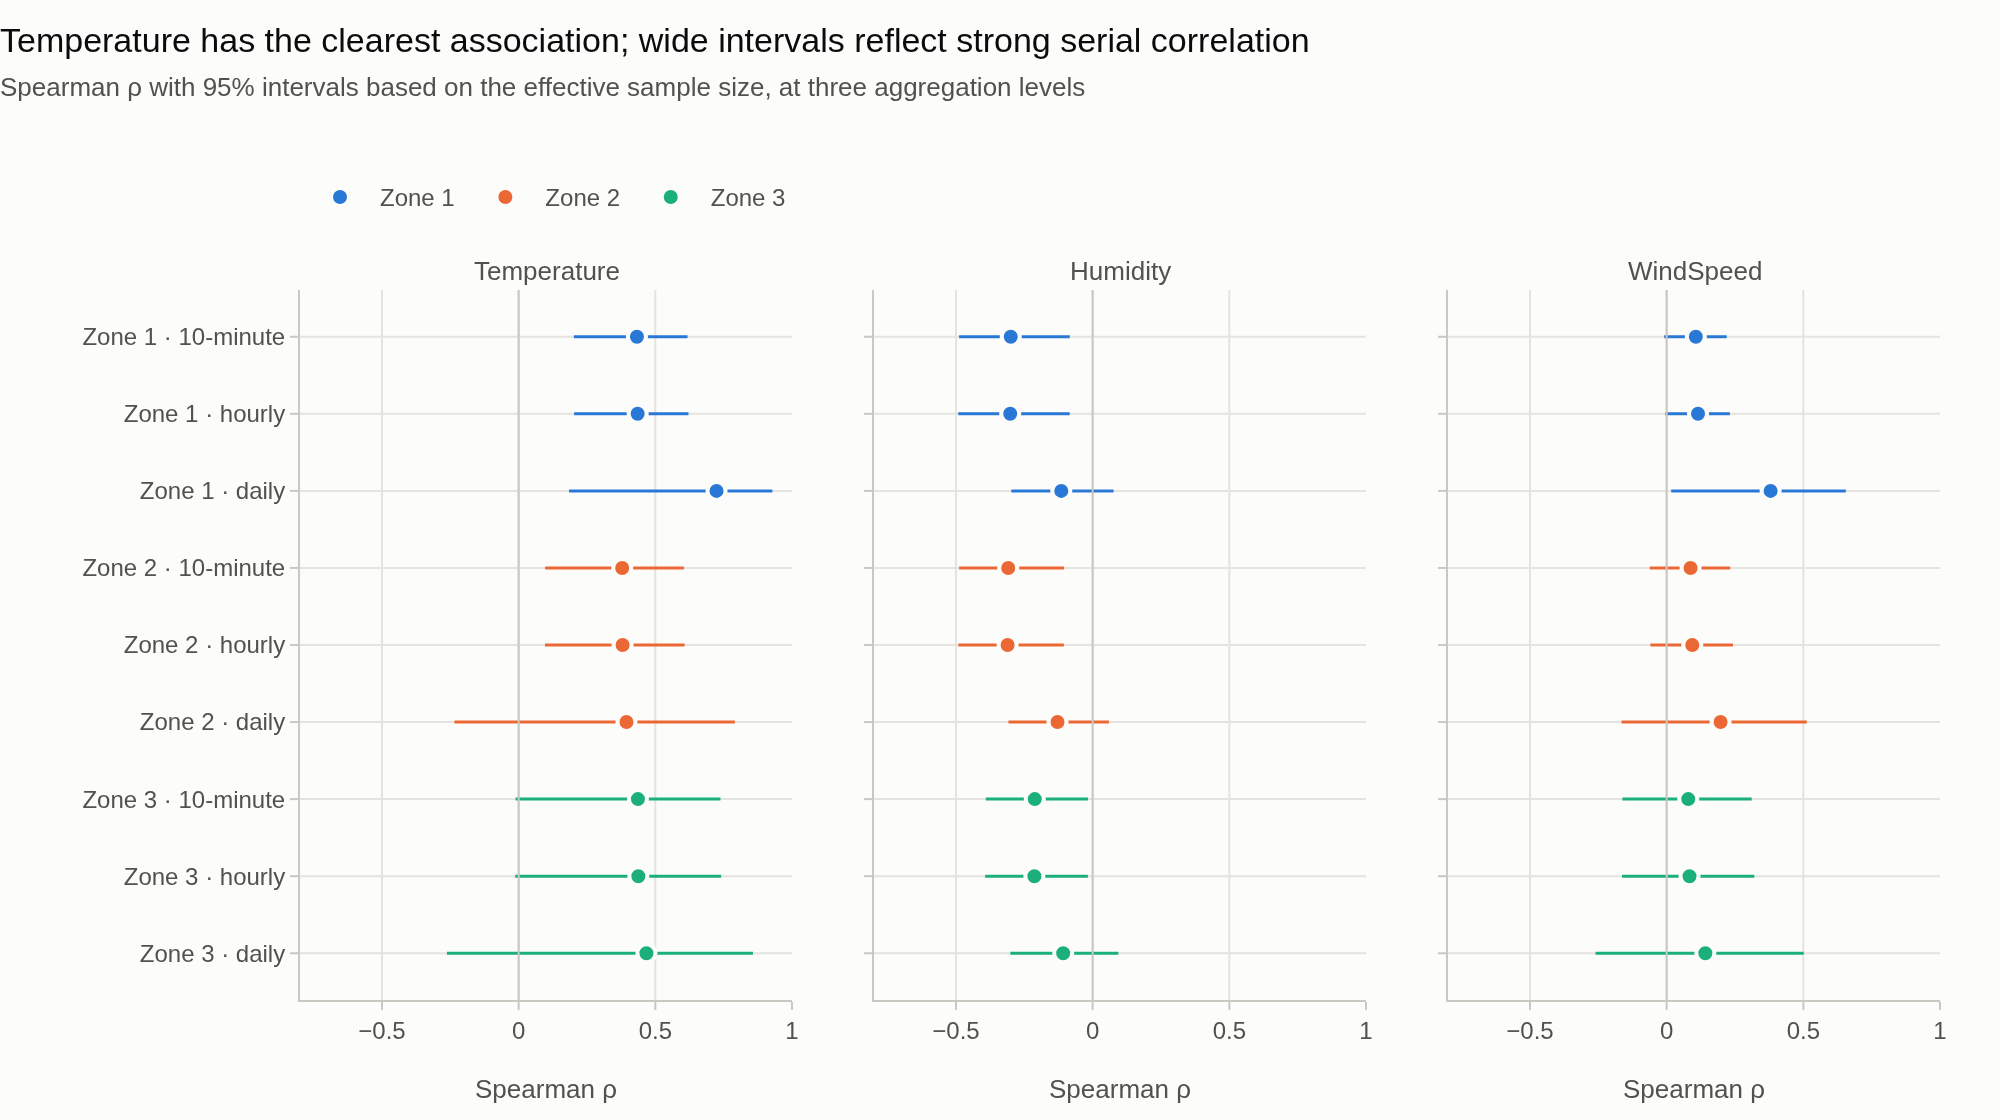

In [32]:
sp = corr[corr.method == "spearman"].copy()
fig = make_subplots(rows=1, cols=3, subplot_titles=pp.ENV, shared_yaxes=True, horizontal_spacing=0.05)
ylabels = {(lvl, z): f"{ZN(z)} · {lvl}" for lvl in levels for z in ZONES}
order = [f"{ZN(z)} · {lvl}" for z in ZONES for lvl in levels][::-1]
for j, v in enumerate(pp.ENV, start=1):
    for z in ZONES:
        sub = sp[(sp.variable == v) & (sp.zone == z)]
        ylab = [ylabels[(l, z)] for l in sub.level]
        fig.add_scatter(x=sub.r, y=ylab, mode="markers", marker=dict(color=ch.ZONE_COLORS[z], size=9),
                        error_x=dict(type="data", symmetric=False, array=sub.ci_high - sub.r, arrayminus=sub.r - sub.ci_low,
                                     color=ch.ZONE_COLORS[z], thickness=1.5, width=0),
                        name=ZN(z), showlegend=(j == 1), legendgroup=z,
                        customdata=np.c_[sub.n_eff, sub.p_adjusted],
                        hovertemplate="rho = %{x:.2f}<br>n_eff = %{customdata[0]:.0f}<br>adjusted p = %{customdata[1]:.3g}<extra></extra>",
                        row=1, col=j)
    fig.add_vline(x=0, line_color=ch.AXIS, line_width=1, row=1, col=j)
fig.update_yaxes(categoryorder="array", categoryarray=order)
fig.update_xaxes(range=[-0.8, 1.0], title_text="Spearman ρ")
fig.update_annotations(font=dict(size=13, color=ch.TEXT_2))
fig.update_layout(title=ch.title("Temperature has the clearest association; wide intervals reflect strong serial correlation",
                                 "Spearman ρ with 95% intervals based on the effective sample size, at three aggregation levels"),
                  margin=dict(l=150))
ch.save(fig, "15_correlation_forest_plot", height=560);

**Strength and direction (hourly level, Spearman ρ, 95% CI based on the effective sample size)**

| | Zone 1 | Zone 2 | Zone 3 |
|---|---|---|---|
| Temperature | **+0.44** (0.20 to 0.62) | **+0.38** (0.10 to 0.61) | +0.44 (−0.01 to 0.74) |
| Humidity | −0.30 (−0.49 to −0.08) | −0.31 (−0.49 to −0.11) | −0.21 (−0.39 to −0.02) |
| Wind speed | +0.11 (−0.01 to 0.23) | +0.09 (−0.06 to 0.24) | +0.08 (−0.16 to 0.32) |

- **Temperature has a moderate positive association** with load in every zone: warmer hours have higher load. After Holm correction across the nine tests it is significant for Zones 1 and 2 (p = 0.003 and 0.047). For Zone 3 it is not significant (Holm p = 0.19), despite a similar ρ, because Zone 3's strong seasonal persistence leaves only about **21 effectively independent observations** out of 8,736 hours.
- **Humidity has a weak to moderate negative association** (significant after Holm for Zones 1 and 2). Humidity is lowest on hot afternoons, so this is largely temperature viewed from the other side (temperature and humidity: ρ = −0.38).
- **Wind speed has a negligible to weak association**, not significant in any zone.

**Why the effective sample size matters.** All 27 naive p-values are below 10⁻¹⁵, because they treat 8,736 hours (or 52,416 readings) as independent. Both series in each pair follow the same daily and seasonal cycles, which reduces the effective sample to between 21 and 271. Read honestly, the evidence is therefore much weaker than the naive p-values suggest. The 10-minute and hourly results are almost identical. At the daily level, the daily cycle drops out and temperature becomes the dominant association for Zone 1 (ρ = 0.72).

In [33]:
hinge_rows, hinge_fits = [], {}
for z in ZONES + ["Total"]:
    f = pp.hinge_fit(daily["Temperature"], daily[z])
    arr = daily[["Temperature", z]].to_numpy()
    boot = pp.block_bootstrap(arr, lambda a: np.array([(h := pp.hinge_fit(a[:, 0], a[:, 1]))["base"], h["slope"]]),
                              block=14, n_boot=400, seed=SEED)
    (b_lo, s_lo), (b_hi, s_hi) = pp.percentile_ci(boot)
    hinge_fits[z] = f
    hinge_rows.append({"zone": z, "base_temp_C": f["base"], "base_ci_low": b_lo, "base_ci_high": b_hi,
                       "slope_kW_per_C": f["slope"], "slope_ci_low": s_lo, "slope_ci_high": s_hi,
                       "load_below_base_kW": f["intercept"], "r2": f["r2"],
                       "slope_pct_of_base_load": f["slope"] / f["intercept"] * 100})
hinge = pd.DataFrame(hinge_rows).set_index("zone")
hinge.to_csv(OUT / "hinge_models.csv")
hinge

,base_temp_C,base_ci_low,base_ci_high,slope_kW_per_C,slope_ci_low,slope_ci_high,load_below_base_kW,r2,slope_pct_of_base_load
zone,,,,,,,,,
Zone1,16.773,14.641,18.318,549.682,397.177,683.415,"30,502.071",0.597,1.802
Zone2,22.523,14.725,23.413,848.721,225.626,"1,113.328","20,377.038",0.282,4.165
Zone3,21.023,18.697,23.249,"1,682.738","1,133.716","2,322.440","15,726.480",0.581,10.700
Total,19.773,18.136,22.380,"2,609.317","1,617.456","3,756.738","66,665.141",0.710,3.914


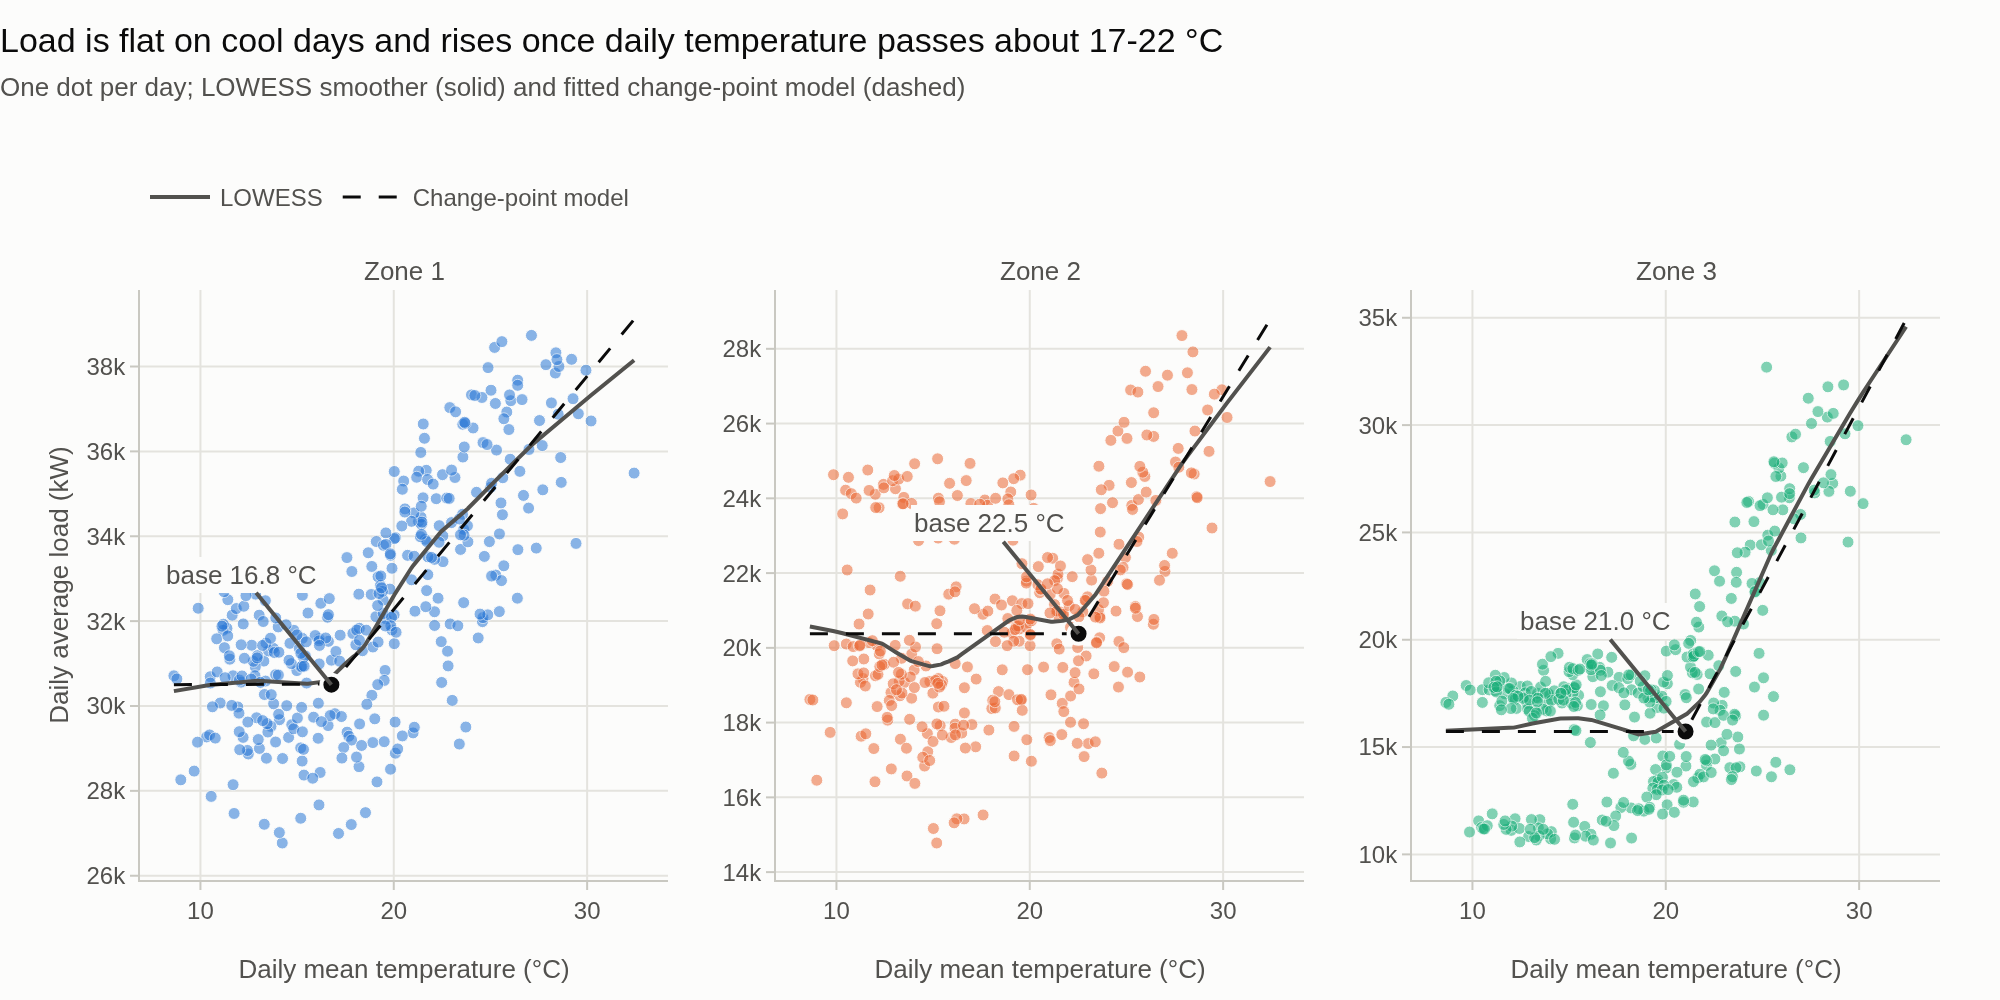

In [34]:
fig = make_subplots(rows=1, cols=3, subplot_titles=[ZN(z) for z in ZONES], horizontal_spacing=0.06)
for j, z in enumerate(ZONES, start=1):
    c = ch.ZONE_COLORS[z]
    fig.add_scatter(x=daily["Temperature"], y=daily[z], mode="markers",
                    marker=dict(color=c, size=6, opacity=0.55, line=dict(width=0.5, color=ch.SURFACE)),
                    customdata=daily["Date"].dt.strftime("%d %b"), name=ZN(z),
                    hovertemplate="%{customdata}<br>%{x:.1f} °C<br>%{y:,.0f} kW<extra></extra>", showlegend=False, row=1, col=j)
    lw = lowess(daily[z], daily["Temperature"], frac=0.4)
    fig.add_scatter(x=lw[:, 0], y=lw[:, 1], mode="lines", line=dict(color=ch.TEXT_2, width=2), name="LOWESS",
                    showlegend=(j == 1), hoverinfo="skip", row=1, col=j)
    f = hinge_fits[z]
    tx = np.linspace(daily["Temperature"].min(), daily["Temperature"].max(), 100)
    fig.add_scatter(x=tx, y=f["intercept"] + f["slope"] * np.maximum(0, tx - f["base"]), mode="lines",
                    line=dict(color=ch.TEXT, width=1.5, dash="dash"), name="Change-point model",
                    showlegend=(j == 1), hoverinfo="skip", row=1, col=j)
    fig.add_scatter(x=[f["base"]], y=[f["intercept"]], mode="markers", showlegend=False, hoverinfo="skip",
                    marker=dict(size=10, color=ch.TEXT, line=dict(width=2, color=ch.SURFACE)), row=1, col=j)
    fig.add_annotation(x=f["base"], y=f["intercept"], text=f"base {f['base']:.1f} °C", showarrow=True, arrowhead=0,
                       arrowcolor=ch.TEXT_2, ax=-45, ay=-55, bgcolor=ch.SURFACE, font=dict(size=12, color=ch.TEXT), row=1, col=j)
    fig.update_yaxes(tickformat="~s", row=1, col=j)
fig.update_xaxes(title_text="Daily mean temperature (°C)")
fig.update_yaxes(title_text="Daily average load (kW)", row=1, col=1)
fig.update_annotations(font=dict(size=13, color=ch.TEXT_2))
fig.update_layout(title=ch.title("Load is flat on cool days and rises once daily temperature passes about 17-22 °C",
                                 "One dot per day; LOWESS smoother (solid) and fitted change-point model (dashed)"))
ch.save(fig, "16_temperature_vs_load_daily", height=500);

HighWindShare
Low all day     188
Mixed            68
High all day    108


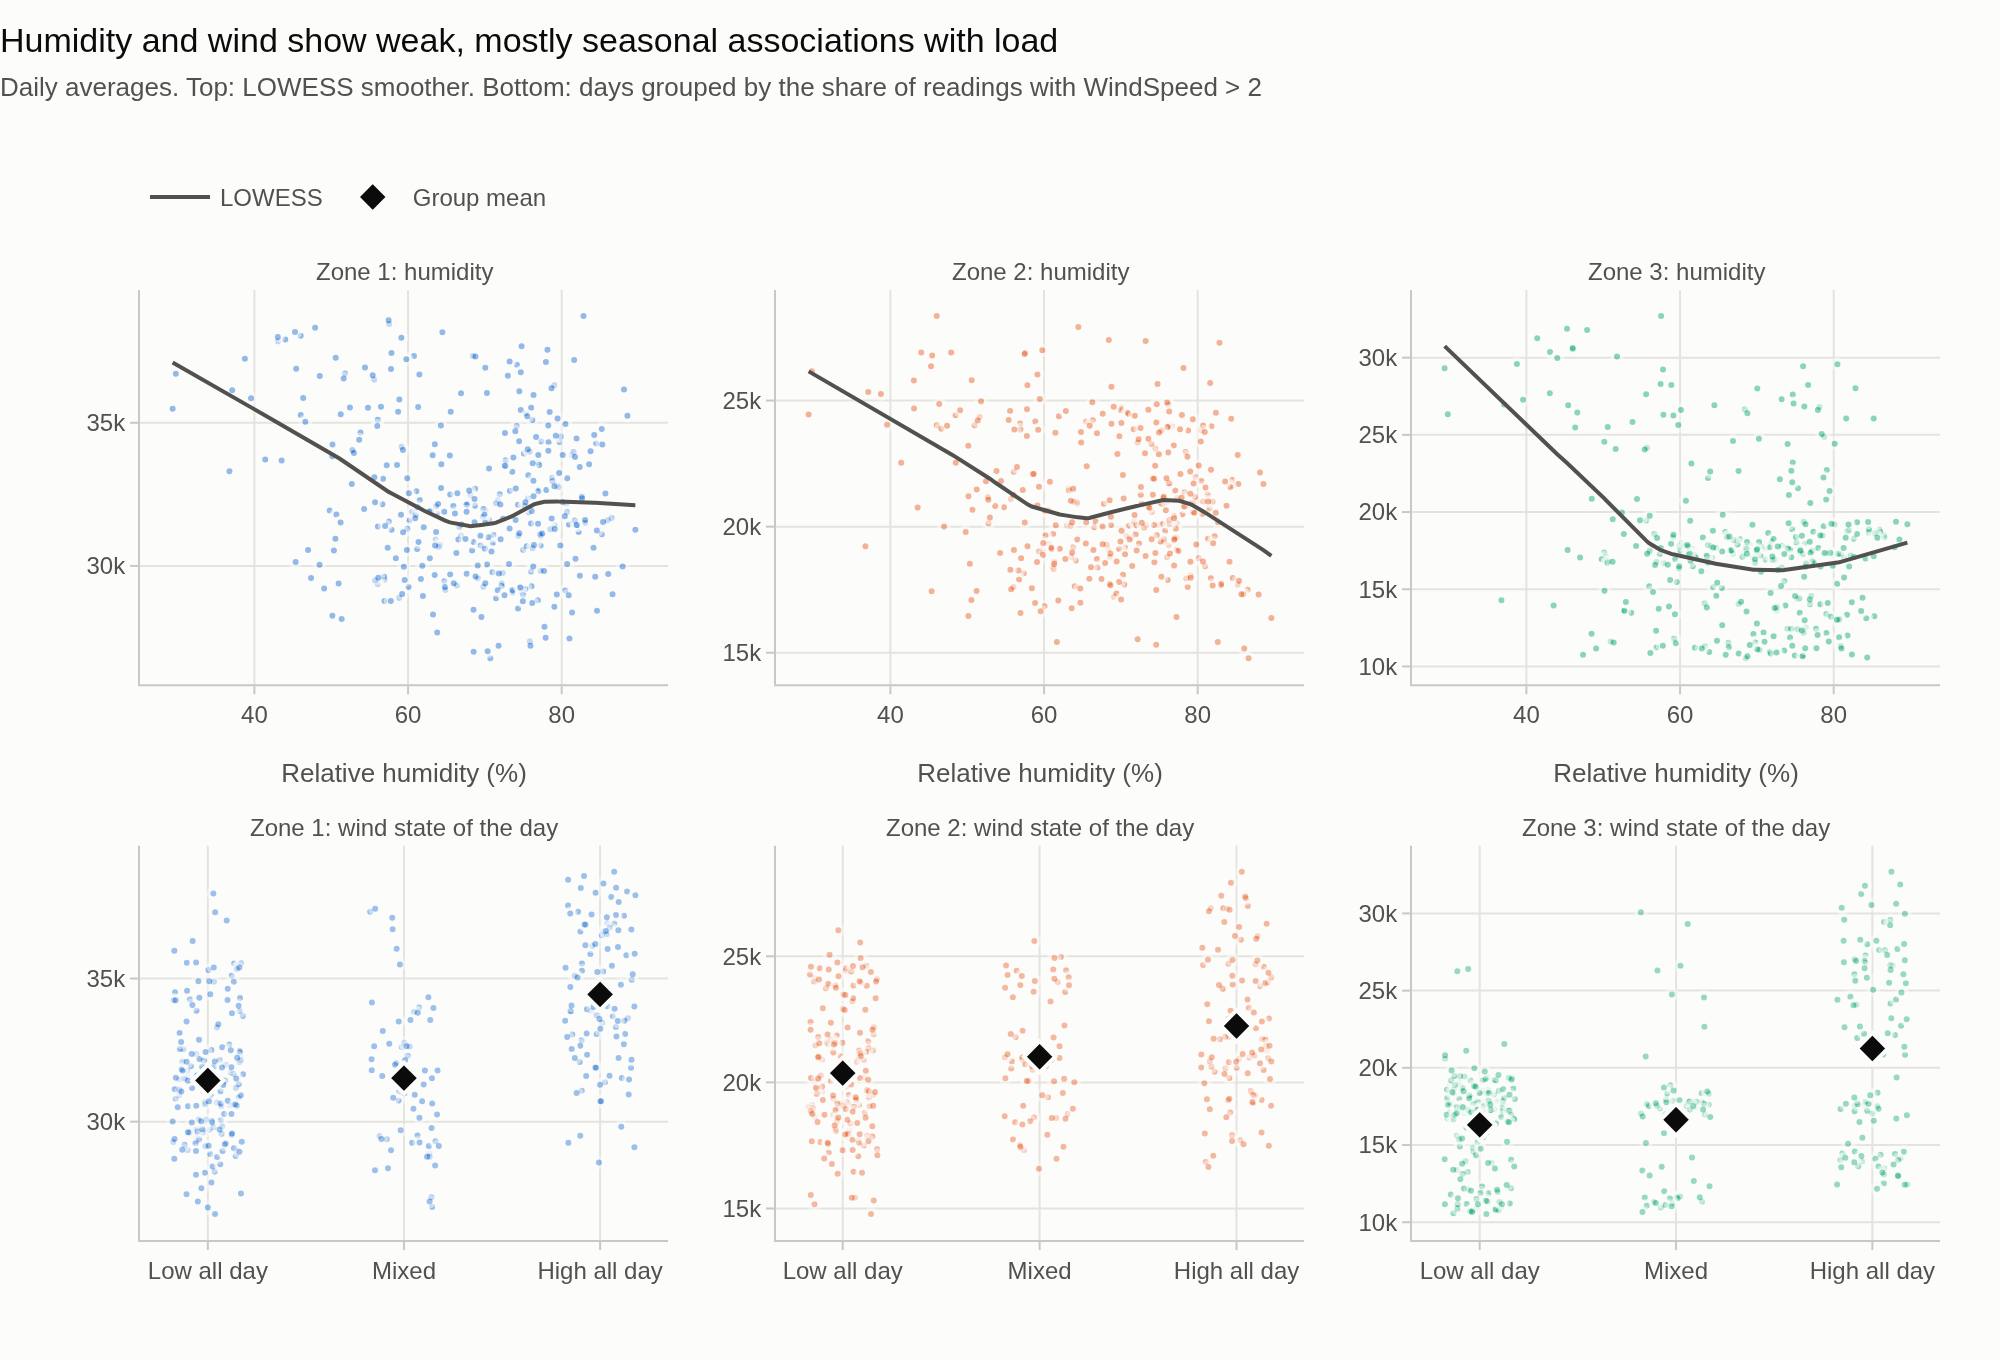

In [35]:
wind_group = pd.cut(daily["HighWindShare"], [-0.01, 0.0, 0.999, 1.0], labels=["Low all day", "Mixed", "High all day"])
fig = make_subplots(rows=2, cols=3, subplot_titles=[f"{ZN(z)}: humidity" for z in ZONES] + [f"{ZN(z)}: wind state of the day" for z in ZONES],
                    vertical_spacing=0.17, horizontal_spacing=0.06)
rng = np.random.default_rng(SEED)
for j, z in enumerate(ZONES, start=1):
    c = ch.ZONE_COLORS[z]
    fig.add_scatter(x=daily["Humidity"], y=daily[z], mode="markers", marker=dict(color=c, size=5, opacity=0.5),
                    customdata=daily["Date"].dt.strftime("%d %b"), showlegend=False,
                    hovertemplate="%{customdata}<br>%{x:.0f}%<br>%{y:,.0f} kW<extra></extra>", row=1, col=j)
    lw = lowess(daily[z], daily["Humidity"], frac=0.5)
    fig.add_scatter(x=lw[:, 0], y=lw[:, 1], mode="lines", line=dict(color=ch.TEXT_2, width=2),
                    name="LOWESS", showlegend=(j == 1), hoverinfo="skip", row=1, col=j)
    codes = wind_group.cat.codes.to_numpy()
    fig.add_scatter(x=codes + rng.uniform(-0.18, 0.18, len(codes)), y=daily[z], mode="markers",
                    marker=dict(color=c, size=5, opacity=0.45), showlegend=False,
                    customdata=np.c_[daily["Date"].dt.strftime("%d %b"), wind_group.astype(str)],
                    hovertemplate="%{customdata[0]} (%{customdata[1]})<br>%{y:,.0f} kW<extra></extra>", row=2, col=j)
    gm = daily.groupby(wind_group, observed=True)[z].mean()
    fig.add_scatter(x=list(range(len(gm))), y=gm.values, mode="markers", name="Group mean", showlegend=(j == 1),
                    marker=dict(symbol="diamond", size=12, color=ch.TEXT, line=dict(width=2, color=ch.SURFACE)),
                    hovertemplate="mean %{y:,.0f} kW<extra></extra>", row=2, col=j)
    fig.update_xaxes(tickvals=[0, 1, 2], ticktext=list(wind_group.cat.categories), row=2, col=j)
    for i in (1, 2):
        fig.update_yaxes(tickformat="~s", row=i, col=j)
fig.update_xaxes(title_text="Relative humidity (%)", row=1)
fig.update_annotations(font=dict(size=12, color=ch.TEXT_2))
fig.update_layout(title=ch.title("Humidity and wind show weak, mostly seasonal associations with load",
                                 "Daily averages. Top: LOWESS smoother. Bottom: days grouped by the share of readings with WindSpeed > 2"))
print(wind_group.value_counts().sort_index().to_string())
ch.save(fig, "17_humidity_wind_vs_load_daily", height=680);

**Change-point (degree-day) model.** On daily data the relationship is clearly **not linear**. Load is flat on cool days and starts rising once the daily mean temperature passes a base temperature. This is the cooling-demand pattern utilities model with "cooling degree days". The fitted model is *load = a + b × max(0, temperature − base)*, with 95% intervals from a 14-day block bootstrap:

| | Base temperature | Increase per °C above base | As % of cool-day load | R² |
|---|---|---|---|---|
| Zone 1 | 16.8 °C (14.6 to 18.3) | 550 kW (397 to 683) | 1.8% | 0.60 |
| Zone 2 | 22.5 °C (14.7 to 23.4) | 849 kW (226 to 1,113) | 4.2% | 0.28 |
| Zone 3 | 21.0 °C (18.7 to 23.2) | 1,683 kW (1,134 to 2,322) | **10.7%** | 0.58 |
| All three zones | 19.8 °C (18.1 to 22.4) | **2.6 MW** (1.6 to 3.8) | 3.9% | 0.71 |

Taken at face value, every degree of daily mean temperature above about 20 °C goes with **about 2.6 MW more load across the three zones**, and Zone 3 is by far the most temperature-sensitive relative to its size. Zone 2's fit is weak (R² 0.28) and its base temperature is poorly determined: much of Zone 2's variation is the autumn level change and the weekly cycle, not temperature.

**Humidity and wind (second chart).** Load is higher on the driest days. Those are hot summer days, so this is the temperature effect again. Days that are high-wind all day have higher average load than low-wind days, but high-wind days are concentrated in July and August. The next section tests whether any of this survives once the season is accounted for.

In [36]:
da = daily.copy()
for c in pp.ENV + ZONES:
    da[c] = daily[c] - daily.groupby("Month")[c].transform("mean")
wm = []
for z in ZONES:
    for v in pp.ENV:
        r = pp.corr_test(da[v], da[z], "spearman")
        wm.append({"zone": z, "variable": v, "rho_within_month": r["r"], "ci_low": r["ci_low"], "ci_high": r["ci_high"],
                   "n_eff": r["n_eff"], "p_adjusted": r["p_adjusted"]})
within_month = pd.DataFrame(wm)
within_month["p_holm"] = pp.holm(within_month["p_adjusted"])
within_month.to_csv(OUT / "correlations_within_month.csv", index=False)
within_month.round(3)

,zone,variable,rho_within_month,ci_low,ci_high,n_eff,p_adjusted,p_holm
0,Zone1,Temperature,0.076,-0.066,0.215,193.072,0.291,1.000
1,Zone1,Humidity,-0.072,-0.210,0.068,197.136,0.311,1.000
2,Zone1,WindSpeed,-0.032,-0.193,0.131,147.027,0.701,1.000
3,Zone2,Temperature,0.004,-0.137,0.145,193.971,0.958,1.000
4,Zone2,Humidity,-0.073,-0.211,0.068,196.649,0.310,1.000
5,Zone2,WindSpeed,-0.063,-0.225,0.101,144.303,0.450,1.000
6,Zone3,Temperature,0.188,0.013,0.353,126.438,0.034,0.309
7,Zone3,Humidity,-0.077,-0.240,0.091,139.475,0.369,1.000
8,Zone3,WindSpeed,0.003,-0.207,0.213,87.338,0.977,1.000


In [37]:
hh = hourly.assign(WindHigh=(hourly["HighWindShare"] > 0.5).astype(int), Ramadan=hourly["IsRamadan"].astype(int),
                   Holiday=hourly["IsHoliday"].astype(int), Irradiance=hourly["GeneralDiffuseFlows"] / 100)
specs = {
    "A: weather only": "{z} ~ Temperature + Humidity + WindHigh",
    "B: + hour, weekday": "{z} ~ Temperature + Humidity + WindHigh + C(Hour) + C(DayOfWeek)",
    "C: + hour, weekday, month, Ramadan, holiday": "{z} ~ Temperature + Humidity + WindHigh + C(Hour) + C(DayOfWeek) + C(Month) + Ramadan + Holiday",
    "D: C + irradiance": "{z} ~ Temperature + Humidity + WindHigh + Irradiance + C(Hour) + C(DayOfWeek) + C(Month) + Ramadan + Holiday",
}
reg = []
for z in ZONES:
    for name, f in specs.items():
        m = smf.ols(f.format(z=z), data=hh).fit(cov_type="HAC", cov_kwds={"maxlags": 48})
        ci = m.conf_int()
        for v in ["Temperature", "Humidity", "WindHigh"]:
            reg.append({"zone": z, "model": name, "term": v, "coef_kW": m.params[v], "ci_low": ci.loc[v, 0],
                        "ci_high": ci.loc[v, 1], "p_HAC": m.pvalues[v], "r2": m.rsquared, "n": int(m.nobs)})
regression = pd.DataFrame(reg)
regression.to_csv(OUT / "regression_hac.csv", index=False)
regression.pivot_table(index=["term", "model"], columns="zone", values="coef_kW").round(1)

zone                                                       Zone1    Zone2     Zone3
term        model                                                                  
Humidity    A: weather only                              -48.200  -50.200    -7.800
            B: + hour, weekday                            22.100    0.100    -5.300
            C: + hour, weekday, month, Ramadan, holiday    0.300   -1.000    -2.100
            D: C + irradiance                             -5.600   -4.400    -4.200
Temperature A: weather only                              506.500  293.000   513.900
            B: + hour, weekday                           326.600  167.100   468.300
            C: + hour, weekday, month, Ramadan, holiday   -2.300  -17.000   100.400
            D: C + irradiance                             25.500   -1.000   109.900
WindHigh    A: weather only                             -633.400 -305.100   878.800
            B: + hour, weekday                           681.600  631.400 1,240.000
            C: + hour, weekday, month, Ramadan, holiday   44.900 -122.200  -117.300
            D: C + irradiance                             76.400 -104.000  -106.600

In [38]:
regression.pivot_table(index=["term", "model"], columns="zone", values="p_HAC").round(4)

zone                                                     Zone1  Zone2  Zone3
term        model                                                           
Humidity    A: weather only                              0.000  0.000  0.651
            B: + hour, weekday                           0.002  0.995  0.783
            C: + hour, weekday, month, Ramadan, holiday  0.954  0.847  0.792
            D: C + irradiance                            0.257  0.395  0.604
Temperature A: weather only                              0.000  0.000  0.000
            B: + hour, weekday                           0.000  0.000  0.000
            C: + hour, weekday, month, Ramadan, holiday  0.918  0.516  0.001
            D: C + irradiance                            0.259  0.972  0.001
WindHigh    A: weather only                              0.034  0.370  0.124
            B: + hour, weekday                           0.007  0.036  0.031
            C: + hour, weekday, month, Ramadan, holiday  0.773  0.333  0.451
            D: C + irradiance                            0.634  0.416  0.503

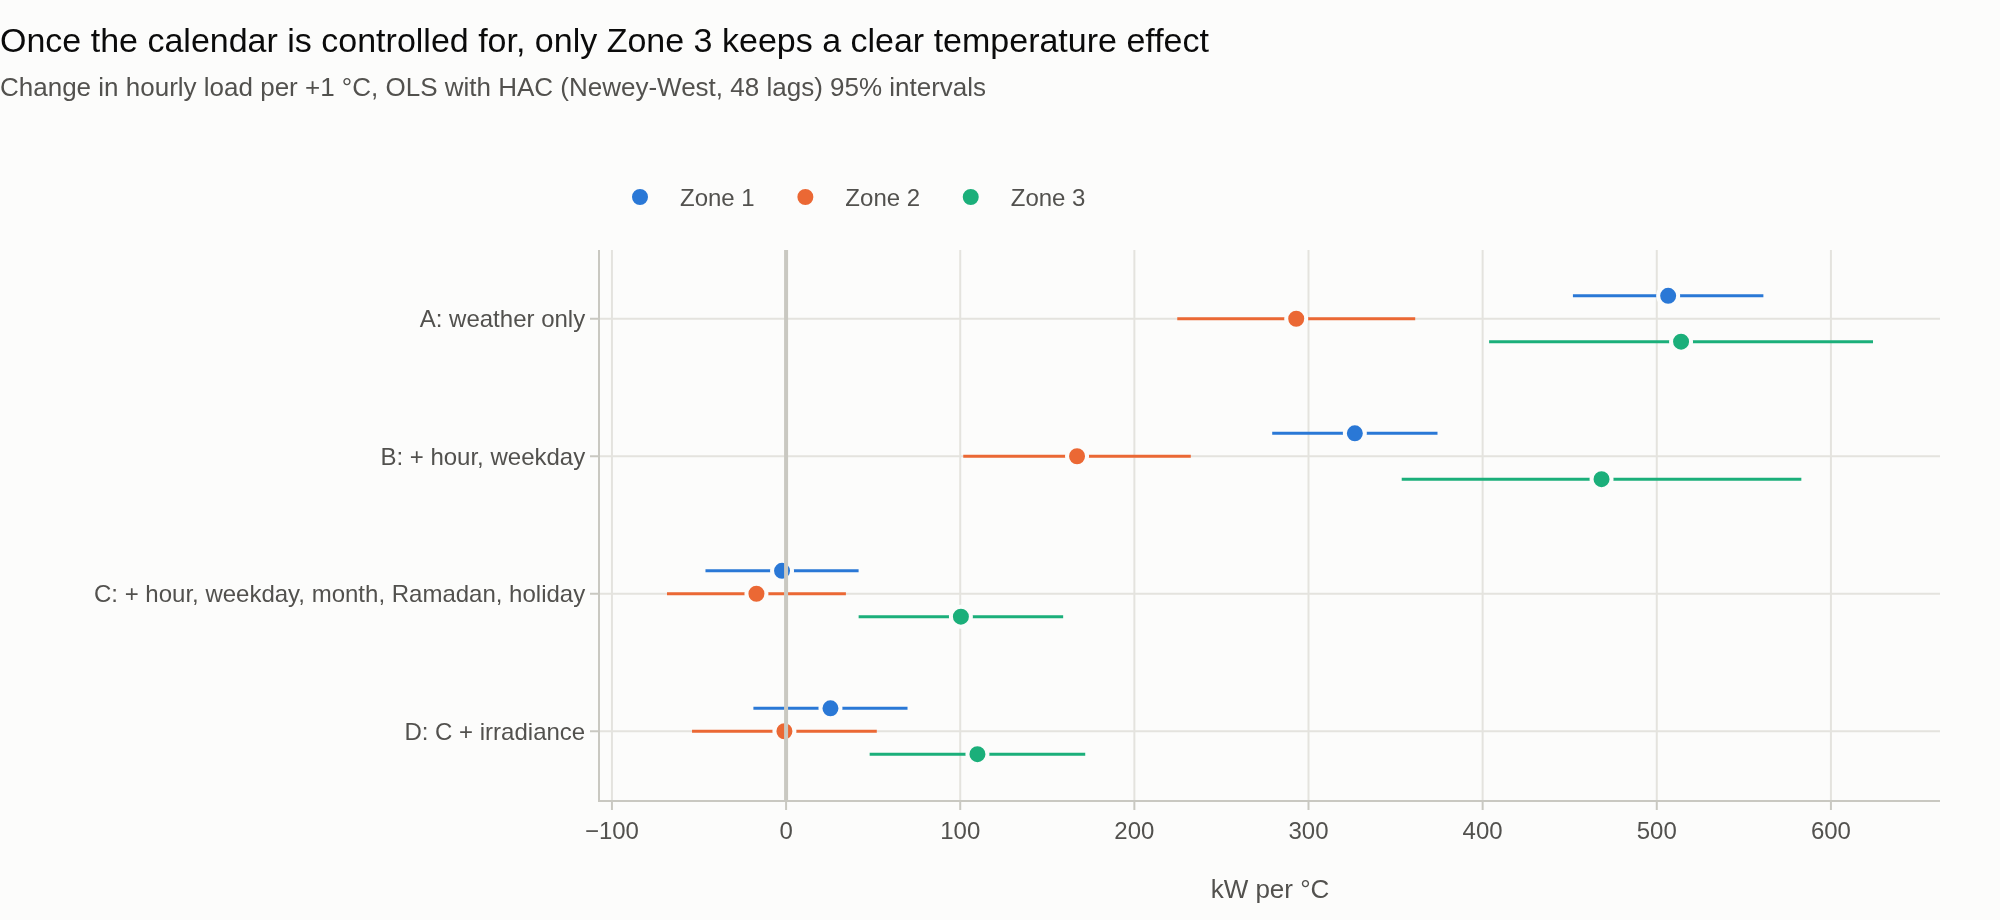

In [39]:
t = regression[regression.term == "Temperature"]
fig = go.Figure()
for z in ZONES:
    s = t[t.zone == z]
    fig.add_scatter(x=s.coef_kW, y=s.model, mode="markers", name=ZN(z), orientation="h", marker=dict(size=10, color=ch.ZONE_COLORS[z]),
                    error_x=dict(type="data", symmetric=False, array=s.ci_high - s.coef_kW, arrayminus=s.coef_kW - s.ci_low,
                                 color=ch.ZONE_COLORS[z], thickness=1.5, width=0),
                    customdata=np.c_[s.p_HAC, s.r2], hovertemplate="%{x:.0f} kW per °C<br>p = %{customdata[0]:.3g}<br>R² = %{customdata[1]:.2f}<extra></extra>")
fig.add_vline(x=0, line_color=ch.AXIS)
fig.update_layout(title=ch.title("Once the calendar is controlled for, only Zone 3 keeps a clear temperature effect",
                                 "Change in hourly load per +1 °C, OLS with HAC (Newey-West, 48 lags) 95% intervals"),
                  xaxis_title="kW per °C", margin=dict(l=300), scattermode="group", scattergap=0.5)
fig.update_yaxes(autorange="reversed")
ch.save(fig, "18_temperature_effect_by_model", height=460);

In [40]:
wind_month = daily.groupby("MonthName", observed=True)["HighWindShare"].mean()
cells = hourly.assign(High=hourly["HighWindShare"] > 0.5).groupby(["Month", "Hour", "High"])[ZONES].agg(["mean", "size"])
ws = []
for z in ZONES:
    m = cells[z].unstack("High").dropna()
    diff = m[("mean", True)] - m[("mean", False)]
    w = np.minimum(m[("size", True)], m[("size", False)])
    raw_diff = hourly.loc[hourly.HighWindShare > 0.5, z].mean() - hourly.loc[hourly.HighWindShare <= 0.5, z].mean()
    ws.append({"zone": z, "raw_difference_kW": raw_diff, "within_month_hour_difference_kW": np.average(diff, weights=w),
               "cells_compared": len(m), "share_of_cells_high_higher": (diff > 0).mean()})
wind_effect = pd.DataFrame(ws).set_index("zone")
wind_effect.to_csv(OUT / "wind_state_effect.csv")
print("Share of readings in the high-wind state by month:")
print(wind_month.map("{:.0%}".format).to_string())
wind_effect

Share of readings in the high-wind state by month:
MonthName
Jan    13%
Feb    21%
Mar    19%
Apr     3%
May    46%
Jun    31%
Jul    94%
Aug    92%
Sep    57%
Oct    56%
Nov    25%
Dec     4%


,raw_difference_kW,within_month_hour_difference_kW,cells_compared,share_of_cells_high_higher
zone,,,,
Zone1,"2,445.423",-157.974,275,0.396
Zone2,"1,571.499",-261.193,275,0.258
Zone3,"3,826.181",-60.350,275,0.411


**Does the association survive once the calendar is accounted for?** This is the key question, because temperature, humidity, the high-wind state, Ramadan, school holidays and the summer tourist season all peak at the same time of year. Three checks:

1. **Within-month correlation (daily data, each value minus its month's mean).** Within the same month, warmer days do **not** have noticeably higher load in Zones 1 and 2 (ρ = 0.08 and 0.00). Zone 3 keeps a weak positive association (ρ = 0.19, p = 0.03 before correction, 0.31 after Holm).
2. **Regression with HAC standard errors (hourly data).** OLS with Newey-West standard errors (48 lags) gives valid inference under serial correlation. Adding controls step by step (model A to model D):
   - With weather alone (A), temperature looks strong: +507, +293 and +514 kW per °C.
   - Adding hour and weekday (B) reduces it but leaves it clearly significant.
   - Adding **month, Ramadan and holidays (C)** removes it for **Zones 1 and 2** (−2 and −17 kW per °C, p = 0.92 and 0.52). **Zone 3 keeps a significant effect of about +100 kW per °C** (95% CI +42 to +159, p < 0.001), and this holds when irradiance is added (D).
   - Humidity and the wind state are not significant in any zone once the calendar is in the model (all p > 0.25).
3. **Wind compared within the same month and hour.** High-wind hours average 1.6 to 3.8 MW more load than low-wind hours overall. Within the same month and hour, the difference **reverses to −60 to −260 kW**. The raw difference exists because 92% to 94% of July and August readings are in the high-wind state, against 3% to 4% in April and December. It is a seasonal artefact.

**Conclusion on the environmental question.** Temperature is the only environmental variable with a meaningful association with load. Its association mainly reflects the **shared seasonal cycle**: hot months are also the months of Ramadan in 2017, school holidays and summer visitors, and within a month, day-to-day temperature adds little to Zones 1 and 2. **Zone 3 is the exception**: hotter days within the same month are associated with higher load, consistent with temperature-driven demand such as cooling. Month controls are conservative, because they also absorb the part of the seasonal effect that *is* caused by temperature. The true weather effect for Zones 1 and 2 probably lies between models B and C, and one year of data cannot separate them. None of these results show causation: they are associations in observational data, and important drivers (tourism, occupancy, tariffs, network changes) are not measured.

## 7. Comparative zone analysis (Task 5)

All three zones are measured at the same timestamps, so comparisons are **paired**: each day contributes one value per zone. Rank-based paired tests (Friedman across the three zones, Wilcoxon signed-rank for pairs with Holm correction) are used, with effect sizes, and the level differences are given 95% **moving-block bootstrap** intervals (7-day blocks) that keep the week-to-week dependence.

### 7.1 Level and variability

In [41]:
D = daily[ZONES].to_numpy()
fr = stats.friedmanchisquare(*D.T)
pairs = [("Zone1", "Zone2"), ("Zone1", "Zone3"), ("Zone2", "Zone3")]
pc = []
for a, b in pairs:
    i, j = ZONES.index(a), ZONES.index(b)
    wil = stats.wilcoxon(daily[a], daily[b])
    boot = pp.block_bootstrap(D, lambda x: x[:, i].mean() - x[:, j].mean(), block=7, n_boot=2000, seed=SEED)
    lo, hi = pp.percentile_ci(boot)
    pc.append({"comparison": f"{a} - {b}", "mean_difference_kW": daily[a].mean() - daily[b].mean(),
               "ci_low": lo, "ci_high": hi, "days_a_higher": (daily[a] > daily[b]).mean(),
               "wilcoxon_p": wil.pvalue, "rank_biserial": pp.rank_biserial_paired(daily[a], daily[b])})
zone_means_cmp = pd.DataFrame(pc)
zone_means_cmp["wilcoxon_p_holm"] = pp.holm(zone_means_cmp["wilcoxon_p"])
zone_means_cmp.to_csv(OUT / "zone_mean_comparison.csv", index=False)
key("friedman_zones_daily_chi2", fr.statistic, "Friedman chi-square, daily mean load across the 3 zones")
print(f"Friedman test across zones (364 days as blocks): chi2 = {fr.statistic:.1f}, p = {fr.pvalue:.2g}, "
      f"Kendall's W = {pp.kendalls_w(fr.statistic, len(D), 3):.3f}")
zone_means_cmp

Friedman test across zones (364 days as blocks): chi2 = 586.6, p = 4.1e-128, Kendall's W = 0.806


,comparison,mean_difference_kW,ci_low,ci_high,days_a_higher,wilcoxon_p,rank_biserial,wilcoxon_p_holm
0,Zone1 - Zone2,"11,302.461","10,568.305","12,072.917",1.000,0.000,1.000,0.000
1,Zone1 - Zone3,"14,509.564","13,598.904","15,391.160",1.000,0.000,1.000,0.000
2,Zone2 - Zone3,"3,207.103","1,882.651","4,530.852",0.736,0.000,0.633,0.000


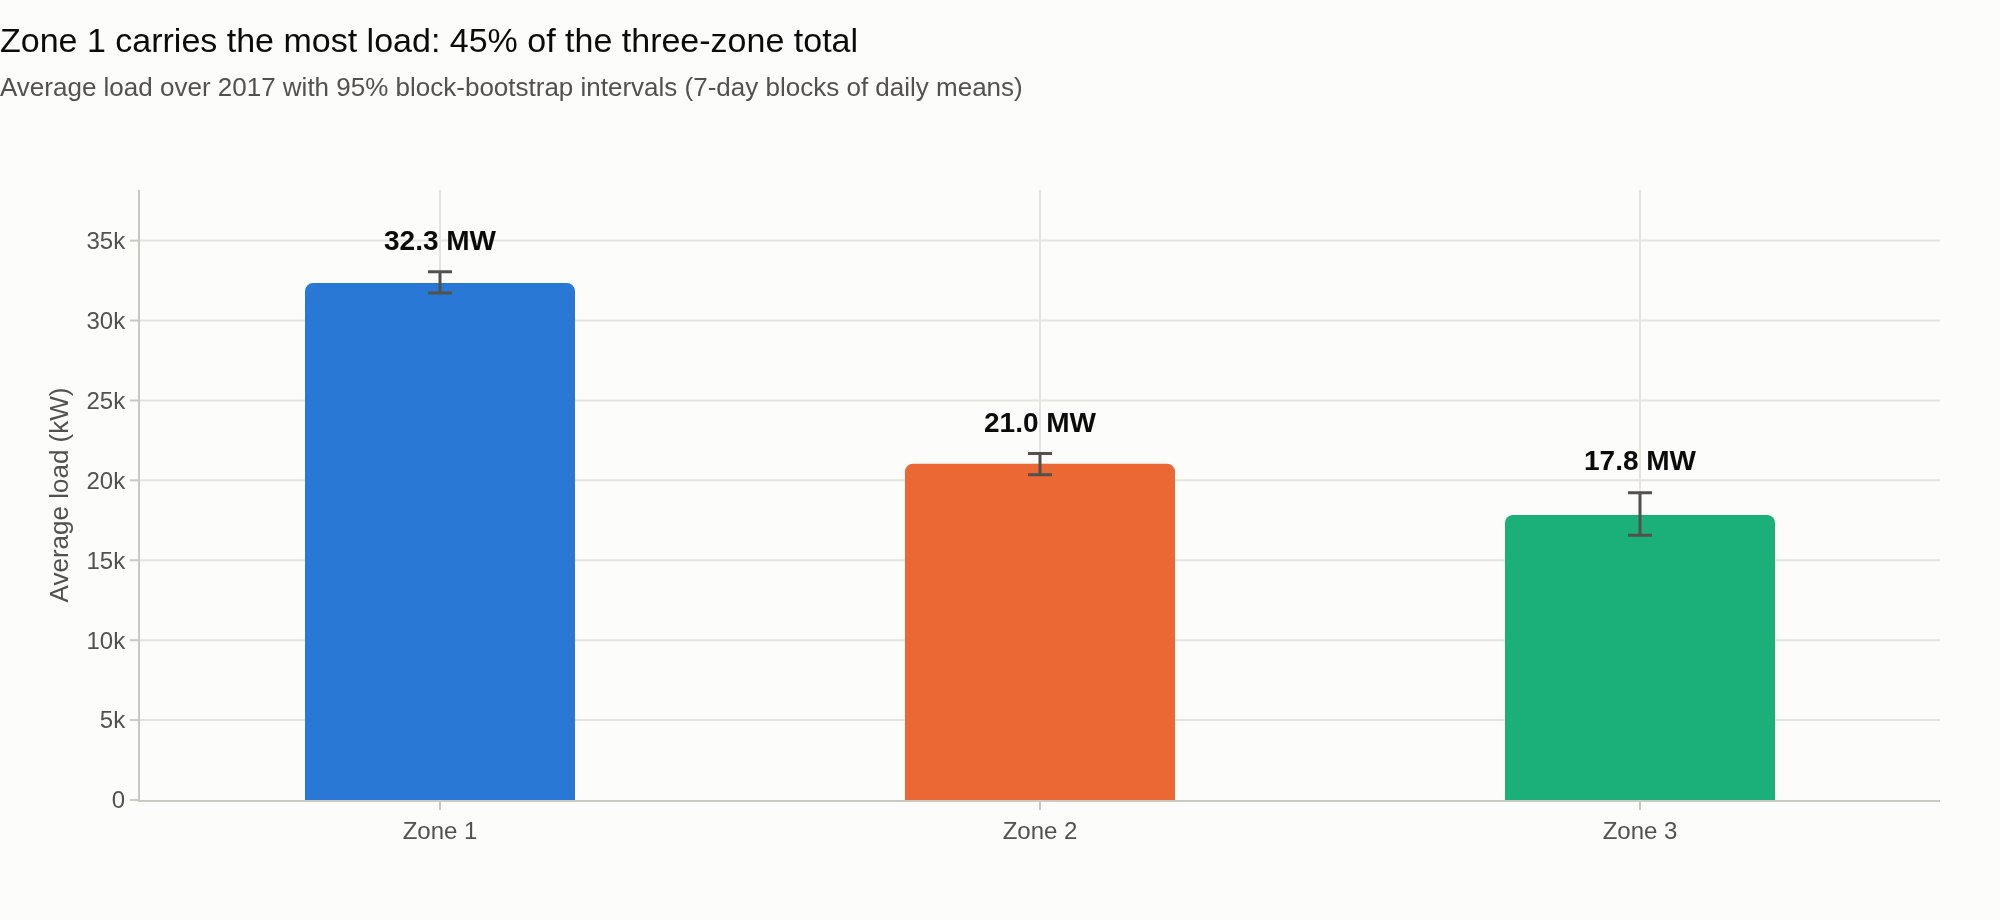

Zone1    45.4%
Zone2    29.5%
Zone3    25.0%
dtype: str

In [42]:
means = daily[ZONES].mean()
ci = {z: pp.percentile_ci(pp.block_bootstrap(daily[z].to_numpy(), lambda x: x.mean(), block=7, seed=SEED)) for z in ZONES}
fig = go.Figure(go.Bar(x=[ZN(z) for z in ZONES], y=means, marker_color=[ch.ZONE_COLORS[z] for z in ZONES], width=0.45,
                       error_y=dict(type="data", symmetric=False, array=[ci[z][1] - means[z] for z in ZONES],
                                    arrayminus=[means[z] - ci[z][0] for z in ZONES], color=ch.TEXT_2, thickness=1.5, width=6),
                       hovertemplate="%{x}: %{y:,.0f} kW<extra></extra>"))
for z in ZONES:
    fig.add_annotation(x=ZN(z), y=ci[z][1], text=f"<b>{means[z]/1000:.1f} MW</b>", showarrow=False, yanchor="bottom",
                       yshift=6, font=dict(color=ch.TEXT, size=14))
fig.update_layout(title=ch.title("Zone 1 carries the most load: 45% of the three-zone total",
                                 "Average load over 2017 with 95% block-bootstrap intervals (7-day blocks of daily means)"),
                  showlegend=False)
fig.update_traces(marker_cornerradius=4)
ch.kw_axis(fig)
fig.update_yaxes(range=[0, means.max() * 1.18])
ch.save(fig, "19_average_load_by_zone", height=460);
share = means / means.sum()
for z in ZONES:
    key(f"{z}_share_of_total", share[z], f"{z} share of the three-zone mean load")
share.map("{:.1%}".format)

In [43]:
blocks = np.stack([df[z].to_numpy().reshape(364, 144) for z in ZONES], axis=2)  # day x reading x zone

def cv_all(b):
    x = b.reshape(-1, 3)
    return x.std(axis=0, ddof=1) / x.mean(axis=0)

cv_boot = pp.block_bootstrap(blocks.reshape(364, -1), lambda a: cv_all(a.reshape(-1, 144, 3)), block=7, n_boot=1000, seed=SEED)
cv_lo, cv_hi = pp.percentile_ci(cv_boot)
ratio_32 = cv_boot[:, 2] / cv_boot[:, 1]
ratio_31 = cv_boot[:, 2] / cv_boot[:, 0]
within_day_sd = pd.Series({z: df.groupby("Date")[z].std().mean() for z in ZONES})
variab = pd.DataFrame({
    "sd_kW": desc10.loc[ZONES, "std"], "iqr_kW": desc10.loc[ZONES, "iqr"], "cv": desc10.loc[ZONES, "cv"],
    "cv_ci_low": cv_lo, "cv_ci_high": cv_hi, "daily_mean_cv": desc_d.loc[ZONES, "cv"],
    "mean_within_day_sd_kW": within_day_sd, "range_of_monthly_means_kW": monthly[ZONES].max() - monthly[ZONES].min(),
})
variab.to_csv(OUT / "zone_variability.csv")
for z in ZONES:
    key(f"{z}_cv", desc10.loc[z, "cv"], f"{z} coefficient of variation of 10-minute readings")
lev = stats.levene(*(daily[z] / daily[z].mean() for z in ZONES), center="median")
print(f"CV ratio Zone 3 / Zone 2: {np.median(ratio_32):.2f} (95% CI {np.percentile(ratio_32, 2.5):.2f}-{np.percentile(ratio_32, 97.5):.2f})")
print(f"CV ratio Zone 3 / Zone 1: {np.median(ratio_31):.2f} (95% CI {np.percentile(ratio_31, 2.5):.2f}-{np.percentile(ratio_31, 97.5):.2f})")
print(f"Brown-Forsythe test on daily loads scaled by zone mean: W = {lev.statistic:.1f}, p = {lev.pvalue:.2g} (indicative; days are serially correlated)")
variab

CV ratio Zone 3 / Zone 2: 1.50 (95% CI 1.36-1.63)
CV ratio Zone 3 / Zone 1: 1.68 (95% CI 1.53-1.83)
Brown-Forsythe test on daily loads scaled by zone mean: W = 102.2, p = 2.2e-41 (indicative; days are serially correlated)


,sd_kW,iqr_kW,cv,cv_ci_low,cv_ci_high,daily_mean_cv,mean_within_day_sd_kW,range_of_monthly_means_kW
Zone1,"7,130.563","10,998.349",0.220,0.215,0.224,0.083,"6,611.992","7,433.083"
Zone2,"5,201.466","7,732.951",0.247,0.238,0.254,0.129,"4,400.950","7,022.250"
Zone3,"6,622.165","8,494.774",0.371,0.336,0.402,0.275,"4,315.879","17,149.305"


**Which zone has the highest average load?** **Zone 1**, at 32.3 MW, which is 45% of the three-zone total. It is higher than Zone 2 on **every one of the 364 days** (by 11.3 MW on average, 95% CI 10.6 to 12.1) and higher than Zone 3 on every day (by 14.5 MW, 13.6 to 15.4). Zone 2 (21.0 MW, 30%) is above Zone 3 (17.8 MW, 25%) on average by 3.2 MW (1.9 to 4.5), but **only on 74% of days**: Zone 3 is higher on 96 days, mostly in July (31 days), April (23), August (16) and June (12). The Friedman test across the three zones is overwhelming (χ² = 587, Kendall's W = 0.81), and every pairwise Wilcoxon test is significant after Holm correction. The ranking Zone 1 > Zone 2 > Zone 3 holds for the year, but not every day.

**Which zone has the greatest variability?** It depends on the measure, and the distinction matters:
- **In absolute terms (kW), Zone 1**: SD 7.1 MW and IQR 11.0 MW, because it is the largest zone and has the largest daily swing.
- **Relative to its size, Zone 3**: CV 0.37 (95% CI 0.34 to 0.40), against 0.25 for Zone 2 and 0.22 for Zone 1. Block-bootstrap ratios: Zone 3's CV is **1.50 times** Zone 2's (1.36 to 1.63) and **1.68 times** Zone 1's (1.53 to 1.83), and neither interval comes near 1. Zone 3's monthly means span 17.1 MW, more than twice the range of either other zone.

For planning, relative variability is the more useful measure: it says how much spare capacity a zone needs per unit of average demand.

In [44]:
prof_n = hourly_profile[ZONES] / hourly_profile[ZONES].mean()
day_stats = []
for z in ZONES:
    g = df.groupby("Date")[z]
    day_stats.append(pd.DataFrame({"zone": z, "peak_over_trough": g.max() / g.min(),
                                   "peak_hour": df.loc[g.idxmax(), "Hour"].to_numpy()}))
day_stats = pd.concat(day_stats)
ptt = day_stats.pivot_table(index=day_stats.index, columns="zone", values="peak_over_trough")
fr_ptt = stats.friedmanchisquare(*[ptt[z] for z in ZONES])
shape = pd.DataFrame({
    "median_daily_peak_over_trough": ptt.median(),
    "share_of_days_peak_19_to_21h": day_stats.groupby("zone")["peak_hour"].apply(lambda h: h.between(19, 21).mean()),
    "evening_peak_index": prof_n.loc[20],
    "early_morning_index": prof_n.loc[6],
    "midday_index": prof_n.loc[12],
})
shape.to_csv(OUT / "zone_profile_shape.csv")
print(f"Friedman test, daily peak/trough ratio across zones: chi2 = {fr_ptt.statistic:.1f}, p = {fr_ptt.pvalue:.2g}, "
      f"W = {pp.kendalls_w(fr_ptt.statistic, len(ptt), 3):.2f}")
pw = [{"pair": f"{a} vs {b}", "wilcoxon_p": stats.wilcoxon(ptt[a], ptt[b]).pvalue,
       "rank_biserial": pp.rank_biserial_paired(ptt[a], ptt[b])} for a, b in pairs]
pw = pd.DataFrame(pw)
pw["p_holm"] = pp.holm(pw["wilcoxon_p"])
display(shape)
pw

Friedman test, daily peak/trough ratio across zones: chi2 = 484.7, p = 5.5e-106, W = 0.67


,median_daily_peak_over_trough,share_of_days_peak_19_to_21h,evening_peak_index,early_morning_index,midday_index
Zone1,2.052,0.728,1.355,0.717,1.084
Zone2,2.081,0.695,1.340,0.710,1.087
Zone3,2.437,0.879,1.459,0.676,0.990


,pair,wilcoxon_p,rank_biserial,p_holm
0,Zone1 vs Zone2,0.000,-0.304,0.000
1,Zone1 vs Zone3,0.000,-0.985,0.000
2,Zone2 vs Zone3,0.000,-0.963,0.000


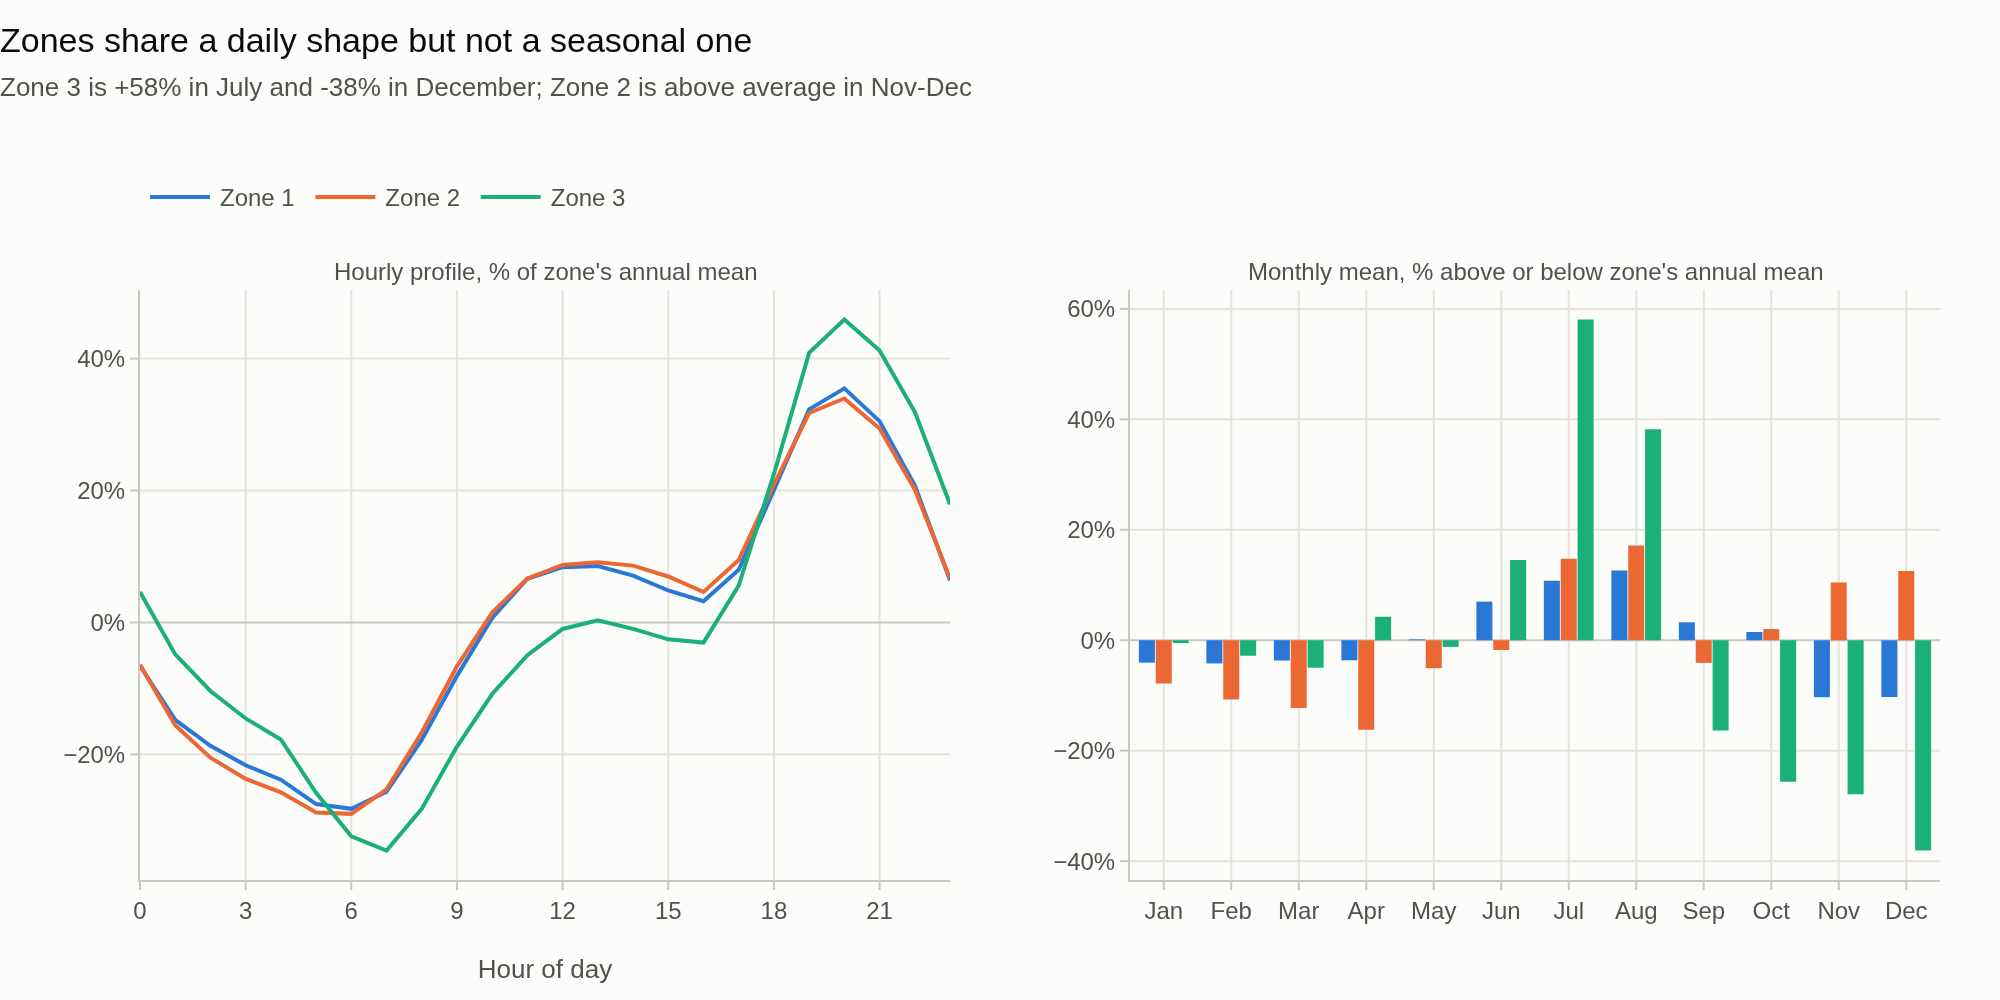

MonthName,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Zone1,-4.100,-4.200,-3.700,-3.600,0.200,7.000,10.800,12.600,3.300,1.500,-10.300,-10.300
Zone2,-7.800,-10.700,-12.300,-16.200,-5.100,-1.800,14.800,17.200,-4.100,2.000,10.400,12.500
Zone3,-0.500,-2.800,-5.000,4.200,-1.200,14.600,58.100,38.200,-16.300,-25.600,-27.900,-38.100


In [45]:
mi = (monthly[ZONES] / daily[ZONES].mean() - 1) * 100
fig = make_subplots(rows=1, cols=2, subplot_titles=["Hourly profile, % of zone's annual mean",
                                                    "Monthly mean, % above or below zone's annual mean"], horizontal_spacing=0.1)
for z in ZONES:
    fig.add_scatter(x=prof_n.index, y=(prof_n[z] - 1) * 100, name=ZN(z), line_color=ch.ZONE_COLORS[z], row=1, col=1)
    fig.add_bar(x=mi.index.astype(str), y=mi[z], name=ZN(z), marker_color=ch.ZONE_COLORS[z], showlegend=False, row=1, col=2)
fig.update_xaxes(title_text="Hour of day", dtick=3, row=1, col=1)
fig.update_yaxes(ticksuffix="%", zeroline=True, zerolinecolor=ch.AXIS)
fig.update_annotations(font=dict(size=12, color=ch.TEXT_2))
fig.update_layout(title=ch.title("Zones share a daily shape but not a seasonal one",
                                 "Zone 3 is +58% in July and -38% in December; Zone 2 is above average in Nov-Dec"),
                  barmode="group", bargap=0.25, bargroupgap=0.05)
ch.save(fig, "20_zone_shape_comparison", height=500);
for z in ZONES:
    key(f"{z}_jul_index_pct", mi.loc["Jul", z], f"{z} July mean vs annual mean (%)")
mi.round(1).T

In [46]:
zc = pd.DataFrame({lvl: [stats.spearmanr(d_[a], d_[b]).statistic for a, b in pairs]
                   for lvl, d_ in levels.items()}, index=[f"{a} vs {b}" for a, b in pairs])
dd_ = d_idx[ZONES].copy()
diff_corr = dd_.diff().corr(method="spearman")
print("Spearman correlation between zones' day-to-day changes:")
print(diff_corr.round(2).to_string())
zc.round(3)

Spearman correlation between zones' day-to-day changes:
       Zone1  Zone2  Zone3
Zone1  1.000  0.540  0.160
Zone2  0.540  1.000 -0.010
Zone3  0.160 -0.010  1.000


,10-minute,hourly,daily
Zone1 vs Zone2,0.851,0.851,0.302
Zone1 vs Zone3,0.748,0.748,0.618
Zone2 vs Zone3,0.538,0.535,-0.014


**Are the hourly patterns different?** The *timing* is shared: all three zones bottom out at 06:00 to 07:00 and peak at 20:00. The *shape* is not.
- **Zone 3 has the sharpest daily cycle.** Its median daily peak-to-trough ratio is 2.44, against 2.05 for Zone 1 and 2.08 for Zone 2 (Friedman χ² = 485, W = 0.67; Zone 3 against each other zone: rank-biserial ≈ 0.96 to 0.99, so Zone 3's ratio is higher on almost every day). Its evening peak is 46% above its mean, and its midday load is only at its mean. It also peaks between 19:00 and 21:00 on 88% of days, against about 70% for the others.
- **Zones 1 and 2 have nearly identical daily shapes,** with a pronounced midday plateau (+8% to +9% above the mean). This is typical of mixed commercial and residential areas. The small difference between them is significant (rank-biserial 0.30) but not important in practice.

**Are the monthly patterns different?** Yes, much more than the hourly ones. Zone 3 is +58% above its annual mean in July and −38% in December. Zone 1 ranges only from +13% to −10%. Zone 2 has two high seasons: summer (+15% to +17%) and November to December (+10% to +13%).

**How closely do the zones move together?** At the 10-minute and hourly level they are strongly correlated (Zone 1 with Zone 2: 0.85), because they share the daily cycle. At the **daily** level, Zone 2 and Zone 3 are **uncorrelated** (ρ = −0.01), and their day-to-day changes are unrelated as well. Beyond the shared clock, the zones are driven by different things, so they need separate plans and separate forecasts.

### 7.4 A change in the zones' base load after the summer

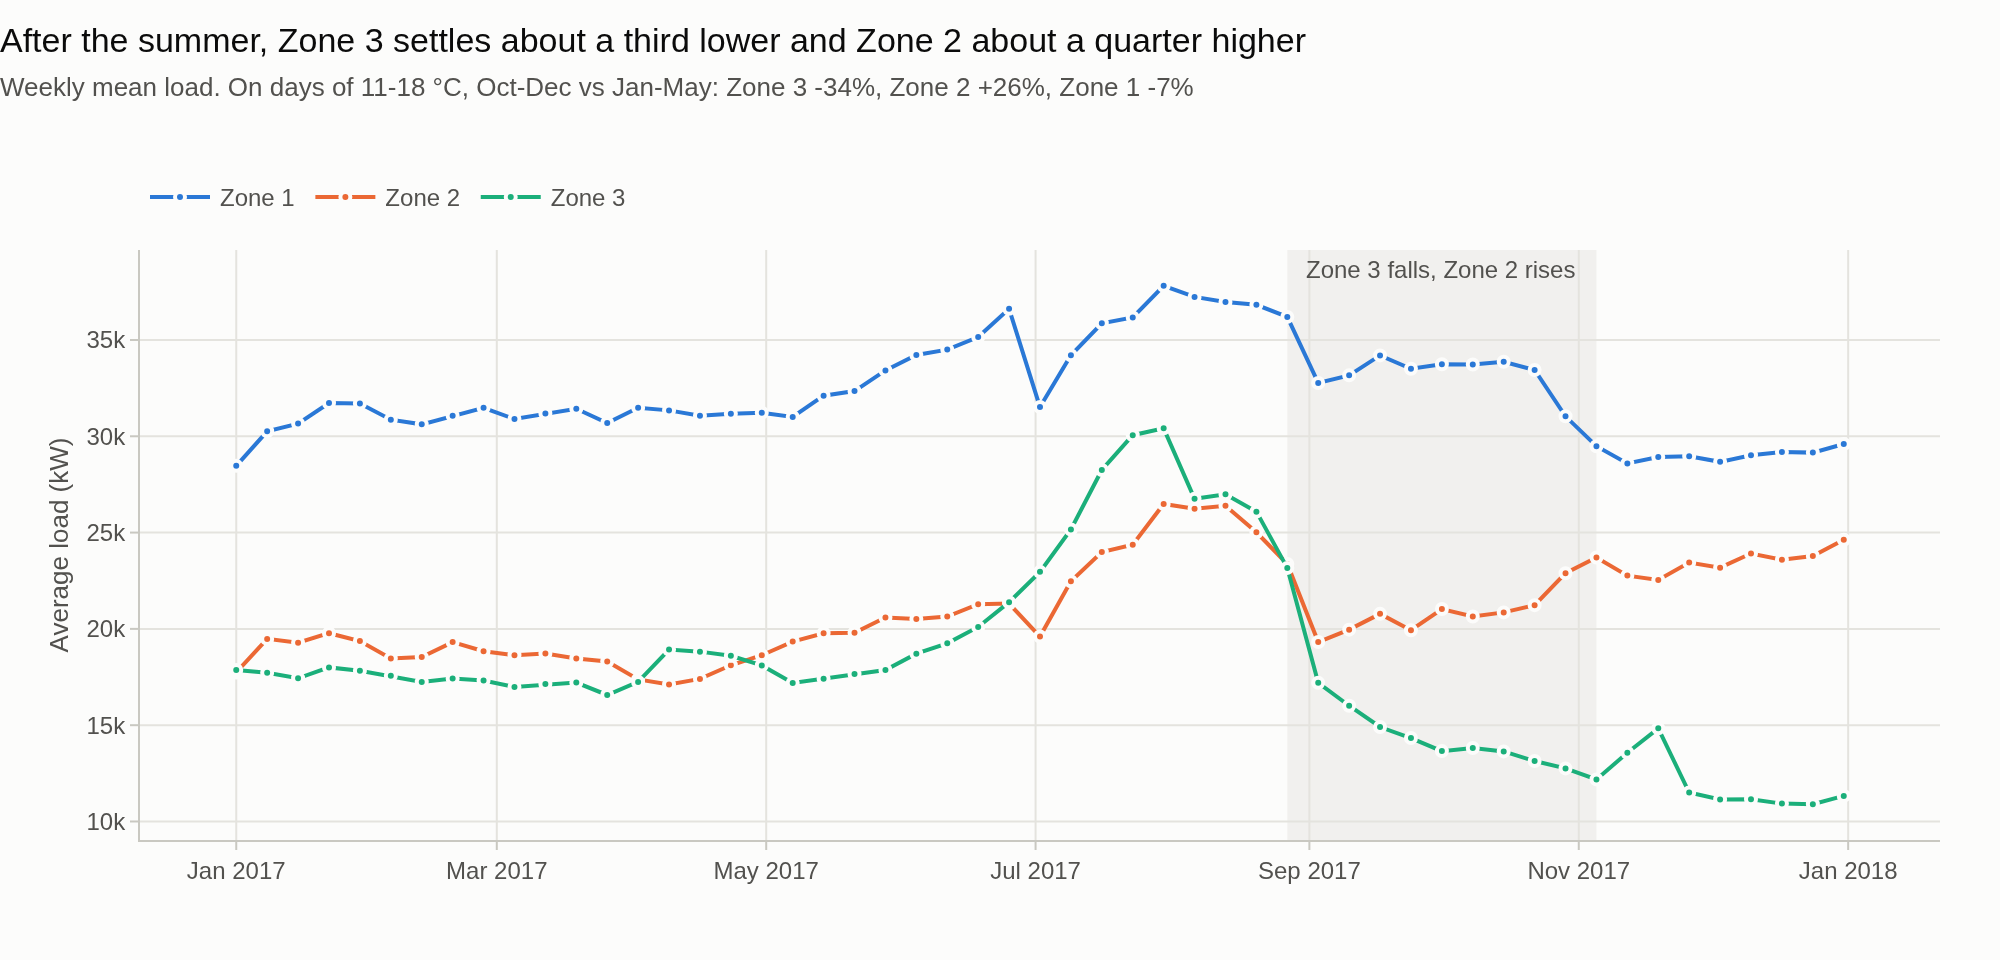

,spring_days,autumn_days,spring_mean_kW,autumn_mean_kW,change_pct,mann_whitney_p,spring_mean_temp,autumn_mean_temp
zone,,,,,,,,
Zone1,103,43,"31,155.879","29,020.481",-6.854,0.000,14.105,14.599
Zone2,103,43,"18,598.922","23,464.283",26.159,0.000,14.105,14.599
Zone3,103,43,"17,675.775","11,714.315",-33.727,0.000,14.105,14.599
Total,103,43,"67,430.575","64,199.078",-4.792,0.000,14.105,14.599


In [47]:
cool = daily["Temperature"].between(11, 18)
spring = daily[cool & (daily.Month <= 5)]
autumn = daily[cool & (daily.Month >= 10)]
shift = []
for z in ZONES + ["Total"]:
    mw = stats.mannwhitneyu(autumn[z], spring[z])
    shift.append({"zone": z, "spring_days": len(spring), "autumn_days": len(autumn),
                  "spring_mean_kW": spring[z].mean(), "autumn_mean_kW": autumn[z].mean(),
                  "change_pct": (autumn[z].mean() / spring[z].mean() - 1) * 100, "mann_whitney_p": mw.pvalue,
                  "spring_mean_temp": spring["Temperature"].mean(), "autumn_mean_temp": autumn["Temperature"].mean()})
level_shift = pd.DataFrame(shift).set_index("zone")
level_shift.to_csv(OUT / "autumn_level_shift.csv")
for z in ZONES:
    key(f"{z}_autumn_vs_spring_pct", level_shift.loc[z, "change_pct"], f"{z} mean on 11-18 C days, Oct-Dec vs Jan-May (%)")

wk_ = d_idx[ZONES].resample("W-SUN").mean()
fig = go.Figure()
for z in ZONES:
    fig.add_scatter(x=wk_.index, y=wk_[z], name=ZN(z), line_color=ch.ZONE_COLORS[z], mode="lines+markers", marker_size=5)
fig.add_vrect(x0="2017-08-27", x1="2017-11-05", fillcolor=ch.GRID, opacity=0.45, line_width=0, layer="below")
fig.add_annotation(x="2017-10-01", y=wk_.max().max(), text="Zone 3 falls, Zone 2 rises", showarrow=False,
                   font=dict(color=ch.TEXT_2, size=12), yshift=8)
fig.update_layout(title=ch.title("After the summer, Zone 3 settles about a third lower and Zone 2 about a quarter higher",
                                 "Weekly mean load. On days of 11-18 °C, Oct-Dec vs Jan-May: Zone 3 -34%, Zone 2 +26%, Zone 1 -7%"),
                  hovermode="x unified")
ch.kw_axis(fig)
ch.save(fig, "21_autumn_level_shift", height=480);
level_shift

**A structural change, not weather.** On days with the same mild temperature (11 to 18 °C, averaging 14.1 °C in spring and 14.6 °C in autumn), load in October to December compared with January to May was:
- **Zone 3: −34%**
- **Zone 2: +26%**
- Zone 1: −7%
- All three zones together: −5%

All of these differences are significant (Mann-Whitney p < 10⁻¹¹). Weather cannot explain them, because the temperatures are the same. The weekly chart shows Zone 3 dropping steeply at the end of August and continuing to fall through October, while Zone 2 steps up around the end of October, the same week Zone 1 steps down. Similar shifts on a smaller scale were seen on 20 April (Section 2).

The most likely explanation is **changes in which feeders or customers belong to which zone**: the network operator moving load between zones. That would also explain why the combined total changes much less than the individual zones. A second contributor for Zone 3 could be a seasonal population (for example coastal or tourist areas that empty after the summer). **The data cannot tell these apart**, and the network operator should confirm. Until then:
- Zone-level comparisons across the year, and Zone 3's very large seasonal swing in particular, partly reflect this change in the zones' composition, not only behaviour.
- **Forecasts for each zone should not assume January 2018 will look like January 2017.** December's level is likely the better starting point.

## 8. Validation

Three checks: (1) the headline results are rerun with the flagged spike readings removed, without Ramadan, without public holidays, and with median rather than mean aggregation; (2) `validation/independent_check.py` recomputes the key figures from the raw CSV with the Python standard library only; (3) the unit tests are run and the raw file's hash is checked again.

In [48]:
def headline(data_10, data_h, data_d):
    out = {}
    for z in ZONES:
        out[f"{z} mean (kW)"] = data_10[z].mean()
        out[f"{z} CV"] = data_10[z].std() / data_10[z].mean()
        out[f"{z} peak hour"] = data_h.groupby("Hour")[z].mean().idxmax()
        out[f"{z} rho temp (hourly)"] = stats.spearmanr(data_h["Temperature"], data_h[z]).statistic
        out[f"{z} rho temp (daily)"] = stats.spearmanr(data_d["Temperature"], data_d[z]).statistic
        out[f"{z} highest month"] = data_d.groupby("Month")[z].mean().idxmax()
    return out

base = headline(df, hourly, daily)
spike_any = df[[f"{z}_spike" for z in ZONES]].any(axis=1)
no_spike = df[~spike_any]
alt = {
    "Spike readings removed": (no_spike, pp.aggregate(no_spike, "h").dropna(subset=["Total"]), pp.aggregate(no_spike, "D")),
    "Ramadan excluded": (df[~df.IsRamadan], hourly[~hourly.IsRamadan], daily[~daily.IsRamadan]),
    "Public holidays excluded": (df[~df.IsHoliday], hourly[~hourly.IsHoliday], daily[~daily.IsHoliday]),
}
med_h = df.set_index("Datetime")[pp.ENV + ZONES].resample("h").median().reset_index().pipe(pp.add_time_features)
med_d = df.set_index("Datetime")[pp.ENV + ZONES].resample("D").median().reset_index().pipe(pp.add_time_features)
alt["Median instead of mean aggregation"] = (df, med_h, med_d)
robust = pd.DataFrame({"Main analysis": base} | {k: headline(*v) for k, v in alt.items()})
robust.to_csv(OUT / "robustness_checks.csv")
print(f"Readings removed as spikes: {spike_any.sum()} ({spike_any.mean():.2%})")
robust.round(3)

Readings removed as spikes: 429 (0.82%)


,Main analysis,Spike readings removed,Ramadan excluded,Public holidays excluded,Median instead of mean aggregation
Zone1 mean (kW),"32,344.971","32,327.492","32,106.603","32,390.135","32,344.971"
Zone1 CV,0.220,0.220,0.220,0.220,0.220
Zone1 peak hour,20.000,20.000,20.000,20.000,20.000
Zone1 rho temp (hourly),0.435,0.435,0.435,0.440,0.433
Zone1 rho temp (daily),0.724,0.724,0.688,0.744,0.635
Zone1 highest month,8.000,8.000,8.000,8.000,8.000
Zone2 mean (kW),"21,042.509","21,020.880","21,058.062","21,081.631","21,042.509"
Zone2 CV,0.247,0.247,0.250,0.247,0.247
Zone2 peak hour,20.000,20.000,20.000,20.000,20.000
Zone2 rho temp (hourly),0.380,0.380,0.393,0.388,0.379


**Results are stable.** Removing the 429 timestamps with a flagged spike in any zone (0.8%), excluding the 30 Ramadan days, excluding the 15 holidays, or aggregating with the median instead of the mean changes no conclusion:
- Zone means move by less than 1.0%, and the CVs by at most 0.007.
- The peak hour stays at 20:00 and the highest month stays August, August and July.
- The hourly temperature correlations stay within 0.02 of the main results.

The largest change is Zone 3's **daily** temperature correlation, which falls from 0.47 to 0.38 without Ramadan. This supports the conclusion that part of Zone 3's temperature association comes from the calendar.

In [49]:
key_figures = pd.DataFrame(KEY)
key_figures.to_csv(OUT / "key_figures.csv", index=False)
print(f"{len(key_figures)} key figures written to Outputs/key_figures.csv")
res = subprocess.run([sys.executable, "validation/independent_check.py"], capture_output=True, text=True)
print(res.stdout[-2500:])
assert res.returncode == 0, res.stderr

88 key figures written to Outputs/key_figures.csv


independent         0.093721
PASS  spearman_hourly_Temperature_Zone3  notebook         0.437884   independent         0.437884
PASS  spearman_hourly_Humidity_Zone3     notebook        -0.213243   independent        -0.213243
PASS  spearman_hourly_WindSpeed_Zone3    notebook         0.083639   independent         0.083639
PASS  pearson_daily_Temperature_Zone1    notebook         0.734696   independent         0.734696
PASS  pearson_daily_Humidity_Zone1       notebook        -0.208269   independent        -0.208269
PASS  pearson_daily_WindSpeed_Zone1      notebook         0.468108   independent         0.468108
PASS  pearson_daily_Temperature_Zone2    notebook         0.423259   independent         0.423259
PASS  pearson_daily_Humidity_Zone2       notebook        -0.212140   independent        -0.212140
PASS  pearson_daily_WindSpeed_Zone2      notebook         0.298496   independent         0.298496
PASS  pearson_daily_Temperature_Zone3    notebook         0.606950   independent         

In [50]:
res = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "--color=no", "tests"], capture_output=True, text=True)
print(res.stdout[-1500:])
assert res.returncode == 0
assert pp.sha256(pp.RAW_PATH) == pp.RAW_SHA256
print("Raw file unchanged after the run (SHA-256 re-checked).")

........................                                                 [100%]
24 passed in 2.88s

Raw file unchanged after the run (SHA-256 re-checked).


## 9. Limitations

1. **One year only.** With 364 days, the annual cycle happens once. Seasonal patterns cannot be separated from trend, and there is no way to tell whether 2017 was typical. All "seasonal" findings describe 2017.
2. **Uncertain definitions in the dictionary.** The load unit (treated as average kW), the diffuse-flow fields (solar radiation of uncertain definition) and wind speed (two-state, unit doubtful) are interpreted from the data's behaviour, not confirmed by the data owner. Patterns and correlations do not depend on the load unit, but derived energy totals do.
3. **Zone composition changes during the year.** Section 7.4 shows load moving between zones (20 April, and the September to November shifts). Comparing zones across months partly compares networks whose boundaries changed. The cause cannot be confirmed from this file.
4. **Serial dependence.** Readings are strongly autocorrelated, so effective sample sizes are small (as low as 21 for some correlations). Effective-sample-size adjustments, HAC standard errors and block bootstraps reduce this problem but rely on assumptions (for example the block length) and are approximations.
5. **Confounding.** Temperature, humidity and wind all move with the season, and so do Ramadan (in 2017), school holidays, tourism and daylight hours. The calendar controls in Section 6.5 are conservative and may also remove real weather effects. Without data on occupancy, tourism, tariffs, appliance use or customer mix, causes cannot be separated.
6. **No zone descriptions.** The data does not say what kinds of customers each zone serves. Interpretations such as "Zone 3 behaves like a residential or seasonal area" are inferences from load shapes, not facts.
7. **Time zone and daylight saving not documented.** Morocco used daylight saving time in 2017 (suspended during Ramadan). The file does not say whether timestamps are local clock time. The evening peak moves from 20:00 to 18:00 to 19:00 in late October, which could be a clock change, earlier sunsets, or both. Hour-of-day results could therefore be shifted by up to an hour in some periods.
8. **Single weather station.** One set of weather readings is applied to all three zones, so local differences in weather between zones are not captured.
9. **Missing 31 December.** The year has 364 days, which slightly affects December averages.

## 10. Findings, recommendations and the brief's questions answered

### Key findings

1. **The time of day is the biggest driver of load.** The daily cycle is the strongest and most regular pattern in every zone (MSTL seasonal strength ≥ 0.97). Load bottoms out at **06:00 to 07:00** and peaks at **20:00**, when average load is 1.9 times the morning trough (2.2 times in Zone 3). It accounts for 84% of the variation in Zone 1's hourly load and 70% in Zone 2's.
2. **Zone 1 carries the most load, and Zone 3 is the most volatile.** Zone 1 averages 32.3 MW (45% of the total) and is the highest zone on every day of the year. Zone 3 averages 17.8 MW (25%) but has the highest relative variability (CV 0.37, 1.5 to 1.7 times the others), the sharpest evening peak, and a load factor of only 0.38.
3. **Summer is the peak season, and Zone 3 depends most on it.** All zones peak in July or August. Zone 3's July load is 58% above its annual average and 2.6 times its December load; for Zone 1 the swing is +13% to −10%.
4. **Temperature is associated with load, but mostly through the season.** Above a daily mean of about 20 °C, total load rises by about 2.6 MW per °C. Once month, Ramadan and holidays are controlled for, the effect disappears for Zones 1 and 2 but remains for **Zone 3 (about +100 kW per °C, p < 0.001)**. Humidity and wind speed show no association that survives the seasonal controls. Wind's apparent link is a seasonal artefact. None of this shows causation.
5. **The week matters mainly on Sunday daytime.** Sunday load is 12% below weekdays in Zone 2 and 6% in Zone 1, while Zone 3 has no meaningful weekly cycle. The evening peak is almost the same every day.
6. **Calendar events change the shape of demand.** During Ramadan, night-time load (01:00 to 03:59) was 45% higher than in the weeks before. Public holidays are among the most unusual days of the year, mostly with lower load.
7. **The zones' base loads shifted after the summer.** At the same mild temperatures, autumn load was 34% lower than spring in Zone 3 and 26% higher in Zone 2, which points to load being moved between zones (as seen directly on 20 April), not to weather.

### What this means for the energy management organisation

- **Peak capacity is an evening problem.** The binding constraint is 19:00 to 21:00, on summer days in particular. Reducing or shifting evening demand is worth more than reducing average consumption.
- **Zone 3 needs the most headroom per unit of demand.** With a load factor of 0.38, it needs capacity of about 2.7 times its average load, and that capacity sits idle most of the year.
- **Weather alone is a weak planning signal for Zones 1 and 2,** whose demand follows the clock and the calendar. For Zone 3, hot weather is a real additional risk within the summer.
- **Zone-level history must be read together with network changes.** Without records of when load was moved between zones, a zone's history can mislead.

### Recommendations

1. **Plan capacity and demand response around the 20:00 summer peak, starting with Zone 3.** Use the change-point model (about +1.7 MW in Zone 3, and about +2.6 MW across all zones, for each °C of daily mean temperature above about 20 °C) to trigger alerts. Target demand response such as time-of-use tariffs, or shifting flexible loads such as water heating, at 18:00 to 22:00 in June to September.
2. **Schedule planned maintenance and outages in low-demand windows:** 03:00 to 07:00, Sunday daytime in Zones 1 and 2, public holidays, and, for Zone 3, October to March. Avoid July and August evenings and Ramadan nights.
3. **Build forecasts with calendar features, not month alone.** Include hour, day of week, public holidays and a movable **Ramadan** flag (Ramadan moves about 11 days earlier each year), plus lagged load (lags of 1, 2 and 24 hours carry most of the information). Add temperature as a hinge term above about 20 °C for Zone 3. This is direct input for the Machine Learning track.
4. **Record network reconfigurations, and confirm the data definitions with the data owner.** Keep a log of feeder transfers between zones with dates, and use it to correct zone histories. Confirm the load unit (kW versus kWh), the meaning of the two diffuse-flow fields, the wind-speed sensor's behaviour, and whether timestamps include daylight saving.
5. **Collect at least two more years of data** before treating any seasonal pattern or temperature threshold as stable, and re-estimate the change-point models each year.

### The brief's questions answered

| Question | Answer |
|---|---|
| 1. Patterns across the three zones | A strong daily cycle shared by all zones (trough 06:00 to 07:00, peak 20:00), a summer peak in all zones, a Sunday dip in Zones 1 and 2, higher load on Ramadan nights, and dips on holidays. The zones share the daily timing but differ in size, seasonality and weekly behaviour. |
| 2. Highest and lowest hours and days | Highest at 20:00 (19:00 to 21:00); lowest at 06:00 (Zones 1 and 2) and 07:00 (Zone 3). Sunday is the lowest day in Zones 1 and 2 (−6% and −12% against weekdays). In Zone 3, Saturday and Sunday are slightly higher than weekdays. |
| 3. Variation across months | Highest in July and August in every zone (August for Zones 1 and 2, July for Zone 3). Lowest in November and December (Zone 1), April (Zone 2) and December (Zone 3). Swing between the highest and lowest month: 1.26 times for Zone 1, 1.40 times for Zone 2, 2.55 times for Zone 3. |
| 4. Temperature, humidity and wind | Temperature: moderate positive association (ρ ≈ 0.4), with a threshold near 20 °C, mostly through the seasonal cycle; it survives calendar controls only in Zone 3. Humidity: weak negative, which is temperature viewed from the other side. Wind: negligible, and seasonal. These are associations, not causes. |
| 5. Highest and lowest zone | Highest: Zone 1 (32.3 MW average, 45% of the total). Lowest: Zone 3 (17.8 MW, 25%), although Zone 3 exceeds Zone 2 on many summer days. |
| 6. Using history for planning | Peak-capacity planning for summer evenings; maintenance windows; forecasting with calendar features and Ramadan; temperature-triggered alerts for Zone 3; tracking network changes (see Recommendations). |

### Contribution to the other Week 5 tracks

- **Data Analytics:** `Outputs/hourly_consumption.csv`, `daily_consumption.csv`, `hourly_profile.csv`, `weekday_profile.csv` and `monthly_profile.csv` provide ready-made aggregates with consistent definitions (average kW, never summed).
- **Machine Learning:** hourly aggregation with every hour complete, lags 1, 2 and 24 suggested by the PACF, the Ramadan and holiday flags, the change-point temperature term, and a warning about Zone 3's autumn level shift for chronological train/test splits.
- **Generative AI:** `Outputs/key_figures.csv` is an independently verified answer key for numerical questions, and Sections 1 and 9 list the interpretation notes and limitations the assistant should state.
- **Project Management:** the data-dictionary issues and the network reconfiguration risk are open items to take up with the data owner.